# Table of Contents

- [Color Palette](#color-palette)
- [Plot Settings](#plot-settings)
- [Accuracy by Dataset](#accuracy-by-dataset)
- [Figure 3 & 4: Bulk Accuracy Scoring](#figure-3-4-bulk-accuracy-scoring)
  - [Figure 3a: Bulk Accuracy](#figure-3a-bulk-accuracy)
  - [Figure 3b: Bulk Accuracy by HLA Class](#figure-3b-bulk-accuracy-by-hla-class)
  - [Figure 4: Fraction of Calls](#figure-4-fraction-of-calls)
  - [Figure 3: assembled figure](#figure-3-assembled-figure)
- [Figure 5: Accuracy by Locus](#figure-5-accuracy-by-locus)
  - [Figure 5: locus accuracy heatmap](#figure-5-locus-accuracy-heatmap)
- [Figure 6 & 7: misclassification rate](#figure-6-7-misclassification-rate)
  - [Figure 6: Miscalled Alleles by Locus](#figure-6-miscalled-alleles-by-locus)
  - [Figure 6: assembled figure](#figure-6-assembled-figure)
  - [Figure 7: Alleles that are hard for every caller](#figure-7-alleles-that-are-hard-for-every-caller)
  - [Supplementary Figure 7a-b: per-dataset breakdown of the top-20 alleles](#supplementary-figure-7a-b-per-dataset-breakdown-of-the-top-20-alleles)
  - [Shared constants](#shared-constants)
  - [Panels a, b -- top-20 alleles (ranked on D1-D6), broken down by dataset](#panels-a-b-top-20-alleles-ranked-on-d1-d6-broken-down-by-dataset)
  - [Supplementary Figure 7b: each dataset's own top-N ranking](#supplementary-figure-7b-each-datasets-own-top-n-ranking)
  - [Cross-dataset scorability of the top-20 alleles](#cross-dataset-scorability-of-the-top-20-alleles)
  - [Supplementary Figure 7a-d with the allele-level miss rate](#supplementary-figure-7a-d-with-the-allele-level-miss-rate)
- [Figure 8: read length accuracy](#figure-8-read-length-accuracy)
  - [Read-length cohort confound](#read-length-cohort-confound)
  - [Figure 8: Accuracy Against Read Length](#figure-8-accuracy-against-read-length)
- [Figure 9: Accuracy between Europeans and Yoruban Samples](#figure-9-accuracy-between-europeans-and-yoruban-samples)
  - [Ancestry Bulk Accuracy](#ancestry-bulk-accuracy)
  - [Ancestry Bulk Accuracy by Class](#ancestry-bulk-accuracy-by-class)
  - [Figure 9: Europe vs Yoruba accuracy (D1)](#figure-9-europe-vs-yoruba-accuracy-d1)
- [Figure 10: Ancestral Accuracy by Locus](#figure-10-ancestral-accuracy-by-locus)
  - [Figure 10: locus accuracy by ancestry (D1)](#figure-10-locus-accuracy-by-ancestry-d1)
- [Figure 11: Ancestral Misclassification Rate](#figure-11-ancestral-misclassification-rate)
  - [Figure 11: misclassification rate chart, setup + plot](#figure-11-misclassification-rate-chart-setup-plot)
- [Supplementary Figure 9: Europe split by source population](#supplementary-figure-9-europe-split-by-source-population)
  - [Supplementary Figure 9: European sub-populations](#supplementary-figure-9-european-sub-populations)
- [Figure 12: Memory and CPU](#figure-12-memory-and-cpu)
- [Supplementary: per-dataset results, D1-D8](#supplementary-per-dataset-results-d1-d8)
  - [D7 scRNA-seq performance summary](#d7-scrna-seq-performance-summary)
  - [D1-subset unmapped-reads-augmented performance](#d1-subset-unmapped-reads-augmented-performance)
- [Figure 14: No-Call Rate Analysis](#figure-14-no-call-rate-analysis)
  - [Figure 14 Interpretation](#figure-14-interpretation)
- [Main figures](#main-figures)


In [1]:
import warnings
warnings.filterwarnings("ignore", message="Glyph .* missing from font")

import pandas as pd
import re
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np

from matplotlib.ticker import FuncFormatter
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

##### Helper Functions


Every section below uses this single set of scoring helpers (`reformat_allele`, `get_dynamic_loci`, `score_pair`, `get_pr_loci`, `calculate_accuracy`); they implement the 3-outcome scoring contract (correct / miscalled / no-call).

### New Accuracy Script


In [2]:
def reformat_allele(allele: str, resolution: int = 2) -> str:
    # Keep only the first comma-separated entry (some tools list several tied variants).
    allele = allele.split(",")[0]
    # A literal "xx" 2nd field (HLA nomenclature for "unresolved") returns None
    # instead of being scored as an unwinnable miss.
    a = allele.strip()
    if "*" not in a:
        return a
    gene, rest = a.split("*", 1)
    parts = rest.split(":")
    if resolution == 1:
        return f"{gene}*{parts[0]}"
    if len(parts) < 2:
        return f"{gene}*{parts[0]}"
    if parts[1].lower() == "xx":
        return None
    return f"{gene}*{parts[0]}:{parts[1]}"

In [3]:
def get_dynamic_loci(gs_df: pd.DataFrame) -> list:
    return sorted({c.split(".")[0] for c in gs_df.columns[1:]})

In [5]:
def score_pair(gs_raw, pr_raw, resolution=2):
    # 3-outcome contract: correct/miscalled/no_call. No "novel" bucket.
    pr_raw = [None if isinstance(a, str) and a.strip().lower() in ("na", "no") else a
              for a in pr_raw]
    gs_set = {reformat_allele(a, resolution) for a in gs_raw}
    gs_set.discard(None)
    if not gs_set:
        return None
    if len(pr_raw) == 0:
        pair = [None, None]
    elif len(pr_raw) == 1:
        pair = [pr_raw[0], pr_raw[0]]
    else:
        pair = pr_raw[:2]
    correct = miscalled = no_call = 0
    for allele in pair:
        if allele is None:
            no_call += 1
        else:
            fmt = reformat_allele(allele, resolution)
            if fmt is not None and fmt in gs_set:
                correct += 1
            else:
                miscalled += 1
    return correct, miscalled, no_call

In [6]:
def get_pr_loci(pr_df: pd.DataFrame) -> set:
    s=set()
    for L in ["A","B","C","DRB1","DQB1"]:
        if f"{L}_pre" in pr_df.columns or f"{L}.1_pre" in pr_df.columns:
            s.add(L)
    return s

In [ ]:
def calculate_accuracy(gs, pre_file, resolution=2):
    """Bulk accuracy of one prediction file against a gold standard given as a
    DataFrame (e.g. a population subset) or a CSV path. Returns
    (accuracy, correct, total, no_call, miscalled); accuracy is NaN if nothing is scorable."""
    gs_df = gs.copy() if isinstance(gs, pd.DataFrame) else pd.read_csv(gs, dtype=str)
    pr_df = pd.read_csv(pre_file, dtype=str)
    id_gs, id_pr = gs_df.columns[0], pr_df.columns[0]
    gs_df[id_gs] = gs_df[id_gs].str.strip()
    pr_df[id_pr] = pr_df[id_pr].str.strip()
    pr_df = pr_df.rename(columns={c: f"{c}_pre" for c in pr_df.columns if c != id_pr})
    loci = get_dynamic_loci(gs_df)
    merged = pd.merge(gs_df, pr_df, left_on=id_gs, right_on=id_pr, how="inner")
    total = correct = mis = nc = 0
    for _, row in merged.iterrows():
        for L in loci:
            gs_raw = []
            for suf in ("", ".1"):
                col = f"{L}{suf}"
                if col in row and pd.notna(row[col]):
                    gs_raw += [x.strip() for x in str(row[col]).split("/")]
            if not gs_raw:
                continue
            pr_raw = []
            for suf in ("_pre", ".1_pre"):
                col = f"{L}{suf}"
                if col in row and pd.notna(row[col]):
                    pr_raw += [x.strip() for x in str(row[col]).split("/")]
            result = score_pair(gs_raw, pr_raw, resolution)
            if result is None:
                continue
            total += 2
            c, m, z = result
            correct += c
            mis += m
            nc += z
    return (correct / total if total else np.nan), correct, total, nc, mis

In [7]:
def aggregate_counts_per_tool_locus(tools, ds_nums, gs_dir, pr_dir, resolution=2):
    # 3-outcome contract, no filter_option.
    classical=["A","B","C","DRB1","DQB1"]
    counts={t:{L:{"correct":0,"miscalled":0,"no_call":0,"total_calls":0}
               for L in classical}
            for t in tools}
    for t in tools:
        for ds in ds_nums:
            try:
                gs_df=pd.read_csv(f"{gs_dir}/{ds}_gs.csv",dtype=str)
                pr_df=pd.read_csv(f"{pr_dir}/{t}_d{ds}.csv",dtype=str)
            except FileNotFoundError:
                continue

            # strip IDs
            gs_df.iloc[:,0]=gs_df.iloc[:,0].str.strip()
            pr_df.iloc[:,0]=pr_df.iloc[:,0].str.strip()
            # rename pr columns
            rename={c:f"{c}_pre" for c in pr_df.columns if c!=pr_df.columns[0]}
            pr_df=pr_df.rename(columns=rename)

            supported=get_pr_loci(pr_df)
            all_loci = get_dynamic_loci(gs_df)
            merged   = pd.merge(gs_df, pr_df,
                                left_on=gs_df.columns[0],
                                right_on=pr_df.columns[0],
                                how="inner")

            for _,row in merged.iterrows():
                # penalize unsupported loci
                for L in classical:
                    if L in all_loci and L not in supported:
                        counts[t][L]["total_calls"]+=2
                        counts[t][L]["no_call"]    +=2

                # score supported
                for L in sorted(supported):
                    if L not in all_loci:
                        continue
                    # GS alleles
                    gs_raw=[]
                    for suf in ("",".1"):
                        col=f"{L}{suf}"
                        if col in row and pd.notna(row[col]):
                            gs_raw += [x.strip() for x in str(row[col]).split("/")]
                    if not gs_raw:
                        continue
                    # PR alleles
                    pr_raw=[]
                    for suf in ("_pre",".1_pre"):
                        col=f"{L}{suf}"
                        if col in row and pd.notna(row[col]):
                            pr_raw += [x.strip() for x in str(row[col]).split("/")]
                    result = score_pair(gs_raw, pr_raw, resolution)
                    if result is None:
                        # ":xx" (field-2-unresolved) GS tokens excluded from scoring.
                        continue
                    counts[t][L]["total_calls"]+=2
                    c, m, nc = result
                    counts[t][L]["correct"]   +=c
                    counts[t][L]["miscalled"] +=m
                    counts[t][L]["no_call"]   +=nc
    return counts

In [8]:
def compute_all_metrics(*, tools, dataset_nums, gs_dir, pr_dir,
                        resolution=2,
                        with_raw_counts=False):
    # 3-outcome contract, no filter_option.
    classI = ["A","B","C"]
    classII= ["DRB1","DQB1"]
    by_tool = aggregate_counts_per_tool_locus(
        tools, dataset_nums, gs_dir, pr_dir, resolution
    )
    rows=[]
    for t,lc in by_tool.items():
        ci   = sum(lc[L]["correct"]    for L in classI)
        misI = sum(lc[L]["miscalled"]  for L in classI)
        ncI  = sum(lc[L]["no_call"]    for L in classI)
        callsI=sum(lc[L]["total_calls"]for L in classI)

        cii   = sum(lc[L]["correct"]    for L in classII)
        misII = sum(lc[L]["miscalled"]  for L in classII)
        ncII  = sum(lc[L]["no_call"]    for L in classII)
        callsII=sum(lc[L]["total_calls"]for L in classII)

        correct_all = ci + cii
        calls_all   = callsI + callsII
        coverage    = sum(1 for L in ["A","B","C","DRB1","DQB1"]
                          if lc[L]["total_calls"]>0)/5.0

        base = {
            "Tool":t,
            "ClassI_acc":  None if callsI==0    else ci          /callsI,
            "ClassII_acc": None if callsII==0   else cii         /callsII,
            "Overall_acc": None if calls_all==0 else correct_all /calls_all,
            "Coverage_frac":coverage
        }
        if with_raw_counts:
            base.update({
                "ClassI_Correct":   ci,   "ClassI_Miscalled": misI,
                "ClassI_NoCall":    ncI,
                "ClassI_TotalCalls":callsI,
                "ClassII_Correct":  cii,  "ClassII_Miscalled": misII,
                "ClassII_NoCall":   ncII,
                "ClassII_TotalCalls":callsII,
                "TotalCorrect":     correct_all,
                "TotalMiscalled":   misI+misII,
                "TotalNoCall":      ncI+ncII,
                "TotalCalls":       calls_all
            })
        rows.append(base)
    return pd.DataFrame(rows)

# Color Palette

In [9]:
# Muted, print-appropriate colour set -- matches the Okabe-Ito-family /
# seaborn "muted"-style palettes actually used in Nature Methods/Biotechnology
# and Genome Biology benchmarking figures (Mitchell et al. 2020; Park et al.
# 2025), replacing the earlier saturated ColorBrewer Set1/Set3 choice.
palette = {
    # HLA name fields
    '1st field':   '#A8C98A',
    '2nd field':   '#4C8C5B',

    # Call types -- neutral for correct, accent for the two error modes
    'Correct':     '#7F7F7F',
    'Miscalled':   '#C44E52',
    'No-call':     '#D9D9D9',

    # DRB1 cell-type comparison (Figure 3d)
    'LCL':           '#4D4D4D',
    'Blood-derived': '#8CA7C4',

    # Locus labels -- Okabe-Ito (Wong, Nature Methods 2011), colour-blind-safe
    'A':           '#E69F00',
    'B':           '#56B4E9',
    'C':           '#009E73',
    'DQB1':       '#CC79A7',
    'DRB1':        '#D55E00',

    # Populations
    'Europe':      '#4C78A8',
    'Yoruba':      '#B3514A',

    # HLA‐caller tools -- 12 evenly-spaced muted hues (HUSL, s=0.55, l=0.55)
    'Optitype':        '#d35a71',
    'HLA-HD':          '#ae7556',
    'PHLAT':           '#948056',
    'HLAforest':       '#7f8656',
    'arcasHLA':        '#5f8e56',
    'HLAMiner':        '#588d76',
    'rna2hla':         '#5a8b86',
    'seq2HLA':         '#5c8995',
    'HLAvbseq':        '#5f86ad',
    'Hisat-Genotype':  '#8877c6',
    'HLApers':         '#b563be',
    'T1K':             '#c55e9e',
}

# Same caller colours keyed by the internal tool key used in every data frame.
TOOL_COLOR = {
    "optitype": palette["Optitype"], "hlahd": palette["HLA-HD"], "phlat": palette["PHLAT"],
    "hlaforest": palette["HLAforest"], "arcas": palette["arcasHLA"], "hlaminer": palette["HLAMiner"],
    "rna2hla": palette["rna2hla"], "seq2hla": palette["seq2HLA"], "hlavbseq": palette["HLAvbseq"],
    "hisat": palette["Hisat-Genotype"], "hlapers": palette["HLApers"], "T1K": palette["T1K"],
}


# Plot Settings

In [10]:
# Every panel is drawn at its final print size (89 mm single column, 183 mm double column,
# <= 170 mm tall) so 5-7 pt text and 0.5 pt lines are what the journal prints. Titles and
# explanatory notes live in figures/LEGENDS.md, not inside the images.
MM = 1 / 25.4
COL1, COL2, MAX_H = 89 * MM, 183 * MM, 170 * MM


def apply_nature_style():
    sns.set_theme(context="paper", style="ticks")
    plt.rcParams.update({
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial", "Liberation Sans", "DejaVu Sans"],
        "font.size": 6, "axes.titlesize": 6.5, "axes.titleweight": "normal",
        "axes.labelsize": 6.5, "xtick.labelsize": 6, "ytick.labelsize": 6,
        "legend.fontsize": 6, "legend.title_fontsize": 6,
        "axes.linewidth": 0.5, "axes.edgecolor": "black", "axes.labelcolor": "black",
        "text.color": "black", "xtick.color": "black", "ytick.color": "black",
        "xtick.major.width": 0.5, "ytick.major.width": 0.5,
        "xtick.major.size": 2.5, "ytick.major.size": 2.5,
        "xtick.major.pad": 2, "ytick.major.pad": 2, "axes.labelpad": 2.5, "axes.titlepad": 3,
        "axes.spines.top": False, "axes.spines.right": False,
        "lines.linewidth": 0.8, "lines.markersize": 3, "patch.linewidth": 0,
        "legend.frameon": False, "legend.handlelength": 1.0, "legend.handleheight": 0.7,
        "legend.handletextpad": 0.4, "legend.borderaxespad": 0.2, "legend.borderpad": 0.2,
        "legend.columnspacing": 0.9, "legend.labelspacing": 0.3,
        "figure.dpi": 150, "savefig.dpi": 300,
        "pdf.fonttype": 42, "ps.fonttype": 42, "svg.fonttype": "none",
        "axes.unicode_minus": False, "svg.hashsalt": "hla-benchmark",
    })


apply_nature_style()

# Published tool names (README, tool repositories); data frames keep the internal keys.
TOOL_NAME = {
    "arcas": "arcasHLA", "optitype": "OptiType", "seq2hla": "seq2HLA", "hlaminer": "HLAminer",
    "phlat": "PHLAT", "hlavbseq": "HLA-VBSeq", "hlahd": "HLA-HD", "hisat": "HISAT-genotype",
    "hlaforest": "HLAforest", "hlapers": "HLApers", "T1K": "T1K", "rna2hla": "RNA2HLA",
}
LOCI_ORDER = ["A", "B", "C", "DRB1", "DQB1"]
ERRBAR = dict(fmt="none", ecolor="black", elinewidth=0.5, capsize=1.2, capthick=0.5)


def tool_labels(keys):
    return [TOOL_NAME.get(k, k) for k in keys]


def label_panel(fig_or_subfig, letter):
    fig_or_subfig.text(0, 1, letter, fontsize=8, fontweight="bold", ha="left", va="top")


# No creation date and a fixed svg id salt, so re-running the notebook leaves unchanged
# figures byte-identical.
SAVE_METADATA = {"pdf": {"CreationDate": None}, "svg": {"Date": None}, "png": {}}


def save_fig(fig, stem, folder="../../figures"):
    for ext in ("pdf", "svg", "png"):
        fig.savefig(f"{folder}/{stem}.{ext}", bbox_inches="tight", pad_inches=0.02, metadata=SAVE_METADATA[ext])


# Accuracy by Dataset

# Figure 3 & 4: Bulk Accuracy Scoring

In [11]:
# ─────────────────────────────────────────────────────────────────────────────
# 2) PULL METRICS & BUILD df_plot
# ─────────────────────────────────────────────────────────────────────────────

tools    = ["arcas","optitype","seq2hla","hlaminer",
            "phlat","hlavbseq","hlahd","hisat","hlaforest","hlapers","T1K","rna2hla"]
ds_nums  = list(range(1,7))
gs_dir   = "../../data/gold_standard"
pr_dir   = "../../data/interim/standard"

# One accuracy number per (tool, field). df_1/df_2 carry raw counts for
# Figure 4; df_plot carries just what the bar charts need.
df_1 = compute_all_metrics(tools=tools, dataset_nums=ds_nums,
                            gs_dir=gs_dir, pr_dir=pr_dir,
                            resolution=1, with_raw_counts=True)
df_2 = compute_all_metrics(tools=tools, dataset_nums=ds_nums,
                            gs_dir=gs_dir, pr_dir=pr_dir,
                            resolution=2, with_raw_counts=True)

def prep(df, field):
    d = df.copy()
    d["Field"] = field
    d["NoCallRate"] = d["TotalNoCall"] / d["TotalCalls"]
    d = d.rename(columns={"Overall_acc": "Accuracy"})
    return d

df_plot = pd.concat([prep(df_1, "1-field"), prep(df_2, "2-field")], ignore_index=True)

# One caller order for every figure: ascending 2-field accuracy (horizontal bars put the best on top).
TOOL_ORDER = (df_plot[df_plot["Field"] == "2-field"].set_index("Tool")["Accuracy"]
              .sort_values().index.tolist())


### Uncertainty for Figures 3a, 3b and 3-4

Error bars are 95% bootstrap intervals from resampling samples (not individual calls) 2000 times, since a sample's alleles and loci aren't independent. OptiType has no Class II interval since it doesn't call those loci.


In [12]:
def per_sample_counts(tools, ds_nums, gs_dir, pr_dir, resolution=2):
    classical = ["A", "B", "C", "DRB1", "DQB1"]
    rows = []
    for t in tools:
        for ds in ds_nums:
            try:
                gs_df = pd.read_csv(f"{gs_dir}/{ds}_gs.csv", dtype=str)
                pr_df = pd.read_csv(f"{pr_dir}/{t}_d{ds}.csv", dtype=str)
            except FileNotFoundError:
                continue
            gs_df.iloc[:, 0] = gs_df.iloc[:, 0].str.strip()
            pr_df.iloc[:, 0] = pr_df.iloc[:, 0].str.strip()
            pr_df = pr_df.rename(columns={c: f"{c}_pre" for c in pr_df.columns if c != pr_df.columns[0]})
            supported = get_pr_loci(pr_df)
            all_loci = get_dynamic_loci(gs_df)
            id_col = gs_df.columns[0]
            merged = pd.merge(gs_df, pr_df, left_on=id_col, right_on=pr_df.columns[0], how="inner")
            for _, row in merged.iterrows():
                sample = row[id_col]
                for L in classical:
                    if L in all_loci and L not in supported:
                        rows.append((t, ds, sample, L, 0, 0, 2, 2))
                for L in sorted(supported):
                    if L not in all_loci:
                        continue
                    gs_raw, pr_raw = [], []
                    for suf in ("", ".1"):
                        col = f"{L}{suf}"
                        if col in row and pd.notna(row[col]):
                            gs_raw += [x.strip() for x in str(row[col]).split("/")]
                    if not gs_raw:
                        continue
                    for suf in ("_pre", ".1_pre"):
                        col = f"{L}{suf}"
                        if col in row and pd.notna(row[col]):
                            pr_raw += [x.strip() for x in str(row[col]).split("/")]
                    result = score_pair(gs_raw, pr_raw, resolution)
                    if result is None:
                        continue
                    c, m, nc = result
                    rows.append((t, ds, sample, L, c, m, nc, 2))
    return pd.DataFrame(rows, columns=["Tool", "Dataset", "Sample", "Locus",
                                       "correct", "miscalled", "no_call", "total"])


_runs_d1 = pd.read_csv("../../data/input/archive/SraRunTableD1.txt", dtype=str)
_run2bio = dict(zip(_runs_d1["Run"], _runs_d1["BioSample"]))


def add_individual(ps):
    ps = ps.copy()
    ps["Individual"] = [_run2bio.get(str(s), str(s)) if int(ds) == 1 else str(s)
                        for s, ds in zip(ps["Sample"], ps["Dataset"])]
    return ps


def boot_ci(ps, loci, n_boot=2000, seed=20260925):
    d = ps[ps.Locus.isin(loci)]
    g = d.groupby(["Tool", "Dataset", "Individual"])[["correct", "total"]].sum().reset_index()
    rng = np.random.default_rng(seed)
    out = {}
    for tool, sub in g.groupby("Tool"):
        C, T = sub.correct.values, sub.total.values
        if T.sum() == 0:
            continue
        n = len(sub)
        W = rng.multinomial(n, np.full(n, 1.0 / n), size=n_boot)
        num, dd = W @ C, W @ T
        acc = num[dd > 0] / dd[dd > 0]
        lo, hi = np.percentile(acc, [2.5, 97.5])
        out[tool] = (C.sum() / T.sum(), lo, hi)
    return pd.DataFrame(out, index=["acc", "lo", "hi"]).T


CLASS_I_LOCI, CLASS_II_LOCI = ["A", "B", "C"], ["DRB1", "DQB1"]
ALL5_LOCI = CLASS_I_LOCI + CLASS_II_LOCI
ps1 = per_sample_counts(tools, ds_nums, gs_dir, pr_dir, 1)
ps2 = per_sample_counts(tools, ds_nums, gs_dir, pr_dir, 2)
ps1 = add_individual(ps1)
ps2 = add_individual(ps2)

for ps, dfx, name in ((ps1, df_1, "1-field"), (ps2, df_2, "2-field")):
    g = ps.groupby("Tool")[["correct", "miscalled", "no_call", "total"]].sum()
    for _, r in dfx.iterrows():
        s = g.loc[r["Tool"]]
        assert (s["correct"], s["miscalled"], s["no_call"], s["total"]) == \
               (r["TotalCorrect"], r["TotalMiscalled"], r["TotalNoCall"], r["TotalCalls"]), (name, r["Tool"])

ci1 = boot_ci(ps1, ALL5_LOCI)
ci2 = boot_ci(ps2, ALL5_LOCI)
ci_class = {(f, k): boot_ci(ps, loci)
            for f, ps in (("1-field", ps1), ("2-field", ps2))
            for k, loci in (("ClassI", CLASS_I_LOCI), ("ClassII", CLASS_II_LOCI))}

for ci, field in ((ci1, "1-field"), (ci2, "2-field")):
    ref = df_plot.query("Field==@field").set_index("Tool")["Accuracy"]
    assert np.allclose(ci["acc"].loc[ref.index].astype(float), ref.astype(float)), field
print("per-sample table reconciles with df_plot; intervals built for", ", ".join(sorted(ci2.index)))


per-sample table reconciles with df_plot; intervals built for T1K, arcas, hisat, hlaforest, hlahd, hlaminer, hlapers, hlavbseq, optitype, phlat, rna2hla, seq2hla


## Figure 3a: Bulk Accuracy

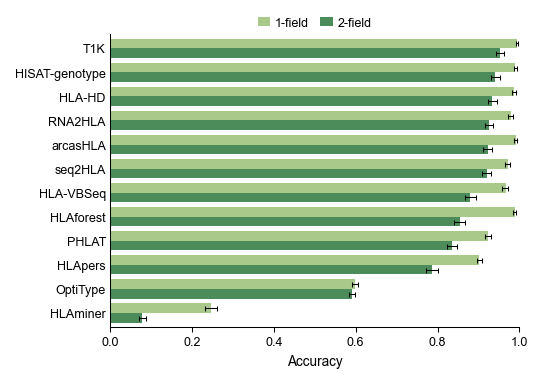

In [13]:
def draw_bulk_accuracy(ax, order=None, legend=True):
    order = order or TOOL_ORDER
    y = np.arange(len(order))
    h = 0.4
    for off, ci, key, lab in ((h / 2, ci1, "1st field", "1-field"), (-h / 2, ci2, "2nd field", "2-field")):
        c = ci.loc[order]
        ax.barh(y + off, c["acc"], height=h, color=palette[key], label=lab)
        ax.errorbar(c["acc"], y + off, xerr=[c["acc"] - c["lo"], c["hi"] - c["acc"]], **ERRBAR)
    ax.set_yticks(y)
    ax.set_yticklabels(tool_labels(order))
    ax.tick_params(axis="y", length=0)
    ax.set_xlim(0, 1)
    ax.set_ylim(-0.6, len(order) - 0.4)
    ax.set_xlabel("Accuracy")
    if legend:
        ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2)


fig, ax = plt.subplots(figsize=(COL1, 62 * MM), layout="constrained")
draw_bulk_accuracy(ax)
save_fig(fig, "fig3a_bulk_accuracy")
plt.show()


## Figure 3b: Bulk Accuracy by HLA Class


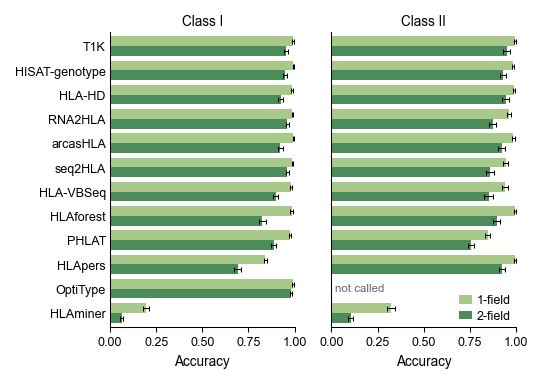

In [14]:
def draw_class_accuracy(ax_I, ax_II, order=None, legend=True):
    order = order or TOOL_ORDER
    y = np.arange(len(order))
    h = 0.4
    for ax, key, name in ((ax_I, "ClassI", "Class I"), (ax_II, "ClassII", "Class II")):
        for off, field, pkey in ((h / 2, "1-field", "1st field"), (-h / 2, "2-field", "2nd field")):
            c = ci_class[(field, key)].reindex(order)
            ok = (c["acc"].notna() & (c["hi"] > 0)).values  # hi == 0: tool makes no calls in this class
            ax.barh((y + off)[ok], c["acc"].values[ok], height=h, color=palette[pkey], label=field)
            ax.errorbar(c["acc"].values[ok], (y + off)[ok],
                        xerr=[(c["acc"] - c["lo"]).values[ok], (c["hi"] - c["acc"]).values[ok]], **ERRBAR)
            for yi, has in zip(y, ok):
                if not has and field == "2-field":
                    ax.text(0.02, yi, "not called", va="center", ha="left", fontsize=5.5, color="#666666")
        ax.set_title(name)
        ax.set_xlim(0, 1)
        ax.set_ylim(-0.6, len(order) - 0.4)
        ax.set_xlabel("Accuracy")
        ax.tick_params(axis="y", length=0)
    ax_I.set_yticks(y)
    ax_I.set_yticklabels(tool_labels(order))
    ax_II.tick_params(axis="y", labelleft=False)
    if legend:
        ax_II.legend(loc="lower right")


fig, (ax_I, ax_II) = plt.subplots(1, 2, figsize=(COL1, 62 * MM), sharey=True, layout="constrained")
draw_class_accuracy(ax_I, ax_II)
save_fig(fig, "fig3b_class_accuracy")
plt.show()


## Figure 4: Fraction of Calls

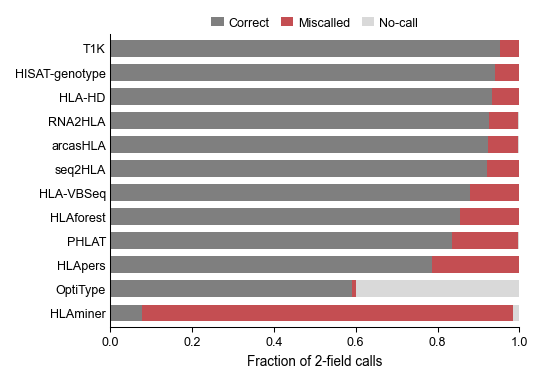

In [15]:
f2 = df_2.set_index("Tool")
frac4 = pd.DataFrame({
    "Correct": f2.TotalCorrect / f2.TotalCalls,
    "Miscalled": f2.TotalMiscalled / f2.TotalCalls,
    "No-call": f2.TotalNoCall / f2.TotalCalls,
}).loc[TOOL_ORDER]


def draw_call_fractions(ax, frame=frac4):
    y = np.arange(len(frame))
    left = np.zeros(len(frame))
    for name in ("Correct", "Miscalled", "No-call"):
        ax.barh(y, frame[name].values, left=left, height=0.7, color=palette[name], label=name)
        left += frame[name].values
    ax.set_yticks(y)
    ax.set_yticklabels(tool_labels(frame.index))
    ax.tick_params(axis="y", length=0)
    ax.set_xlim(0, 1)
    ax.set_ylim(-0.6, len(frame) - 0.4)
    ax.set_xlabel("Fraction of 2-field calls")
    ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=3)


fig, ax = plt.subplots(figsize=(COL1, 62 * MM), layout="constrained")
draw_call_fractions(ax)
save_fig(fig, "fig4_fraction_calls")
plt.show()


### Naive baseline for Figure 3

A naive baseline predicts each locus's most frequent gold-standard allele in both slots, scored with the same contract, as an optimistic ceiling rather than a real competitor. Shown both pooled across D1-D6 and per-dataset.


Accuracy of a tool-free predictor that always names the most frequent allele (D1-D6):
                         All loci  Class I  Class II
Field   Naive predictor                             
1-field pooled              0.395    0.392     0.398
        per dataset         0.397    0.393     0.404
        top-2 pooled        0.333    0.313     0.363
2-field pooled              0.312    0.308     0.318
        per dataset         0.316    0.309     0.328
        top-2 pooled        0.279    0.271     0.291

1-field: tools whose whole 95% interval is above the per-dataset naive baseline (0.397): 11 of 12 (below or overlapping: hlaminer)
2-field: tools whose whole 95% interval is above the per-dataset naive baseline (0.316): 11 of 12 (below or overlapping: hlaminer)


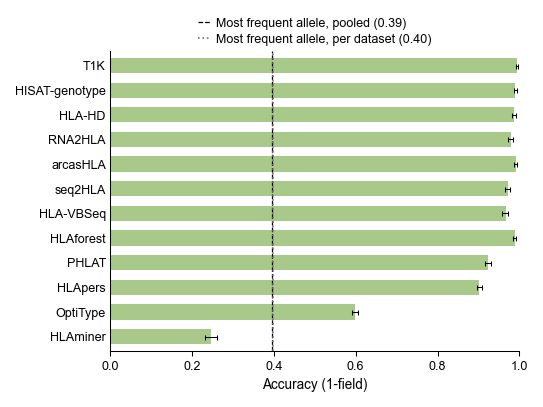

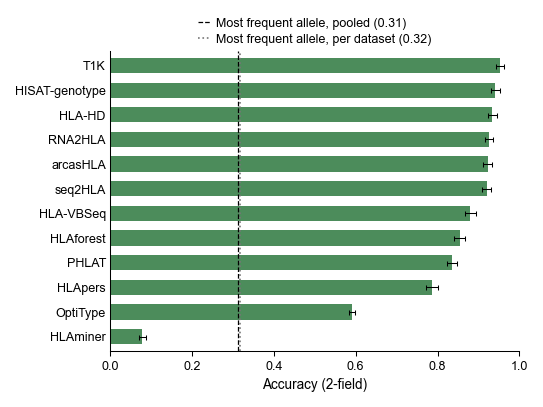

In [16]:
from collections import Counter


def _gs_slots(ds_nums, gs_dir, resolution):
    out = []
    for ds in ds_nums:
        gs_df = pd.read_csv(f"{gs_dir}/{ds}_gs.csv", dtype=str)
        gs_df.iloc[:, 0] = gs_df.iloc[:, 0].str.strip()
        for _, row in gs_df.iterrows():
            for L in get_dynamic_loci(gs_df):
                gs_raw = []
                for suf in ("", ".1"):
                    col = f"{L}{suf}"
                    if col in row and pd.notna(row[col]):
                        gs_raw += [x.strip() for x in str(row[col]).split("/")]
                if gs_raw and L in ("A", "B", "C", "DRB1", "DQB1"):
                    out.append((ds, L, gs_raw))
    return out


def naive_baseline(ds_nums, gs_dir, resolution, per_dataset, top_k=1):
    slots = _gs_slots(ds_nums, gs_dir, resolution)
    freq = {}
    for ds, L, gs_raw in slots:
        key = (ds if per_dataset else 0, L)
        fr = freq.setdefault(key, Counter())
        for a in gs_raw:
            fa = reformat_allele(a, resolution)
            if fa is not None:
                fr[fa] += 1
    acc = {"all": [0, 0], "ClassI": [0, 0], "ClassII": [0, 0]}
    for ds, L, gs_raw in slots:
        top = [a for a, _ in freq[(ds if per_dataset else 0, L)].most_common(top_k)]
        pair = [top[0], top[0]] if top_k == 1 else top[:2]
        r = score_pair(gs_raw, pair, resolution)
        if r is None:
            continue
        cls = "ClassI" if L in CLASS_I_LOCI else "ClassII"
        for k in ("all", cls):
            acc[k][0] += r[0]
            acc[k][1] += 2
    return {k: v[0] / v[1] for k, v in acc.items()}


base = {}
for field, res in (("1-field", 1), ("2-field", 2)):
    base[(field, "pooled")] = naive_baseline(ds_nums, gs_dir, res, False)
    base[(field, "per dataset")] = naive_baseline(ds_nums, gs_dir, res, True)
    base[(field, "top-2 pooled")] = naive_baseline(ds_nums, gs_dir, res, False, top_k=2)
tab = pd.DataFrame(base).T.rename(columns={"all": "All loci", "ClassI": "Class I", "ClassII": "Class II"})
tab.index.names = ["Field", "Naive predictor"]
print("Accuracy of a tool-free predictor that always names the most frequent allele (D1-D6):")
print(tab.round(3).to_string())
print()
best = {f: ci.loc[ci["acc"].idxmax()] for f, ci in (("1-field", ci1), ("2-field", ci2))}
for f, ci in (("1-field", ci1), ("2-field", ci2)):
    bl = base[(f, "per dataset")]["all"]
    above = [t for t in ci.index if ci.loc[t, "lo"] > bl]
    print(f"{f}: tools whose whole 95% interval is above the per-dataset naive baseline ({bl:.3f}): {len(above)} of {len(ci)}"
          f" (below or overlapping: {', '.join(t for t in ci.index if t not in above)})")


def draw_vs_baseline(ax, field, ci, order=None):
    order = order or TOOL_ORDER
    y = np.arange(len(order))
    c = ci.loc[order]
    ax.barh(y, c["acc"], height=0.62, color=palette["2nd field" if field == "2-field" else "1st field"])
    ax.errorbar(c["acc"], y, xerr=[c["acc"] - c["lo"], c["hi"] - c["acc"]], **ERRBAR)
    pooled, per_ds = base[(field, "pooled")]["all"], base[(field, "per dataset")]["all"]
    ax.axvline(pooled, color="black", ls="--", lw=0.6, label=f"Most frequent allele, pooled ({pooled:.2f})")
    ax.axvline(per_ds, color="#777777", ls=":", lw=0.8, label=f"Most frequent allele, per dataset ({per_ds:.2f})")
    ax.set_yticks(y)
    ax.set_yticklabels(tool_labels(order))
    ax.tick_params(axis="y", length=0)
    ax.set_xlim(0, 1)
    ax.set_ylim(-0.6, len(order) - 0.4)
    ax.set_xlabel(f"Accuracy ({field})")
    ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=1)


for field, ci in (("1-field", ci1), ("2-field", ci2)):
    fig, ax = plt.subplots(figsize=(COL1, 66 * MM), layout="constrained")
    draw_vs_baseline(ax, field, ci)
    save_fig(fig, f"fig3c_bulk_accuracy_vs_baseline_{field.replace('-', '')}")
    plt.show()


### Cell type: lymphoblastoid lines vs blood-derived cells

DRB1 is the only locus with gold-standard coverage in both lymphoblastoid (D1/D3/D5/D6) and blood-derived (D2/D4) samples, compared here as D1 vs D2+D4. Read length, prep, and gold-standard method also differ between the groups, so this is an association, not an isolated effect of cell type.


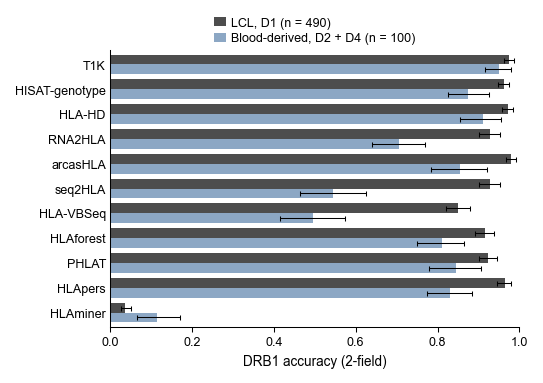

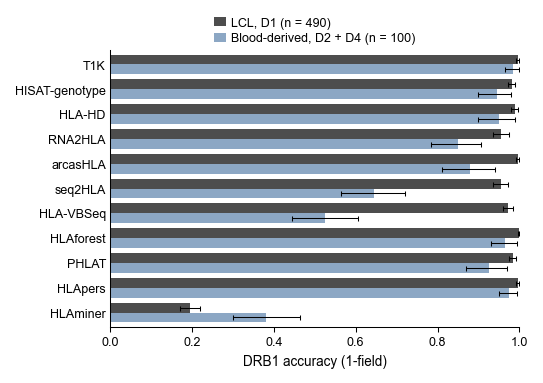

DRB1 2-field accuracy, LCL (D1) vs blood-derived (D2+D4):
           LCL 2-field  blood 2-field  blood - LCL
seq2hla          0.928          0.545       -0.383
hlavbseq         0.850          0.495       -0.355
rna2hla          0.928          0.705       -0.223
hlapers          0.964          0.830       -0.134
arcas            0.980          0.855       -0.125
hlaforest        0.916          0.810       -0.106
hisat            0.962          0.875       -0.087
phlat            0.924          0.845       -0.079
hlahd            0.971          0.910       -0.061
T1K              0.976          0.950       -0.026
optitype         0.000          0.000        0.000
hlaminer         0.038          0.115        0.077
tools with lower DRB1 accuracy in blood-derived samples than in LCLs: 10 of 12


In [17]:
def _drb1_ci(ps, ds_set):
    sub = ps[ps.Dataset.isin(ds_set)]
    return boot_ci(sub, ["DRB1"])


celltype_ci = {field: (_drb1_ci(ps, [1]), _drb1_ci(ps, [2, 4]))
               for field, ps in (("1-field", ps1), ("2-field", ps2))}


def draw_celltype(ax, field):
    lcl, blood = celltype_ci[field]
    order = [t for t in TOOL_ORDER if t in lcl.index and t in blood.index
             and (lcl.loc[t, "acc"] > 0 or blood.loc[t, "acc"] > 0)]
    y = np.arange(len(order))
    h = 0.4
    for off, ci, key, lab in ((h / 2, lcl, "LCL", "LCL, D1 (n = 490)"),
                              (-h / 2, blood, "Blood-derived", "Blood-derived, D2 + D4 (n = 100)")):
        c = ci.loc[order]
        ax.barh(y + off, c["acc"], height=h, color=palette[key], label=lab)
        ax.errorbar(c["acc"], y + off, xerr=[c["acc"] - c["lo"], c["hi"] - c["acc"]], **ERRBAR)
    ax.set_yticks(y)
    ax.set_yticklabels(tool_labels(order))
    ax.tick_params(axis="y", length=0)
    ax.set_xlim(0, 1)
    ax.set_ylim(-0.6, len(order) - 0.4)
    ax.set_xlabel(f"DRB1 accuracy ({field})")
    ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=1)


for field in ("2-field", "1-field"):
    fig, ax = plt.subplots(figsize=(COL1, 62 * MM), layout="constrained")
    draw_celltype(ax, field)
    save_fig(fig, f"fig3d_DRB1_by_cell_type_{field.replace('-', '')}")
    plt.show()

lcl2, blood2 = celltype_ci["2-field"]
cmp_ = pd.DataFrame({"LCL 2-field": lcl2["acc"], "blood 2-field": blood2["acc"]}).dropna()
cmp_["blood - LCL"] = cmp_["blood 2-field"] - cmp_["LCL 2-field"]
print("DRB1 2-field accuracy, LCL (D1) vs blood-derived (D2+D4):")
print(cmp_.sort_values("blood - LCL").round(3).to_string())
print("tools with lower DRB1 accuracy in blood-derived samples than in LCLs: %d of %d" % ((cmp_["blood - LCL"] < 0).sum(), len(cmp_)))


### Are the errors concentrated in a few samples?

Sorts each tool's samples by miscalled-allele count and plots the cumulative share of errors against the cumulative share of samples. The dashed diagonal marks perfectly even error distribution.


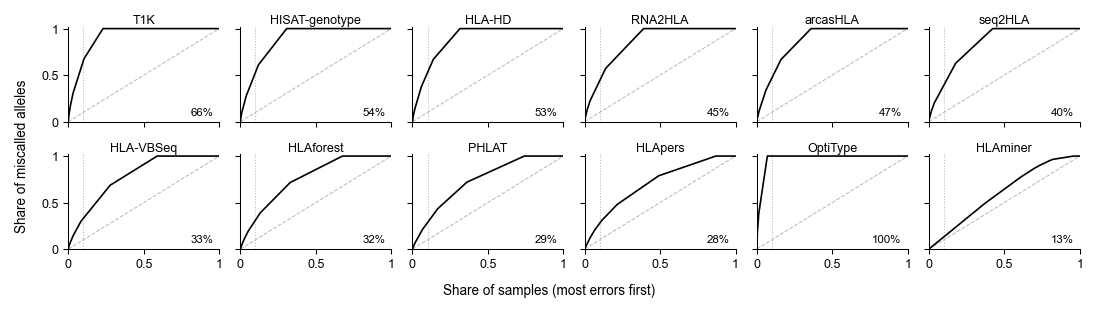

           samples  share of samples with >=1 error  share of errors in worst 10% of samples
Tool                                                                                        
optitype       652                            0.071                                    1.000
T1K            652                            0.230                                    0.664
hisat          652                            0.307                                    0.537
hlahd          652                            0.314                                    0.534
arcas          652                            0.360                                    0.472
rna2hla        652                            0.391                                    0.445
seq2hla        652                            0.423                                    0.398
hlavbseq       652                            0.589                                    0.333
hlaforest      652                            0.675                   

In [18]:
_err = ps2.groupby(["Tool", "Dataset", "Sample"])["miscalled"].sum().reset_index()
lorenz, rows_conc = {}, []
for tool, sub in _err.groupby("Tool"):
    e = np.sort(sub["miscalled"].values)[::-1].astype(float)
    if e.sum() == 0:
        continue
    xs = np.r_[0, np.arange(1, len(e) + 1) / len(e)]
    ys = np.r_[0, np.cumsum(e) / e.sum()]
    top10 = ys[1:][max(int(np.ceil(0.1 * len(e))) - 1, 0)]
    lorenz[tool] = (xs, ys, top10)
    rows_conc.append((tool, len(e), (e > 0).mean(), top10))


def draw_error_concentration(axes, container):
    order = [t for t in TOOL_ORDER if t in lorenz][::-1]
    for ax, t in zip(axes.flat, order):
        xs, ys, top10 = lorenz[t]
        ax.plot([0, 1], [0, 1], color="#BBBBBB", ls="--", lw=0.5)
        ax.axvline(0.1, color="#BBBBBB", ls=":", lw=0.5)
        ax.plot(xs, ys, color="black", lw=0.8)
        ax.text(0.96, 0.05, f"{top10:.0%}", transform=ax.transAxes, ha="right", va="bottom", fontsize=5.5)
        ax.set_title(TOOL_NAME.get(t, t), fontsize=6, pad=1.5)
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1.02)
        ax.set_xticks([0, 0.5, 1], ["0", "0.5", "1"])
        ax.set_yticks([0, 0.5, 1], ["0", "0.5", "1"])
        ax.label_outer()
    for ax in axes.flat[len(order):]:
        ax.set_visible(False)
    container.supxlabel("Share of samples (most errors first)", fontsize=6.5)
    container.supylabel("Share of miscalled alleles", fontsize=6.5)


fig, axes = plt.subplots(2, 6, figsize=(COL2, 50 * MM), sharex=True, sharey=True, layout="constrained")
draw_error_concentration(axes, fig)
save_fig(fig, "fig3e_error_concentration_2field")
plt.show()

conc = pd.DataFrame(rows_conc, columns=["Tool", "samples", "share of samples with >=1 error", "share of errors in worst 10% of samples"]).set_index("Tool")
print(conc.sort_values("share of errors in worst 10% of samples", ascending=False).round(3).to_string())


## Figure 3: assembled figure

Panels a-e at 183 mm; c and d show the 2-field primary analysis, their 1-field versions stay standalone.


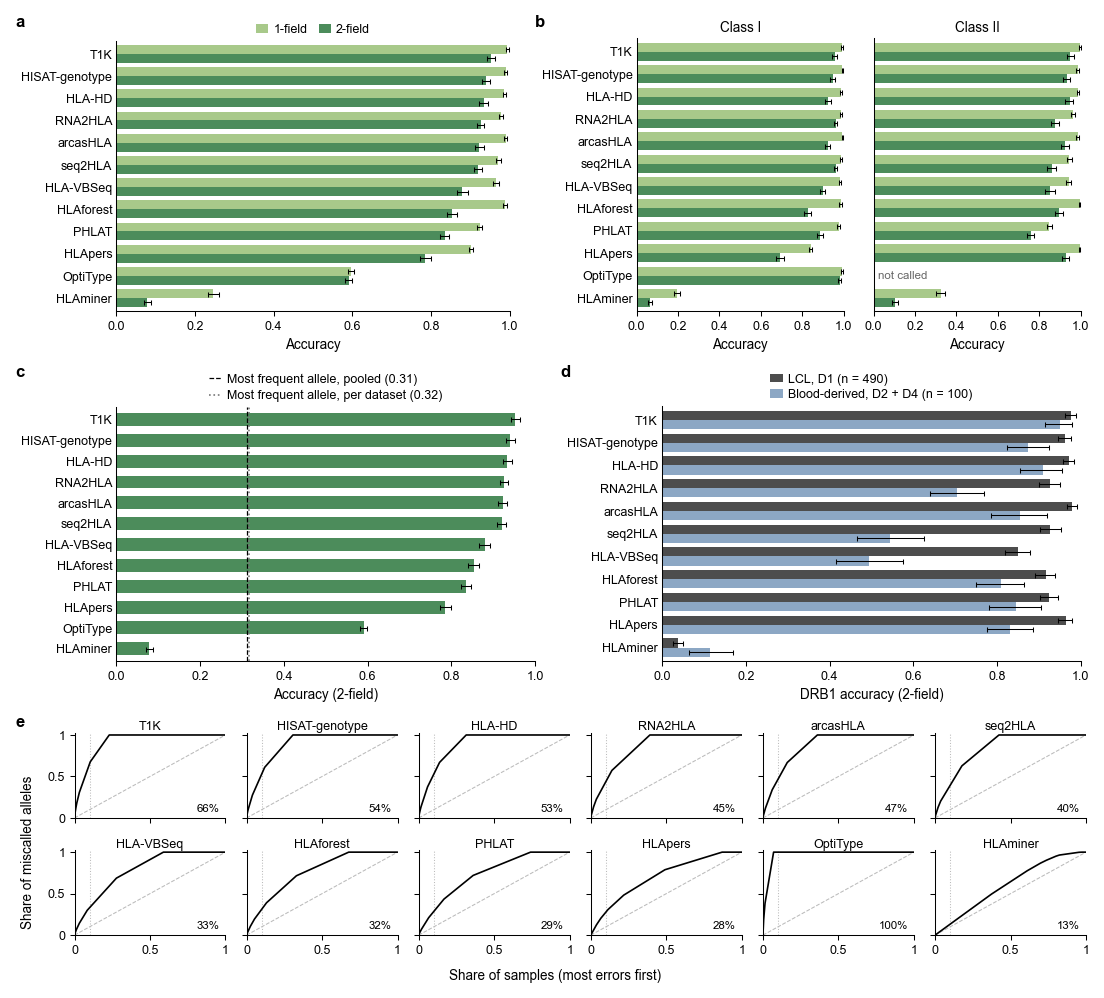

In [19]:
fig = plt.figure(figsize=(COL2, 165 * MM), layout="constrained")
row1, row2, row3 = fig.subfigures(3, 1, height_ratios=[1, 1, 0.8])
sf_a, sf_b = row1.subfigures(1, 2, width_ratios=[1, 1.1])
sf_c, sf_d = row2.subfigures(1, 2)
draw_bulk_accuracy(sf_a.subplots())
ax_I, ax_II = sf_b.subplots(1, 2, sharey=True)
draw_class_accuracy(ax_I, ax_II, legend=False)
draw_vs_baseline(sf_c.subplots(), "2-field", ci2)
draw_celltype(sf_d.subplots(), "2-field")
draw_error_concentration(row3.subplots(2, 6, sharex=True, sharey=True), row3)
for sf, letter in ((sf_a, "a"), (sf_b, "b"), (sf_c, "c"), (sf_d, "d"), (row3, "e")):
    label_panel(sf, letter)
save_fig(fig, "Figure3")
plt.show()


# Figure 5: Accuracy by Locus


A gold-standard allele field of literally `"xx"` (HLA nomenclature for an unresolved second field, only in D3) is dropped from scoring here rather than counted as an unwinnable miss. This affects `df_locus_stats` and every figure built from it below (Fig 5, 6a, 6b).


In [20]:
#!/usr/bin/env python3
import pandas as pd

def compute_locus_metrics(tools, dataset_nums,
                          gs_dir="../../data/gold_standard", pr_dir="../../data/interim/standard",
                          resolution=2) -> pd.DataFrame:
    # 3-outcome contract, no filter_option.
    # initialize counters: tool -> locus -> dict of counts
    agg = {t:{} for t in tools}

    for tool in tools:
        for ds in dataset_nums:
            try:
                gs_df = pd.read_csv(f"{gs_dir}/{ds}_gs.csv", dtype=str)
                pr_df = pd.read_csv(f"{pr_dir}/{tool}_d{ds}.csv", dtype=str)
            except FileNotFoundError:
                continue

            # strip ID columns
            gs_df.iloc[:,0] = gs_df.iloc[:,0].str.strip()
            pr_df.iloc[:,0] = pr_df.iloc[:,0].str.strip()
            # rename pred columns consistently
            rename = {c:f"{c}_pre" for c in pr_df.columns if c != pr_df.columns[0]}
            pr_df = pr_df.rename(columns=rename)

            loci     = get_dynamic_loci(gs_df)
            supported = get_pr_loci(pr_df)

            # merge on sample ID
            id_gs = gs_df.columns[0]
            id_pr = pr_df.columns[0]
            merged = pd.merge(gs_df, pr_df,
                              left_on=id_gs, right_on=id_pr, how="inner")

            # ensure counters exist for all loci
            for L in loci:
                agg[tool].setdefault(L, {
                    "correct":0, "miscalled":0, "no_call":0, "total_calls":0
                })

            # first, penalize unsupported loci for every sample
            for L in loci:
                if L not in supported:
                    # two no-calls per sample
                    n_samples = merged.shape[0]
                    agg[tool][L]["total_calls"] += 2*n_samples
                    agg[tool][L]["no_call"]      += 2*n_samples

            # now walk through each sample × supported locus
            for _, row in merged.iterrows():
                for L in sorted(supported):
                    if L not in loci:
                        continue

                    # GS alleles
                    gs_raw = []
                    for suf in ("", ".1"):
                        col = f"{L}{suf}"
                        if col in row and pd.notna(row[col]):
                            gs_raw += [x.strip() for x in str(row[col]).split("/")]
                    if not gs_raw:
                        # no truth—skip
                        continue

                    # PR alleles
                    pr_raw = []
                    for suf in ("_pre", ".1_pre"):
                        col = f"{L}{suf}"
                        if col in row and pd.notna(row[col]):
                            pr_raw += [x.strip() for x in str(row[col]).split("/")]
                    
                    result = score_pair(gs_raw, pr_raw, resolution)
                    if result is None:
                        continue
                    c, m, nc = result

                    agg[tool][L]["total_calls"] += 2
                    agg[tool][L]["correct"]     += c
                    agg[tool][L]["miscalled"]   += m
                    agg[tool][L]["no_call"]     += nc

    # build output DataFrame
    rows = []
    for tool, loci_dict in agg.items():
        for locus, cts in loci_dict.items():
            total = cts["total_calls"]
            rows.append({
                "Tool": tool,
                "Locus": locus,
                "CorrectAlleles":   cts["correct"],
                "MiscalledAlleles": cts["miscalled"],
                "NoCallAlleles":    cts["no_call"],
                "TotalAlleles":     total,
                "Accuracy":         None if total==0 else cts["correct"]/total
            })
    df = pd.DataFrame(rows)
    return df.sort_values(["Tool","Locus"]).reset_index(drop=True)

# ─────────────────────────────────────────────────────────────────────────────
# 3) EXAMPLE USAGE
# ─────────────────────────────────────────────────────────────────────────────
tools    = ["arcas","optitype","seq2hla","hlaminer",
            "phlat","hlavbseq","hlahd","hisat","hlaforest","hlapers","T1K","rna2hla"]
dataset_nums = list(range(1,7))

# per-locus at 2-field
df_locus_stats = compute_locus_metrics(
    tools, dataset_nums,
    resolution=2
)
df_locus_stats


,Tool,Locus,CorrectAlleles,MiscalledAlleles,NoCallAlleles,TotalAlleles,Accuracy
0,T1K,A,1063,19,0,1082,0.982440
1,T1K,B,1036,50,0,1086,0.953959
2,T1K,C,1021,75,0,1096,0.931569
3,T1K,DQB1,905,75,0,980,0.923469
4,T1K,DRB1,1146,34,0,1180,0.971186
5,arcas,A,987,95,0,1082,0.912200
6,arcas,B,1017,69,0,1086,0.936464
7,arcas,C,1006,90,0,1096,0.917883
8,arcas,DQB1,867,113,0,980,0.884694
9,arcas,DRB1,1131,25,24,1180,0.958475


## Figure 5: locus accuracy heatmap

One colour scale for accuracy (Blues, 0-1, shared with Figure 10); cells a tool never calls are grey, not 0.


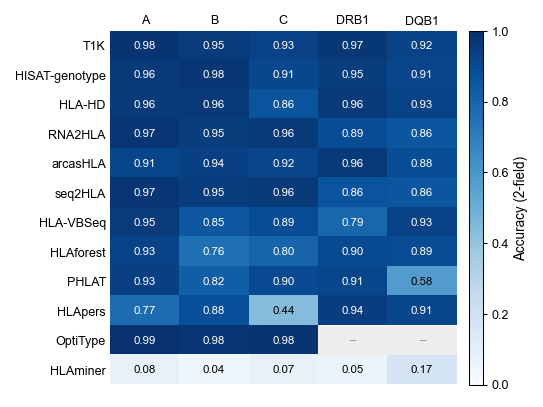

In [21]:
loc5 = df_locus_stats.set_index(["Tool", "Locus"])
df_pivot = (df_locus_stats.pivot(index="Tool", columns="Locus", values="Accuracy")
            .reindex(index=TOOL_ORDER[::-1], columns=LOCI_ORDER))
not_called5 = ((loc5["NoCallAlleles"] == loc5["TotalAlleles"]).unstack("Locus")
               .reindex(index=df_pivot.index, columns=LOCI_ORDER).fillna(True))
ACC_CMAP = "Blues"


def draw_locus_heatmap(ax, cax, data=df_pivot, not_called=not_called5):
    shown = data.mask(not_called)
    im = ax.imshow(shown.values, cmap=ACC_CMAP, vmin=0, vmax=1, aspect="auto")
    for (r, c), v in np.ndenumerate(shown.values):
        if not_called.values[r, c]:
            ax.add_patch(plt.Rectangle((c - 0.5, r - 0.5), 1, 1, facecolor="#EEEEEE", edgecolor="none"))
            ax.text(c, r, "–", ha="center", va="center", fontsize=5.5, color="#888888")
        else:
            ax.text(c, r, f"{v:.2f}", ha="center", va="center", fontsize=5.5,
                    color="white" if v > 0.6 else "black")
    ax.set_xticks(range(len(data.columns)), data.columns)
    ax.set_yticks(range(len(data.index)), tool_labels(data.index))
    ax.xaxis.tick_top()
    ax.tick_params(length=0)
    for side in ax.spines.values():
        side.set_visible(False)
    cb = ax.figure.colorbar(im, cax=cax)
    cb.set_label("Accuracy (2-field)")
    cb.outline.set_linewidth(0.5)
    cb.ax.tick_params(width=0.5, length=2)


fig, (ax, cax) = plt.subplots(1, 2, figsize=(COL1, 66 * MM), width_ratios=[1, 0.04], layout="constrained")
draw_locus_heatmap(ax, cax)
save_fig(fig, "fig5_locus_accuracy")
plt.show()


# Figure 6 & 7: misclassification rate

## Figure 6: Miscalled Alleles by Locus


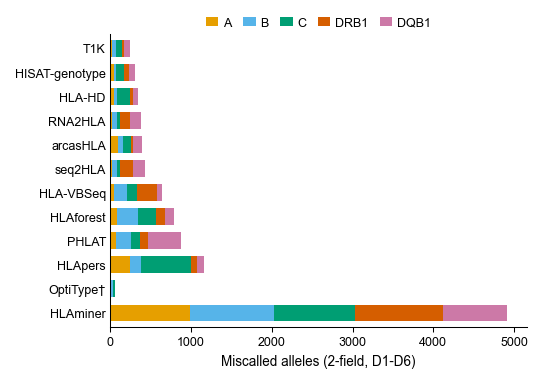

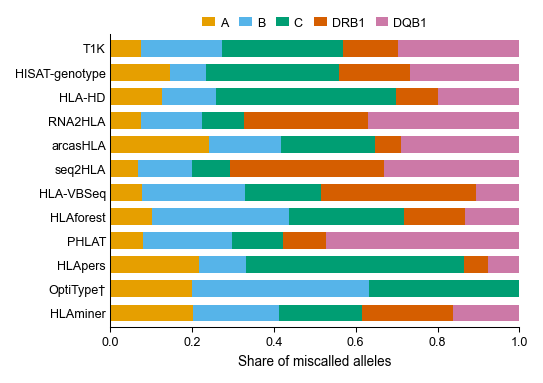

In [22]:
loc6 = df_locus_stats.copy()
mis6 = (loc6.pivot(index="Tool", columns="Locus", values="MiscalledAlleles")
        .reindex(index=TOOL_ORDER, columns=LOCI_ORDER).fillna(0))
share6 = mis6.div(mis6.sum(axis=1), axis=0).fillna(0)
CLASS_I_ONLY = {"optitype"}


def tool_labels6(keys):
    return [TOOL_NAME[k] + ("\u2020" if k in CLASS_I_ONLY else "") for k in keys]


def _stack_by_locus(ax, frame, xlabel, legend):
    y = np.arange(len(frame))
    left = np.zeros(len(frame))
    for L in LOCI_ORDER:
        ax.barh(y, frame[L].values, left=left, height=0.7, color=palette[L], label=L)
        left += frame[L].values
    ax.set_yticks(y)
    ax.set_yticklabels(tool_labels6(frame.index))
    ax.tick_params(axis="y", length=0)
    ax.set_ylim(-0.6, len(frame) - 0.4)
    ax.set_xlabel(xlabel)
    if legend:
        ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=5)


def draw_miscall_counts(ax, legend=True):
    _stack_by_locus(ax, mis6, "Miscalled alleles (2-field, D1-D6)", legend)
    ax.set_xlim(0, None)


def draw_miscall_share(ax, legend=True):
    _stack_by_locus(ax, share6, "Share of miscalled alleles", legend)
    ax.set_xlim(0, 1)


fig, ax = plt.subplots(figsize=(COL1, 62 * MM), layout="constrained")
draw_miscall_counts(ax)
save_fig(fig, "fig6a_miscalled_count")
plt.show()

fig, ax = plt.subplots(figsize=(COL1, 62 * MM), layout="constrained")
draw_miscall_share(ax)
save_fig(fig, "fig6b_miscalled_share")
plt.show()


### Miscall rate per dataset and locus

Each dot is one dataset x locus (D1-D6), so a tool's spread shows whether its errors are general or confined to a few cells; rates, not counts, because the datasets differ in size.


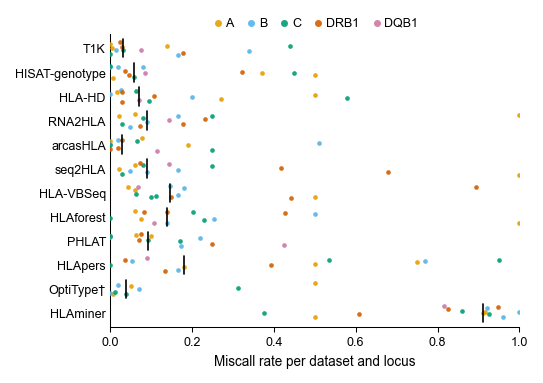

In [23]:
cell6 = ps2.groupby(["Tool", "Dataset", "Locus"])[["correct", "miscalled", "no_call", "total"]].sum().reset_index()
cell6 = cell6[(cell6["correct"] + cell6["miscalled"]) > 0].copy()
cell6["rate"] = cell6["miscalled"] / cell6["total"]
_rng6 = np.random.default_rng(6)
cell6["jitter"] = _rng6.uniform(-0.28, 0.28, len(cell6))


def draw_miscall_spread(ax, legend=True):
    ypos = {t: k for k, t in enumerate(TOOL_ORDER)}
    for L in LOCI_ORDER:
        d = cell6[cell6["Locus"] == L]
        ax.scatter(d["rate"], d["Tool"].map(ypos) + d["jitter"], s=5, color=palette[L],
                   linewidths=0, alpha=0.9, label=L, zorder=3)
    med = cell6.groupby("Tool")["rate"].median()
    for t, k in ypos.items():
        if t in med:
            ax.plot([med[t]] * 2, [k - 0.38, k + 0.38], color="black", lw=0.8, zorder=4)
    ax.set_yticks(range(len(TOOL_ORDER)))
    ax.set_yticklabels(tool_labels6(TOOL_ORDER))
    ax.tick_params(axis="y", length=0)
    ax.set_ylim(-0.6, len(TOOL_ORDER) - 0.4)
    ax.set_xlim(0, 1)
    ax.set_xlabel("Miscall rate per dataset and locus")
    if legend:
        ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=5, handletextpad=0.1,
                  markerscale=1.5)


fig, ax = plt.subplots(figsize=(COL1, 62 * MM), layout="constrained")
draw_miscall_spread(ax)
save_fig(fig, "fig6c_miscall_rate_spread")
plt.show()


## Figure 6: assembled figure


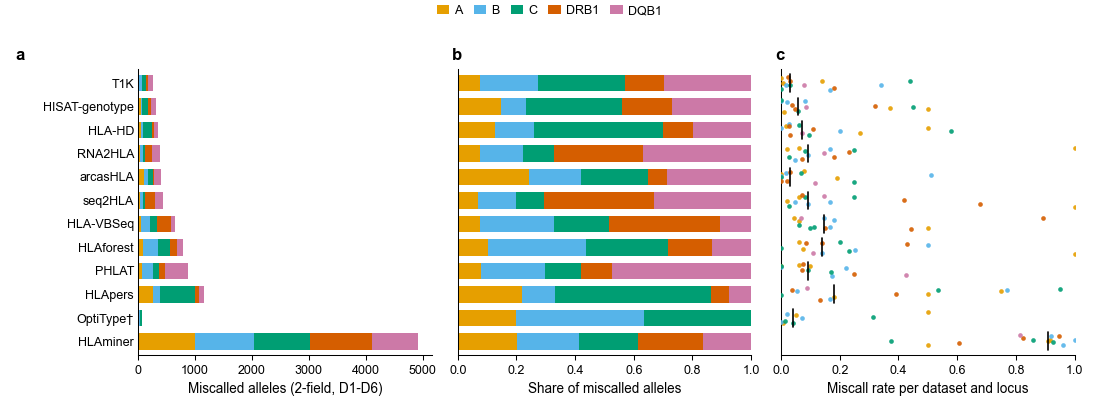

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(COL2, 66 * MM), sharey=True, layout="constrained")
draw_miscall_counts(axes[0], legend=False)
draw_miscall_share(axes[1], legend=False)
draw_miscall_spread(axes[2], legend=False)
for ax in axes[1:]:
    ax.tick_params(axis="y", labelleft=False)
handles = [plt.Rectangle((0, 0), 1, 1, color=palette[L]) for L in LOCI_ORDER]
fig.legend(handles, LOCI_ORDER, loc="outside upper center", ncol=5)
for ax, letter in zip(axes, "abc"):
    ax.text(-0.02 if letter != "a" else -0.42, 1.02, letter, transform=ax.transAxes,
            fontsize=8, fontweight="bold", ha="left", va="bottom")
save_fig(fig, "Figure6")
plt.show()


## Figure 7: Alleles that are hard for every caller

Alleles are ranked by the median of the per-caller miscall rates, so each caller has one vote and only alleles carried by at least 5 samples are ranked. Panel c follows the one allele that most callers miss, DQB1\*06:05, down to its reference sequence.

In [25]:
#!/usr/bin/env python3
import pandas as pd

# ─────────────────────────────────────────────────────────────────────────────
# MISCLASSIFICATION-RATE AGGREGATOR
# ─────────────────────────────────────────────────────────────────────────────
def compute_allele_misclassification_rate(
    tools, dataset_nums,
    gs_dir="../../data/gold_standard", pr_dir="../../data/interim/standard",
    resolution=2
) -> pd.DataFrame:
    # No filter_option -- a novel prediction can never be in gs_set either way,
    # so filtering changes nothing.
    """
    For each (tool, dataset, locus, GS-allele):
      - total += 1
      - if NO prediction (after optional filtering) hits GS_set, mis += 1
    Returns DataFrame with columns:
      Locus | Allele | Total | Mis | MisclassificationRate
    """
    # tally[locus][allele] = {"total": int, "mis": int}
    tally = {}

    for tool in tools:
        for ds in dataset_nums:
            gs_path = f"{gs_dir}/{ds}_gs.csv"
            pr_path = f"{pr_dir}/{tool}_d{ds}.csv"
            try:
                gs_df = pd.read_csv(gs_path, dtype=str)
                pr_df = pd.read_csv(pr_path, dtype=str)
            except FileNotFoundError:
                continue

            # strip whitespace on the ID column, rename preds to *_pre
            gs_df.iloc[:,0] = gs_df.iloc[:,0].str.strip()
            pr_df.iloc[:,0] = pr_df.iloc[:,0].str.strip()
            rename = {c: f"{c}_pre" for c in pr_df.columns if c != pr_df.columns[0]}
            pr_df = pr_df.rename(columns=rename)

            loci        = get_dynamic_loci(gs_df)

            # merge on sample ID
            id_gs = gs_df.columns[0]
            id_pr = pr_df.columns[0]
            merged = pd.merge(gs_df, pr_df, left_on=id_gs, right_on=id_pr, how="inner")

            # initialize tally entries
            for L in loci:
                tally.setdefault(L, {})

            # walk through every sample × locus
            for _, row in merged.iterrows():
                for L in loci:
                    # 1) BUILD GS_SET at this locus
                    gs_raw = []
                    for suf in ("", ".1"):
                        col = f"{L}{suf}"
                        if col in row and pd.notna(row[col]):
                            gs_raw += [x.strip() for x in str(row[col]).split("/")]
                    if not gs_raw:
                        continue
                    gs_set = { reformat_allele(a, resolution) for a in gs_raw }
                    gs_set.discard(None)   # drop ":xx" (unresolved) tokens
                    if not gs_set:         # nothing left -- unscorable at this
                        continue           # resolution, skip (not in denominator)

                    # 2) BUILD PRED_SET (up to 2 alleles)
                    pr_raw = []
                    for suf in ("_pre", ".1_pre"):
                        col = f"{L}{suf}"
                        if col in row and pd.notna(row[col]):
                            pr_raw += [x.strip() for x in str(row[col]).split("/")]
                    # normalize to up to two slots
                    if   len(pr_raw) == 0:
                        pred = []
                    elif len(pr_raw) == 1:
                        pred = pr_raw * 2
                    else:
                        pred = pr_raw[:2]
                    # format
                    pred_fmt = [ reformat_allele(a, resolution) for a in pred ]
                    pred_set = set(pred_fmt)

                    # 3) decide hit vs mis vs true no-call
                    hit = bool(pred_set & gs_set)
                    # A true no-call (nothing reported) is scored separately from a wrong guess.
                    is_no_call = len(pr_raw) == 0 or all(
                        isinstance(a, str) and a.strip().lower() in ("na", "no") for a in pr_raw
                    )  # some tools use a literal no-call token ("NA"/"na"/"no") instead of blank

                    # 4) tally for every TRUE GS allele
                    for allele in gs_set:
                        cnt = tally[L].setdefault(allele, {"total":0, "mis":0, "no_call":0})
                        cnt["total"] += 1
                        if not hit:
                            if is_no_call:
                                cnt["no_call"] += 1
                            else:
                                cnt["mis"] += 1

    # build DataFrame
    rows = []
    for locus, alleles in tally.items():
        for allele, cnt in alleles.items():
            total = cnt["total"]
            mis   = cnt["mis"]
            nc    = cnt["no_call"]
            rate  = mis/total if total>0 else 0.0
            nc_rate = nc/total if total>0 else 0.0
            rows.append({
                "Locus": locus,
                "Allele": allele,
                "Total": total,
                "Mis": mis,
                "NoCall": nc,
                "MisclassificationRate": rate,
                "NoCallRate": nc_rate
            })
    df = pd.DataFrame(rows)
    # tie-break on the allele name: the tally is filled from sets, so without it
    # equal-rate rows come out in a different order on every run
    return df.sort_values(["MisclassificationRate", "Allele"],
                          ascending=[False, True]).reset_index(drop=True)

# ─────────────────────────────────────────────────────────────────────────────
# 3) EXAMPLE USAGE
# ─────────────────────────────────────────────────────────────────────────────
tools        = ["arcas","optitype","seq2hla","hlaminer",
                "phlat","hlavbseq","hlahd","hisat",
                "hlaforest","hlapers","T1K","rna2hla"]
datasets     = list(range(1,7))  # D1-D6 only -- D7/D8 have partial tool coverage,
                                 # would skew the ranking denominator if pooled in.

# two-field misclassification, filtering out “novel” first
df_mis = compute_allele_misclassification_rate(
    tools, datasets,
    resolution=2
)
df_mis['MisclassificationRate%']=df_mis['MisclassificationRate']*100
df_mis


,Locus,Allele,Total,Mis,NoCall,MisclassificationRate,NoCallRate,MisclassificationRate%
0,DQB1,DQB1*06:05,84,37,7,0.440476,0.083333,44.047619
1,C,C*03:05,12,4,1,0.333333,0.083333,33.333333
2,C,C*06:06,12,4,0,0.333333,0.000000,33.333333
3,B,B*41:04,24,6,0,0.250000,0.000000,25.000000
4,B,B*27:51,24,5,0,0.208333,0.000000,20.833333
...,...,...,...,...,...,...,...,...
273,A,A*68:02,96,5,1,0.052083,0.010417,5.208333
274,A,A*69:01,24,1,0,0.041667,0.000000,4.166667
275,A,A*03:03,24,1,0,0.041667,0.000000,4.166667
276,A,A*33:01,48,1,0,0.020833,0.000000,2.083333


In [ ]:
import os

# Allele-level miss rate: among the carriers of an allele for whom a caller reported something at
# that locus, the share in which the caller did not report this allele (2-field, D1-D6). This is
# stricter than the pooled rate of Supplementary Figure 7e-f, which counts a miss only when neither
# reported allele matches the sample, so an allele always missed next to an easy second allele
# looks fine there. Ranking by the median over callers gives each caller one vote, so one weak
# caller cannot push a rare allele to the top.
CLASS_I_PREFIX = ("A*", "B*", "C*")
MIN_CARRIERS = 5
N_HARD = 15
NO_CALL_TOKENS = ("na", "no", "nan", "")


def allele_miss_by_tool(tools, ds_nums):
    rows = []
    for t in tools:
        for ds in ds_nums:
            try:
                gs = pd.read_csv(f"{gs_dir}/{ds}_gs.csv", dtype=str)
                pr = pd.read_csv(f"{pr_dir}/{t}_d{ds}.csv", dtype=str)
            except FileNotFoundError:
                continue
            gs = gs.set_index(gs.columns[0]); gs.index = gs.index.str.strip()
            pr = pr.set_index(pr.columns[0]); pr.index = pr.index.str.strip()
            for sid in gs.index.intersection(pr.index):
                for L in get_dynamic_loci(gs.reset_index()):
                    # an ambiguous gold-standard entry ("C*07:01/C*07:50/...") is one allele: it is
                    # labelled by its first (most common) option and hit if any option is reported
                    slots = [[x for x in (reformat_allele(a.strip()) for a in str(gs.at[sid, c]).split("/")) if x]
                             for c in (L, f"{L}.1") if c in gs.columns and pd.notna(gs.at[sid, c])]
                    calls = {reformat_allele(str(pr.at[sid, c]).strip()) for c in (L, f"{L}.1")
                             if c in pr.columns and pd.notna(pr.at[sid, c])
                             and str(pr.at[sid, c]).strip().lower() not in NO_CALL_TOKENS} - {None}
                    if not calls:
                        continue  # no-call at this locus: not a miscall
                    hit, called_instead = {}, {}
                    for opts in slots:
                        if opts:
                            hit[opts[0]] = hit.get(opts[0], False) or bool(set(opts) & calls)
                    other = calls - {x for opts in slots for x in opts}
                    rows += [{"Tool": t, "Dataset": ds, "Sample": sid, "Locus": L, "Allele": a, "Missed": not h,
                              "CalledInstead": ";".join(sorted(other)) if not h else ""}
                             for a, h in hit.items()]
    return pd.DataFrame(rows)


allele_calls7 = allele_miss_by_tool(tools, datasets)
# OptiType does not type Class II: those alleles are untyped for it, not evidence either way
allele_calls7 = allele_calls7[~((allele_calls7.Tool == "optitype") & ~allele_calls7.Allele.str.startswith(CLASS_I_PREFIX))]
per_tool7 = (allele_calls7.groupby(["Tool", "Allele"])
             .agg(Locus=("Locus", "first"), Carriers=("Sample", "nunique"), Missed=("Missed", "sum"))
             .reset_index())
per_tool7["MissRate"] = per_tool7.Missed / per_tool7.Carriers
rate7 = per_tool7.pivot(index="Allele", columns="Tool", values="MissRate").reindex(columns=TOOL_ORDER)
hard_stats7 = pd.DataFrame({
    "Locus": per_tool7.groupby("Allele").Locus.first(),
    "Carriers": allele_calls7.groupby("Allele").Sample.nunique(),
    "MedianRate": rate7.median(axis=1),
    "ToolsWrongHalf": (rate7 >= 0.5).sum(axis=1),
    "Callers": rate7.notna().sum(axis=1),
})
hard7 = (hard_stats7[hard_stats7.Carriers >= MIN_CARRIERS].reset_index()
         .sort_values(["MedianRate", "ToolsWrongHalf", "Carriers", "Allele"], ascending=[False, False, False, True])
         .head(N_HARD).reset_index(drop=True))
hard_rows7 = hard7.Allele.tolist()[::-1]  # bottom-to-top plotting order

# DQB1*06:05: what each caller reports for the carriers
FOCUS7, DECOY7 = "DQB1*06:05", "DQB1*06:09"
focus_rows = []
for ds in datasets:
    gs = pd.read_csv(f"{gs_dir}/{ds}_gs.csv", dtype=str)
    gs[gs.columns[0]] = gs[gs.columns[0]].str.strip()
    if "DQB1" not in gs.columns:
        continue
    carriers = gs[gs[["DQB1", "DQB1.1"]].apply(
        lambda r: any(reformat_allele(a.strip()) == FOCUS7 for v in r.dropna() for a in str(v).split("/")), axis=1)]
    for t in tools:
        path = f"{pr_dir}/{t}_d{ds}.csv"
        if not os.path.exists(path) or len(carriers) == 0:
            continue
        pr = pd.read_csv(path, dtype=str)
        pr[pr.columns[0]] = pr[pr.columns[0]].str.strip()
        pr = pr.set_index(pr.columns[0])
        for sid in carriers[carriers.columns[0]]:
            raw = [] if sid not in pr.index else [str(pr.at[sid, c]).strip() for c in ("DQB1", "DQB1.1")
                                                 if c in pr.columns and pd.notna(pr.at[sid, c])]
            calls = {reformat_allele(a) for a in raw if a.lower() not in ("na", "no")}
            if t == "optitype":
                outcome = "Not typed"
            elif FOCUS7 in calls:
                outcome = FOCUS7
            elif DECOY7 in calls:
                outcome = DECOY7
            elif calls:
                outcome = "Other allele"
            else:
                outcome = "No call"
            focus_rows.append({"Tool": t, "Dataset": ds, "Sample": sid, "Outcome": outcome})
focus7 = pd.DataFrame(focus_rows)
FOCUS_OUTCOMES = [FOCUS7, DECOY7, "Other allele", "No call"]
FOCUS_COLORS = {FOCUS7: palette["Correct"], DECOY7: palette["Miscalled"], "Other allele": "#E3A8AA",
                "No call": palette["No-call"]}
focus_counts7 = (focus7.groupby(["Tool", "Outcome"]).size().unstack(fill_value=0)
                 .reindex(index=TOOL_ORDER, columns=FOCUS_OUTCOMES + ["Not typed"], fill_value=0))
n_focus7 = focus7.Sample.nunique()


# DQB1*06:05:01 vs DQB1*06:09:01:01 in the IPD-IMGT/HLA reference. Parsed from hla.dat when it
# is present (not in git, ~320 MB); the small extract is kept in data/interim so the panel
# can be redrawn without it.
IMGT_DAT = "../../data/input/hla.dat"
IMGT_EXTRACT = "../../data/interim/imgt_dqb1_0605_vs_0609.csv"


def read_imgt_records(path, names):
    recs, cur, release = {}, None, None
    with open(path) as fh:
        for line in fh:
            if release is None and "Release Version" in line:
                release = line.split("Release Version")[1].strip()
            if line.startswith("DE   "):
                name = line[5:].split(",")[0]
                cur = recs.setdefault(name, {"feat": [], "seq": [], "partial": "(partial)" in line}) if name in names else None
            elif cur is None:
                continue
            elif line.startswith("FT   ") and line[5:21].strip() in ("UTR", "exon"):
                start, end = map(int, line[21:].strip().split(".."))
                cur["feat"].append([line[5:21].strip(), start, end, None])
            elif line.startswith("FT") and "/number=" in line and cur["feat"] and cur["feat"][-1][3] is None:
                cur["feat"][-1][3] = line.split('"')[1]
            elif line.startswith("     "):
                cur["seq"].append("".join(line.split()[:-1]))
            elif line.startswith("//"):
                cur = None
    return recs, release


def build_imgt_extract(full="HLA-DQB1*06:09:01:01", partial="HLA-DQB1*06:05:01"):
    recs, release = read_imgt_records(IMGT_DAT, {full, partial})
    seqs = {n: "".join(r["seq"]).upper() for n, r in recs.items()}
    rows = []
    for name, r in recs.items():
        utr = [f for f in r["feat"] if f[0] == "UTR"]
        for kind, start, end, num in r["feat"]:
            seg = f"exon {num}" if kind == "exon" else ("5' UTR" if start == 1 and len(utr) > 1 else "3' UTR")
            rows.append({"Allele": name[4:], "Segment": seg, "Length": end - start + 1,
                         "Sequence": seqs[name][start - 1:end], "Release": release})
    ext = pd.DataFrame(rows)
    return ext


if os.path.exists(IMGT_DAT):
    imgt7 = build_imgt_extract()
    imgt7.to_csv(IMGT_EXTRACT, index=False)
else:
    imgt7 = pd.read_csv(IMGT_EXTRACT)
IMGT_RELEASE = imgt7.Release.iloc[0]
FULL7, PART7 = "DQB1*06:09:01:01", "DQB1*06:05:01"
SEGMENTS7 = imgt7[imgt7.Allele == FULL7].Segment.tolist()
seg_full = imgt7[imgt7.Allele == FULL7].set_index("Segment")
seg_part = imgt7[imgt7.Allele == PART7].set_index("Segment")
# where the partial record's exons sit inside the full-length ones (exon 1 lacks its 5' end,
# the last sequenced exon its 3' end), and where the two sequences differ
part_offset7, mismatch7 = {}, []
for s in seg_part.index:
    a, b = seg_part.at[s, "Sequence"], seg_full.at[s, "Sequence"]
    off = b.find(a) if b.find(a) >= 0 else (len(b) - len(a) if s == seg_part.index[0] else 0)
    part_offset7[s] = off
    mismatch7 += [(s, off + i + 1, x, b[off + i]) for i, x in enumerate(a) if x != b[off + i]]
# amino-acid effect of each difference, read in the full-length coding sequence; the mature
# DQB1 chain starts after a 32-residue signal peptide (IMGT/HLA numbering)
_CODE = dict(zip((a + b + c for a in "TCAG" for b in "TCAG" for c in "TCAG"),
                 "FFLLSSSSYY**CC*WLLLLPPPPHHQQRRRRIIIMTTTTNNKKSSRRVVVVAAAADDEEGGGG"))
DQB1_SIGNAL_PEPTIDE = 32
_cds = "".join(seg_full.at[s, "Sequence"] for s in SEGMENTS7 if s in ("exon 1", "exon 2", "exon 3", "exon 4"))
_starts = {s: sum(seg_full.at[x, "Length"] for x in ("exon 1", "exon 2", "exon 3", "exon 4")[:k])
           for k, s in enumerate(("exon 1", "exon 2", "exon 3", "exon 4"))}
aa_change7 = []
for s, nt, a, b in mismatch7:
    p = _starts[s] + nt - 1
    codon_full = _cds[p - p % 3:p - p % 3 + 3]
    codon_part = codon_full[:p % 3] + a + codon_full[p % 3 + 1:]
    aa_change7.append((p // 3 + 1 - DQB1_SIGNAL_PEPTIDE, _CODE[codon_part], _CODE[codon_full]))
print("amino-acid changes (mature residue, 06:05, 06:09):", aa_change7)
print(f"IPD-IMGT/HLA {IMGT_RELEASE}: {PART7} {seg_part.Length.sum()} nt sequenced ({', '.join(seg_part.index)}); "
      f"{FULL7} {seg_full.Length.sum()} nt of exons + UTRs")
print("sequence differences (segment, nt, 06:05, 06:09):", mismatch7)
print(f"{FOCUS7}: {n_focus7} carrier samples; callers' reports:")
print(focus_counts7.rename(index=TOOL_NAME).to_string())
# what is reported instead: the substitute named by the most callers (one caller repeating an
# artefact such as HLApers' C*02:205Q counts once)
_inst = (allele_calls7[allele_calls7.Missed & allele_calls7.Allele.isin(hard7.Allele)]
         .assign(CalledInstead=lambda d: d.CalledInstead.str.split(";")).explode("CalledInstead")
         .query("CalledInstead != ''"))
_inst = (_inst.groupby(["Allele", "CalledInstead"]).agg(Callers=("Tool", "nunique"), Calls=("Tool", "size"))
         .reset_index().sort_values(["Allele", "Callers", "Calls", "CalledInstead"], ascending=[True, False, False, True]))
_inst = _inst.groupby("Allele").head(1).set_index("Allele")
hard7["CalledInstead"] = hard7.Allele.map(_inst.CalledInstead)
hard7["InsteadCallers"] = hard7.Allele.map(_inst.Callers)
print(f"\nHard alleles (>= {MIN_CARRIERS} carriers, ranked by median per-caller miss rate):")
print(hard7.round(3).to_string())


def draw_hard_alleles(ax):
    d = hard7.set_index("Allele").loc[hard_rows7]
    y = np.arange(len(d))
    ax.barh(y, d.MedianRate, height=0.7, color=[palette[L] for L in d.Locus])
    for yi, (r, n, alt, k) in enumerate(zip(d.MedianRate, d.Carriers, d.CalledInstead, d.InsteadCallers)):
        label = f"{n}   \u2192 {alt} ({k})"
        if r > 0.5:
            ax.text(r - 0.02, yi, label, va="center", ha="right", fontsize=5, color="white")
        else:
            ax.text(r + 0.02, yi, label, va="center", ha="left", fontsize=5, color="#444444")
    ax.set_yticks(y, d.index)
    ax.tick_params(axis="y", length=0)
    ax.set_ylim(-0.6, len(d) - 0.4)
    ax.set_xlim(0, 1)
    ax.set_xlabel("Median miss rate across callers")
    present = [L for L in LOCI_ORDER if L in set(d.Locus)]
    ax.legend([plt.Rectangle((0, 0), 1, 1, color=palette[L]) for L in present], present,
              loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=len(present))


def draw_allele_tool_heatmap(ax, cax):
    m = rate7.loc[hard_rows7, TOOL_ORDER]
    im = ax.imshow(m.values, cmap="Reds", vmin=0, vmax=1, aspect="auto", origin="lower")
    for (r, c), v in np.ndenumerate(m.values):
        if np.isnan(v):
            ax.add_patch(plt.Rectangle((c - 0.5, r - 0.5), 1, 1, facecolor="#EEEEEE", edgecolor="none"))
            ax.text(c, r, "–", ha="center", va="center", fontsize=5, color="#888888")
        elif v > 0:
            ax.text(c, r, f"{100 * v:.0f}", ha="center", va="center", fontsize=4.5,
                    color="white" if v > 0.6 else "black")
    ax.set_xticks(range(len(TOOL_ORDER)), tool_labels(TOOL_ORDER), rotation=90)
    ax.set_yticks(range(len(m)), [])
    ax.set_ylim(-0.6, len(m) - 0.4)  # same row geometry as draw_hard_alleles
    ax.tick_params(length=0)
    for side in ax.spines.values():
        side.set_visible(False)
    cb = ax.figure.colorbar(im, cax=cax)
    cb.set_label("Miss rate (%)")
    cb.set_ticks([0, 0.5, 1], labels=["0", "50", "100"])
    cb.outline.set_linewidth(0.5)
    cb.ax.tick_params(width=0.5, length=2)


def draw_focus_calls(ax):
    y = np.arange(len(TOOL_ORDER))
    left = np.zeros(len(TOOL_ORDER))
    for o in FOCUS_OUTCOMES:
        v = focus_counts7[o].values
        ax.barh(y, v, left=left, height=0.7, color=FOCUS_COLORS[o], label=o)
        left += v
    for yi, t in enumerate(TOOL_ORDER):
        if focus_counts7.at[t, "Not typed"]:
            ax.text(0.15, yi, "not typed", va="center", ha="left", fontsize=5, color="#888888")
    ax.set_yticks(y, tool_labels(TOOL_ORDER))
    ax.tick_params(axis="y", length=0)
    ax.set_ylim(-0.6, len(y) - 0.4)
    ax.set_xlim(0, n_focus7)
    ax.set_xticks(range(0, n_focus7 + 1))
    ax.set_xlabel(f"{FOCUS7} carriers (n = {n_focus7})")
    ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2)


def draw_reference_map(ax):
    gap = 25
    x0, pos = 0, {}
    for s in SEGMENTS7:
        pos[s] = x0
        x0 += seg_full.at[s, "Length"] + gap
    rows = {FULL7: 1.0, PART7: 0.0}
    for allele, yy in rows.items():
        for s in SEGMENTS7:
            L = seg_full.at[s, "Length"]
            h = 0.22 if "UTR" in s else 0.4
            if allele == PART7:
                ax.add_patch(plt.Rectangle((pos[s], yy - h / 2), L, h, facecolor="none", edgecolor="#999999",
                                           linewidth=0.5, linestyle=(0, (2, 1.5))))
            if allele == FULL7:
                ax.add_patch(plt.Rectangle((pos[s], yy - h / 2), L, h, facecolor="#7F7F7F", edgecolor="none"))
            elif s in seg_part.index:
                ax.add_patch(plt.Rectangle((pos[s] + part_offset7[s], yy - h / 2), seg_part.at[s, "Length"], h,
                                           facecolor="#7F7F7F", edgecolor="none"))
        if allele == FULL7:
            for s in SEGMENTS7:
                if s.startswith("exon"):
                    ax.text(pos[s] + seg_full.at[s, "Length"] / 2, yy + 0.3, s.split()[1], ha="center",
                            va="bottom", fontsize=5)
    for (s, nt, a, b), (res, aa_p, aa_f) in zip(mismatch7, aa_change7):
        x = pos[s] + nt - 1
        ax.plot([x, x], [-0.3, 1.3], color=palette["Miscalled"], lw=0.8, zorder=5)
        ax.text(x + 15, 0.5, f"only difference: {s}, nt {nt} ({a} vs {b}),\nresidue {res} ({aa_p} in 06:05, {aa_f} in 06:09)",
                ha="left", va="center", fontsize=5, color=palette["Miscalled"])
    ax.set_yticks([0, 1], [f"{PART7}\n{seg_part.Length.sum()} nt, partial",
                           f"{FULL7}\n{seg_full.Length.sum()} nt, complete"])
    ax.tick_params(axis="y", length=0)
    ax.set_xlim(-gap, x0)
    ax.set_ylim(-0.5, 1.75)
    ax.set_xticks([])
    for side in ("left", "bottom"):
        ax.spines[side].set_visible(False)
    ax.set_xlabel(f"Exons and UTRs in IPD-IMGT/HLA {IMGT_RELEASE} (introns not drawn); dashed: not in the reference")


fig, ax = plt.subplots(figsize=(COL1, 70 * MM), layout="constrained")
draw_hard_alleles(ax)
save_fig(fig, "fig7a_hard_alleles")
plt.show()

fig, (ax, cax) = plt.subplots(1, 2, figsize=(COL1, 70 * MM), width_ratios=[1, 0.04], layout="constrained")
draw_allele_tool_heatmap(ax, cax)
ax.set_yticks(range(len(hard_rows7)), hard_rows7)
save_fig(fig, "fig7b_allele_tool_heatmap")
plt.show()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(COL2, 52 * MM), width_ratios=[0.8, 1.6], layout="constrained")
draw_focus_calls(ax1)
draw_reference_map(ax2)
save_fig(fig, "fig7c_dqb1_0605")
plt.show()

fig = plt.figure(figsize=(COL2, 140 * MM), layout="constrained")
sf_top, sf_c = fig.subfigures(2, 1, height_ratios=[1.45, 1])
# a and b share one grid row so their allele rows line up
ax_a, ax_b, cax_b = sf_top.subplots(1, 3, width_ratios=[0.75, 1.3, 0.035])
draw_hard_alleles(ax_a)
draw_allele_tool_heatmap(ax_b, cax_b)
ax_c1, ax_c2 = sf_c.subplots(1, 2, width_ratios=[0.8, 1.6])
draw_focus_calls(ax_c1)
draw_reference_map(ax_c2)
label_panel(sf_top, "a")
ax_b.annotate("b", xy=(0, 1), xycoords="axes fraction", xytext=(-6, 10), textcoords="offset points",
              fontsize=8, fontweight="bold", ha="right", va="bottom")
label_panel(sf_c, "c")
save_fig(fig, "Figure7")
plt.show()

### Supplementary Figure 7e-f: pooled ranking

The earlier Figure 7 ranked alleles by the miscall rate pooled over all callers. That ranking is driven by HLAminer (panel b) and by alleles with one to three carriers, so it is kept here for reference only.

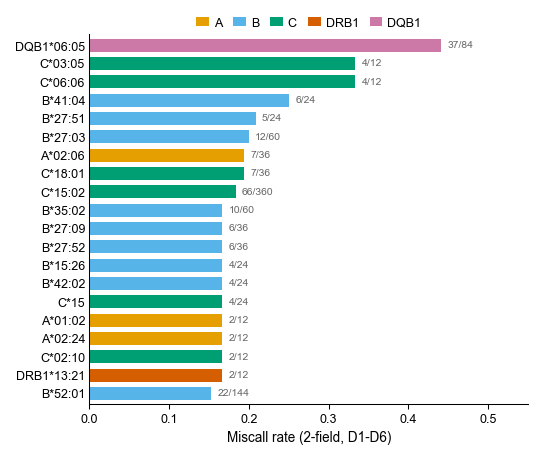

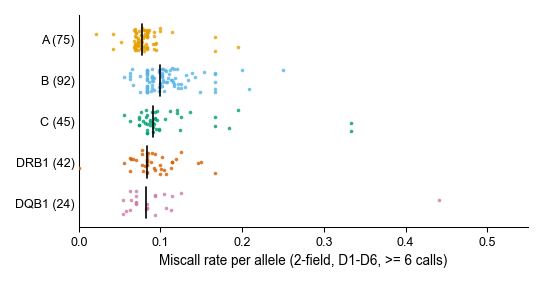

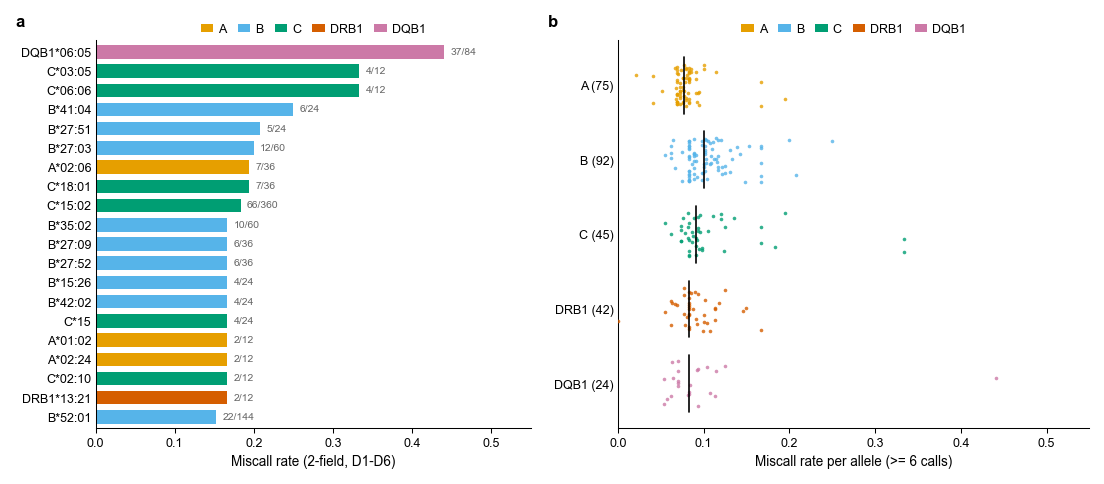

Top-20 ranking ties broken by Total (desc) then allele name; overlap with nlargest(): 20 of 20


In [26]:
N = 20
RATE_XMAX = 0.55
MIN_TOTAL = 6
ranked7 = df_mis.sort_values(["MisclassificationRate", "Total", "Allele"], ascending=[False, False, True])
top7 = ranked7.head(N).iloc[::-1].reset_index(drop=True)
alleles7 = df_mis[df_mis["Total"] >= MIN_TOTAL].copy()


def locus_handles(loci=LOCI_ORDER):
    return [plt.Rectangle((0, 0), 1, 1, color=palette[L]) for L in loci], list(loci)


def draw_top_alleles(ax, legend=True):
    y = np.arange(len(top7))
    ax.barh(y, top7["MisclassificationRate"], height=0.7, color=[palette[L] for L in top7["Locus"]])
    for yi, (r, m, n) in enumerate(zip(top7["MisclassificationRate"], top7["Mis"], top7["Total"])):
        ax.text(r + 0.008, yi, f"{m}/{n}", va="center", ha="left", fontsize=5, color="#666666")
    ax.set_yticks(y, top7["Allele"])
    ax.tick_params(axis="y", length=0)
    ax.set_ylim(-0.6, len(top7) - 0.4)
    ax.set_xlim(0, RATE_XMAX)
    ax.set_xlabel("Pooled miscall rate (2-field, D1-D6)")
    if legend:
        present = [L for L in LOCI_ORDER if L in set(top7["Locus"])]
        ax.legend(*locus_handles(present), loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=len(present))


def draw_allele_spread(ax, frame=None, seed=7, show_n=True, xmax=RATE_XMAX):
    frame = alleles7 if frame is None else frame
    rng = np.random.default_rng(seed)
    rows = LOCI_ORDER[::-1]
    labels = []
    for k, L in enumerate(rows):
        d = frame[frame["Locus"] == L]
        ax.scatter(d["MisclassificationRate"], k + rng.uniform(-0.3, 0.3, len(d)), s=3,
                   color=palette[L], linewidths=0, alpha=0.8, zorder=3)
        if len(d):
            med = d["MisclassificationRate"].median()
            ax.plot([med, med], [k - 0.38, k + 0.38], color="black", lw=0.8, zorder=4)
        labels.append(f"{L} ({len(d)})" if show_n else L)
    ax.set_yticks(range(len(rows)), labels)
    ax.tick_params(axis="y", length=0)
    ax.set_ylim(-0.6, len(rows) - 0.4)
    ax.set_xlim(0, xmax)


pooled_by_tool7 = pd.concat({t: compute_allele_misclassification_rate([t], datasets, resolution=2) for t in tools},
                            names=["Tool"]).reset_index(level=0)
top_share7 = (pooled_by_tool7[pooled_by_tool7.Allele.isin(top7.Allele)].groupby("Tool").Mis.sum()
              .reindex(TOOL_ORDER, fill_value=0))
top_share7 = top_share7 / top_share7.sum()


def draw_top_share_by_tool(ax):
    y = np.arange(len(TOOL_ORDER))
    ax.barh(y, top_share7.values, height=0.7, color=palette["Miscalled"])
    for yi, v in enumerate(top_share7.values):
        ax.text(v + 0.01, yi, f"{100 * v:.0f}%", va="center", ha="left", fontsize=5, color="#666666")
    ax.set_yticks(y, tool_labels(TOOL_ORDER))
    ax.tick_params(axis="y", length=0)
    ax.set_ylim(-0.6, len(y) - 0.4)
    ax.set_xlim(0, 0.55)
    ax.set_xlabel("Share of the top-20 alleles' miscalls")


fig = plt.figure(figsize=(COL2, 78 * MM), layout="constrained")
sf_a, sf_b = fig.subfigures(1, 2, width_ratios=[1, 0.8])
draw_top_alleles(sf_a.subplots())
draw_top_share_by_tool(sf_b.subplots())
label_panel(sf_a, "a")
label_panel(sf_b, "b")
save_fig(fig, "fig7_supp_e_pooled_top20")
plt.show()

fig, ax = plt.subplots(figsize=(COL1, 45 * MM), layout="constrained")
draw_allele_spread(ax)
ax.set_xlabel(f"Pooled miscall rate per allele (2-field, D1-D6, >= {MIN_TOTAL} calls)")
ax.legend(*locus_handles(), loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=5)
save_fig(fig, "fig7_supp_f_allele_spread")
plt.show()
print(f"HLAminer makes {100 * top_share7['hlaminer']:.0f}% of the pooled top-20 alleles' miscalls; "
      f"{int((hard_stats7.Carriers.reindex(top7.Allele) <= 3).sum())} of the 20 alleles have <= 3 carriers")
print("Top-20 ranking ties broken by Total (desc) then allele name; overlap with nlargest():",
      len(set(top7["Allele"]) & set(df_mis.nlargest(N, "MisclassificationRate")["Allele"])), "of", N)


### Supplementary Figure 7d: allele miscall rates within each dataset

Same scoring as Supplementary Figure 7f, one panel per dataset; D7 and D8 (*) have partial tool coverage and are outside the D1-D6 main scope.


alleles scored in >=2 datasets: 109
pattern
dataset-specific    59
low everywhere      38
universal           12

per-dataset alleles scored / shown: {1: (275, 275), 2: (11, 11), 3: (52, 52), 4: (8, 8), 5: (2, 2), 6: (4, 4), 7: (86, 86), 8: (19, 19)}


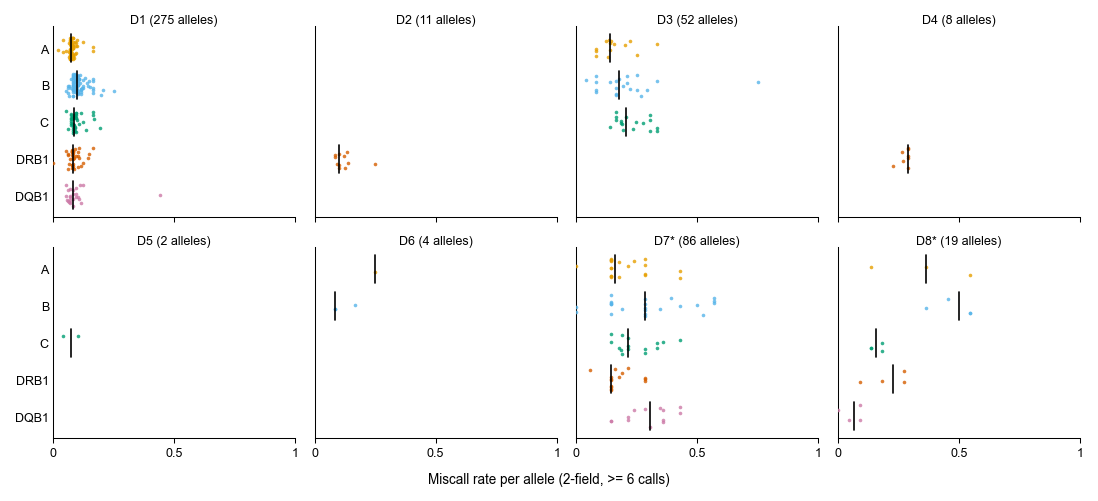

In [27]:
TOOLS = ["arcas", "optitype", "seq2hla", "hlaminer", "phlat", "hlavbseq", "hlahd", "hisat", "hlaforest", "hlapers", "T1K", "rna2hla"]
MIN_TOTAL = 6
PER_DS_TOTAL = {}
per_ds_frames = []
for d in range(1, 9):
    dd = compute_allele_misclassification_rate(TOOLS, [d], resolution=2)
    if dd.empty:
        continue
    dd["Dataset"] = d
    per_ds_frames.append(dd)
    PER_DS_TOTAL[d] = (len(dd), int((dd.Total >= MIN_TOTAL).sum()))

per_ds = pd.concat(per_ds_frames, ignore_index=True)
per_ds["MisclassificationRate%"] = per_ds["MisclassificationRate"] * 100
per_ds.to_csv("../../data/final/fig7_allele_rates_by_dataset.csv", index=False)

multi = per_ds[per_ds.Total >= MIN_TOTAL]
spread = (multi.groupby(["Locus", "Allele"])
          .agg(datasets_scored=("Dataset", "nunique"),
               datasets_high=("MisclassificationRate", lambda x: int((x >= 0.20).sum())),
               rate_min=("MisclassificationRate", "min"),
               rate_max=("MisclassificationRate", "max"))
          .reset_index())
multi_ds = spread[spread.datasets_scored >= 2].copy()
multi_ds["pattern"] = ["universal" if h >= 2 else ("dataset-specific" if h == 1 else "low everywhere")
                       for h in multi_ds.datasets_high]
print("alleles scored in >=2 datasets:", len(multi_ds))
print(multi_ds.pattern.value_counts().to_string())
multi_ds.sort_values("rate_max", ascending=False).to_csv("../../data/final/fig7_allele_universality.csv", index=False)
print("\nper-dataset alleles scored / shown:", PER_DS_TOTAL)

DATASET_COLORS = dict(zip(range(1, 9), sns.color_palette("colorblind", 8)))
CORE_DS = list(range(1, 7))


def ds_title(d):
    return f"D{d}" + ("*" if d not in CORE_DS else "")


fig, axes = plt.subplots(2, 4, figsize=(COL2, 82 * MM), sharex=True, sharey=True, layout="constrained")
for ax, d in zip(axes.flat, range(1, 9)):
    sub = per_ds[(per_ds["Dataset"] == d) & (per_ds["Total"] >= MIN_TOTAL)]
    draw_allele_spread(ax, sub, seed=d, show_n=False, xmax=1)
    ax.set_title(f"{ds_title(d)} ({len(sub)} alleles)", fontsize=6, pad=1.5)
    ax.set_xticks([0, 0.5, 1], ["0", "0.5", "1"])
    ax.label_outer()
fig.supxlabel(f"Miscall rate per allele (2-field, >= {MIN_TOTAL} calls)", fontsize=6.5)
save_fig(fig, "fig7_supp_d_per_dataset_rates")
plt.show()


### Supplementary Figure 7c: which datasets the top-20 miscalls come from

Share of each top-20 allele's miscalls contributed by each dataset, same row order as Supplementary Figure 7e; a larger share means more absolute miscalls, not a higher rate.


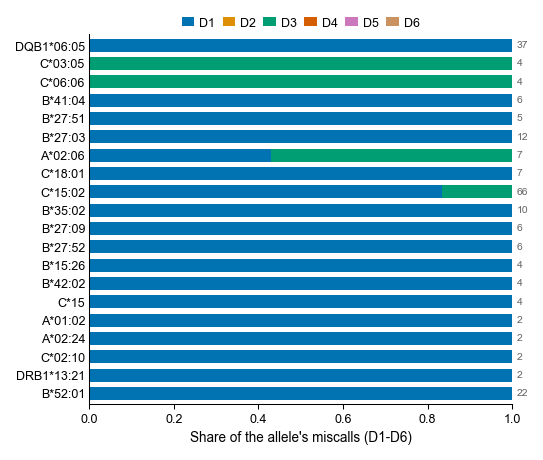

In [28]:
top_order7 = list(top7["Allele"])
stack_src = per_ds[per_ds["Allele"].isin(top_order7) & per_ds["Dataset"].isin(CORE_DS)]
pivot_mis = (stack_src.pivot_table(index="Allele", columns="Dataset", values="Mis", aggfunc="sum", fill_value=0)
             .reindex(index=top_order7, columns=CORE_DS, fill_value=0))
pivot_share = pivot_mis.div(pivot_mis.sum(axis=1), axis=0).fillna(0)


def draw_dataset_share(ax):
    y = np.arange(len(pivot_share))
    left = np.zeros(len(pivot_share))
    for d in CORE_DS:
        ax.barh(y, pivot_share[d].values, left=left, height=0.7, color=DATASET_COLORS[d], label=f"D{d}")
        left += pivot_share[d].values
    for yi, m in enumerate(pivot_mis.sum(axis=1).values):
        ax.text(1.01, yi, str(int(m)), va="center", ha="left", fontsize=5, color="#666666")
    ax.set_yticks(y, pivot_share.index)
    ax.tick_params(axis="y", length=0)
    ax.set_ylim(-0.6, len(y) - 0.4)
    ax.set_xlim(0, 1)
    ax.set_xlabel("Share of the allele's miscalls (D1-D6)")
    ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=6, columnspacing=0.6)


fig, ax = plt.subplots(figsize=(COL1, 75 * MM), layout="constrained")
draw_dataset_share(ax)
save_fig(fig, "fig7_supp_c_dataset_share")
plt.show()


## Supplementary Figure 7a-b: per-dataset breakdown of the top-20 alleles

Same scoring contract as Figure 7 with a Dataset dimension added; the D1-D6 top-20 ranking is reused and D7/D8 are shown but flagged.


In [29]:
from __future__ import annotations

import os

import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.lines as mlines
import matplotlib.font_manager as fm
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Image, display

HERE = os.getcwd()
REPO = os.path.dirname(os.path.dirname(HERE)) if os.path.basename(HERE) == "notebooks" else HERE
GS_DIR = os.path.join(REPO, "data", "gold_standard")
PR_DIR = os.path.join(REPO, "data", "interim", "standard")
FIG_DIR = os.path.join(REPO, "figures")
OUT_DIR = os.path.join(REPO, "data", "final")
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)

def show(path, width=900):
    """Each plot_*() function below saves+closes its own figure (Agg
    backend) -- it never reaches IPython's display hook on its own. This
    re-displays the PNG it just wrote, so the notebook shows the actual file
    on disk, not a second in-memory render."""
    display(Image(filename=path, width=width))



## Shared constants


In [30]:
LOCUS_PAL = LOCUS_PALETTE = {L: palette[L] for L in LOCI_ORDER}
LOCI = tuple(LOCI_ORDER)
LEGEND_KWARGS = dict(frameon=False)

MAIN_SCOPE = list(range(1, 7))        # D1-D6, the main-analysis scope
DISPLAY_SCOPE = list(range(1, 9))     # + D7, D8, shown but flagged
MIN_TOTAL = 6                         # min evaluable (tool x sample) calls to score/rank
ELEVATED_THRESHOLD = 30.0             # % miscalled; "elevated" above this
REDUCED_COVERAGE = {
    7: "6/12 tools scored",  # T1K_d7.csv is defective (blank sample IDs, "."-only calls)
    8: "11/12 tools; n=3, shallow read depth",  # PHLAT/HISAT-genotype have no usable output
}


def apply_theme() -> None:
    apply_nature_style()


def full_box(ax):
    for side in ("top", "right", "left", "bottom"):
        ax.spines[side].set_visible(True)
        ax.spines[side].set_color("black")
        ax.spines[side].set_linewidth(0.5)


def add_panel_label(fig, letter, x=0.0, y=1.0):
    fig.text(x, y, letter, fontsize=8, fontweight="bold", ha="left", va="top")


## Panels a, b -- top-20 alleles (ranked on D1-D6), broken down by dataset

Top-20 ranking uses D1-D6 only, since D7 has only 6/12 tools and would otherwise be pooled into the same denominator as D1-D6's full coverage. D7 is still computed and shown in these panels, it just doesn't affect which 20 alleles are selected.


In [33]:
# ---- per-dataset aggregator (identical logic, Dataset added to the tally key) ----
def compute_allele_misclassification_rate_by_dataset(
    tools, dataset_nums, gs_dir=GS_DIR, pr_dir=PR_DIR,
    resolution=2,
) -> pd.DataFrame:
    # 3-outcome contract, no filter_option.
    """
    For each (dataset, locus, GS-allele): Total += 1 for every (tool x sample)
    evaluation in which that allele is in the sample's gs_set at that locus;
    Mis += 1 when the (filtered) pred_set does not intersect gs_set. The ONLY
    difference from the pooled function above is the tally key.
    """
    tally = {}
    tools_seen = {}

    for tool in tools:
        for ds in dataset_nums:
            gs_path = f"{gs_dir}/{ds}_gs.csv"
            pr_path = f"{pr_dir}/{tool}_d{ds}.csv"
            try:
                gs_df = pd.read_csv(gs_path, dtype=str)
                pr_df = pd.read_csv(pr_path, dtype=str)
            except FileNotFoundError:
                continue
            tools_seen.setdefault(ds, set()).add(tool)

            gs_df.iloc[:, 0] = gs_df.iloc[:, 0].str.strip()
            pr_df.iloc[:, 0] = pr_df.iloc[:, 0].str.strip()
            rename = {c: f"{c}_pre" for c in pr_df.columns if c != pr_df.columns[0]}
            pr_df = pr_df.rename(columns=rename)

            loci = get_dynamic_loci(gs_df)

            id_gs = gs_df.columns[0]
            id_pr = pr_df.columns[0]
            merged = pd.merge(gs_df, pr_df, left_on=id_gs, right_on=id_pr, how="inner")

            for _, row in merged.iterrows():
                for L in loci:
                    gs_raw = []
                    for suf in ("", ".1"):
                        col = f"{L}{suf}"
                        if col in row and pd.notna(row[col]):
                            gs_raw += [x.strip() for x in str(row[col]).split("/")]
                    if not gs_raw:
                        continue
                    gs_set = {reformat_allele(a, resolution) for a in gs_raw}
                    gs_set.discard(None)   # drop ":xx" (unresolved) tokens
                    if not gs_set:         # nothing left -- unscorable at this
                        continue           # resolution, skip (not in denominator)

                    pr_raw = []
                    for suf in ("_pre", ".1_pre"):
                        col = f"{L}{suf}"
                        if col in row and pd.notna(row[col]):
                            pr_raw += [x.strip() for x in str(row[col]).split("/")]
                    if len(pr_raw) == 0:
                        pred = []
                    elif len(pr_raw) == 1:
                        pred = pr_raw * 2
                    else:
                        pred = pr_raw[:2]
                    pred_fmt = [reformat_allele(a, resolution) for a in pred]
                    pred_set = set(pred_fmt)

                    hit = bool(pred_set & gs_set)
                    # Same no-call/miscall split as the pooled aggregator above.
                    is_no_call = len(pr_raw) == 0 or all(
                        isinstance(a, str) and a.strip().lower() in ("na", "no") for a in pr_raw
                    )  # some tools use a literal no-call token ("NA"/"na"/"no") instead of blank

                    for allele in gs_set:
                        cnt = tally.setdefault((ds, L, allele), {"total": 0, "mis": 0, "no_call": 0})
                        cnt["total"] += 1
                        if not hit:
                            if is_no_call:
                                cnt["no_call"] += 1
                            else:
                                cnt["mis"] += 1

    rows = [{
        "Dataset": ds, "Locus": L, "Allele": a,
        "Total": c["total"], "Mis": c["mis"], "NoCall": c["no_call"],
        "MisclassificationRate": c["mis"] / c["total"] if c["total"] > 0 else 0.0,
        "NoCallRate": c["no_call"] / c["total"] if c["total"] > 0 else 0.0,
    } for (ds, L, a), c in tally.items()]

    df = pd.DataFrame(rows)
    df["MisclassificationRate%"] = df["MisclassificationRate"] * 100
    df = df.sort_values(["Dataset", "Locus", "MisclassificationRate", "Allele"],
                        ascending=[True, True, False, True]).reset_index(drop=True)
    df.attrs["tools_seen"] = {k: sorted(v) for k, v in sorted(tools_seen.items())}
    return df


def build_gs_presence(dataset_nums, gs_dir=GS_DIR, resolution=2) -> pd.DataFrame:
    """(Dataset, Locus, Allele) -> GSCount, derived from the gold standard
    ALONE. Lets a cell be labelled "not present" rather than silently scored
    as 0% miscalled."""
    rows = []
    for ds in dataset_nums:
        gs_path = f"{gs_dir}/{ds}_gs.csv"
        try:
            gs_df = pd.read_csv(gs_path, dtype=str)
        except FileNotFoundError:
            continue
        loci = get_dynamic_loci(gs_df)
        counts, samples = {}, {}
        for _, row in gs_df.iterrows():
            for L in loci:
                present_in_sample = set()
                for suf in ("", ".1"):
                    col = f"{L}{suf}"
                    if col in row and pd.notna(row[col]):
                        for a in str(row[col]).split("/"):
                            fa = reformat_allele(a.strip(), resolution)
                            counts[(L, fa)] = counts.get((L, fa), 0) + 1
                            present_in_sample.add(fa)
                for fa in present_in_sample:
                    samples[(L, fa)] = samples.get((L, fa), 0) + 1
        for (L, a), n in counts.items():
            rows.append({"Dataset": ds, "Locus": L, "Allele": a,
                         "GSSlots": n, "GSSamples": samples[(L, a)]})
    return pd.DataFrame(rows)


UNIVERSAL_MIN_DATASETS = 3  # elevated in >= this many datasets -> universal


def classify_allele(rates: dict) -> tuple:
    """rates: {dataset -> misclassification rate % or None}. None = allele
    not present in that dataset's GS, or present but < MIN_TOTAL evaluable
    calls. Returns (label, n_present, n_elevated)."""
    scored = {d: r for d, r in rates.items() if r is not None}
    n_present = len(scored)
    n_elev = sum(1 for r in scored.values() if r > ELEVATED_THRESHOLD)

    if n_present <= 1:
        return ("not assessable (single dataset)", n_present, n_elev)
    if n_elev >= UNIVERSAL_MIN_DATASETS:
        return ("universal", n_present, n_elev)
    if n_elev == 1:
        return ("dataset-specific", n_present, n_elev)
    if n_elev == 2:
        return ("partially shared", n_present, n_elev)
    return ("not elevated anywhere", n_present, n_elev)


In [34]:
NOT_PRESENT_COLOR = "#EEEEEE"
RATE_CMAP = "Reds"


def draw_dataset_heatmap(ax, cax, order, datasets):
    n_r, n_c = len(order), len(datasets)
    mat = np.full((n_r, n_c), np.nan)
    for i, a in enumerate(order):
        for j, d in enumerate(datasets):
            if presence_wide.get((a, d), 0) and wide_total.get((a, d), 0) >= MIN_TOTAL:
                mat[i, j] = wide_rate[(a, d)] / 100
    im = ax.imshow(mat, cmap=RATE_CMAP, vmin=0, vmax=1, aspect="auto")
    for i, a in enumerate(order):
        for j, d in enumerate(datasets):
            if not presence_wide.get((a, d), 0):
                ax.add_patch(plt.Rectangle((j - 0.5, i - 0.5), 1, 1, facecolor=NOT_PRESENT_COLOR, edgecolor="white", lw=0.5))
            elif np.isnan(mat[i, j]):
                ax.text(j, i, "\u00b7", ha="center", va="center", fontsize=6, color="#999999")
            else:
                ax.text(j, i, f"{mat[i, j]:.2f}", ha="center", va="center", fontsize=4.8,
                        color="white" if mat[i, j] > 0.55 else "black")
    first_extra = next((j for j, d in enumerate(datasets) if d not in MAIN_SCOPE), None)
    if first_extra is not None:
        ax.axvline(first_extra - 0.5, color="black", lw=0.6, ls="--")
    ax.set_xticks(range(n_c), [f"D{d}" + ("*" if d not in MAIN_SCOPE else "") for d in datasets])
    ax.set_yticks(range(n_r), order)
    ax.xaxis.tick_top()
    ax.tick_params(length=0)
    for sp in ax.spines.values():
        sp.set_visible(False)
    for i, a in enumerate(order):
        lab, n_pres, n_elev = classif[a]
        ax.text(n_c - 0.3, i, f"{lab} ({n_elev}/{n_pres})", ha="left", va="center", fontsize=5, color="#555555",
                clip_on=False)
    cb = ax.figure.colorbar(im, cax=cax, orientation="horizontal")
    cb.set_label("Miscall rate (2-field)")
    cb.outline.set_linewidth(0.5)
    cb.ax.tick_params(width=0.5, length=2)


In [35]:
# ---- orchestration: compute, validate, write CSVs, plot a/b ----
TOOLS = ["arcas", "optitype", "seq2hla", "hlaminer", "phlat", "hlavbseq",
         "hlahd", "hisat", "hlaforest", "hlapers", "T1K", "rna2hla"]

# Top-20 ranking uses MAIN_SCOPE (D1-D6) only -- D7/D8 have partial tool
# coverage and would skew the ranking denominator. Both are still fully
# computed and shown in DISPLAY_SCOPE, just not ranked on.
POOLED_SCOPE = list(range(1, 9))   # kept for the validation assertion below and
                                   # for populating D7's display data in a/b
RESOLUTION = 2
# No FILTER_OPTION -- provably a no-op, see compute_allele_misclassification_rate.

print("[1] Computing per-(Dataset, Locus, Allele) tally ...")
per_ds = compute_allele_misclassification_rate_by_dataset(
    TOOLS, POOLED_SCOPE, resolution=RESOLUTION)
print(f"    {len(per_ds):,} rows across datasets {sorted(per_ds['Dataset'].unique())}")

print("\n[2] Validation: sum(per-dataset) must equal the verbatim pooled function")
pooled_all_scope = compute_allele_misclassification_rate(
    TOOLS, POOLED_SCOPE, resolution=RESOLUTION)
pooled_all_scope["MisclassificationRate%"] = pooled_all_scope["MisclassificationRate"] * 100

rebuilt = per_ds.groupby(["Locus", "Allele"], as_index=False)[["Total", "Mis"]].sum()
cmp = pooled_all_scope[["Locus", "Allele", "Total", "Mis"]].merge(
    rebuilt, on=["Locus", "Allele"], how="outer", suffixes=("_pooled", "_rebuilt"))
bad = cmp[(cmp["Total_pooled"] != cmp["Total_rebuilt"]) | (cmp["Mis_pooled"] != cmp["Mis_rebuilt"])]
assert len(bad) == 0, f"PER-DATASET EXTENSION DRIFTED FROM THE POOLED CONTRACT:\n{bad}"
print(f"    PASS -- {len(cmp):,} (Locus, Allele) keys agree exactly on Total and Mis.")

def top20(df):
    d = df.sort_values(["MisclassificationRate", "Total", "Allele"],
                       ascending=[False, False, True])
    return d.head(20).reset_index(drop=True)

print("\n[2b] Ranking: D1-D6 only (was D1-D8 pooled -- see SCOPE DECISION above)")
pooled_main = compute_allele_misclassification_rate(
    TOOLS, MAIN_SCOPE, resolution=RESOLUTION)
pooled_main["MisclassificationRate%"] = pooled_main["MisclassificationRate"] * 100
top_pooled = top20(pooled_main)
top_pooled_old_d1d8 = top20(pooled_all_scope)
overlap = set(top_pooled["Allele"]) & set(top_pooled_old_d1d8["Allele"])
print(f"    New (D1-D6) top-20 vs old (D1-D8 pooled) top-20: {len(overlap)}/20 alleles shared")
print(f"    Entered: {sorted(set(top_pooled['Allele']) - set(top_pooled_old_d1d8['Allele']))}")
print(f"    Dropped: {sorted(set(top_pooled_old_d1d8['Allele']) - set(top_pooled['Allele']))}")

presence = build_gs_presence(POOLED_SCOPE, resolution=RESOLUTION)
presence_wide = {(r.Allele, r.Dataset): r.GSSlots for r in presence.itertuples()}

datasets = DISPLAY_SCOPE
scope_label = "D1-D6 main scope; D7 shown separately"
order_desc = list(top_pooled["Allele"])
locus_of = dict(zip(top_pooled["Allele"], top_pooled["Locus"]))

rate_lu = {(r.Allele, r.Dataset): r for r in per_ds.itertuples()}
wide_rate, wide_total, rows = {}, {}, []
classif = {}
for allele in order_desc:
    rates_main = {}
    for ds in datasets:
        rec = rate_lu.get((allele, ds))
        total = int(rec.Total) if rec is not None else 0
        mis = int(rec.Mis) if rec is not None else 0
        present = presence_wide.get((allele, ds), 0)
        wide_total[(allele, ds)] = total
        if total > 0:
            wide_rate[(allele, ds)] = 100.0 * mis / total
        if not present:
            state, rate = "not present in dataset", None
        elif total < MIN_TOTAL:
            state, rate = "present, too few evaluable calls", None
        else:
            state, rate = "scored", 100.0 * mis / total
        if ds in MAIN_SCOPE:
            rates_main[ds] = rate
        rows.append({
            "Allele": allele, "Locus": locus_of[allele], "Dataset": ds,
            "InMainScope(D1-D6)": ds in MAIN_SCOPE,
            "GSSlotsInDataset": present, "State": state,
            "Total": total, "Mis": mis,
            "MisclassificationRate%": (round(rate, 2) if rate is not None else None),
        })
    classif[allele] = classify_allele(rates_main)

breakdown = pd.DataFrame(rows)
p_break = os.path.join(OUT_DIR, "allele_miscall_top20_by_dataset.csv")
breakdown.to_csv(p_break, index=False)

p_long = os.path.join(OUT_DIR, "allele_miscall_by_dataset.csv")
per_ds.merge(presence, on=["Dataset", "Locus", "Allele"], how="left").to_csv(p_long, index=False)

class_rows = []
for allele in order_desc:
    lab, n_pres, n_elev = classif[allele]
    pooled_row = top_pooled[top_pooled["Allele"] == allele].iloc[0]
    where = [f"D{d}" for d in DISPLAY_SCOPE if presence_wide.get((allele, d), 0)]
    class_rows.append({
        "Allele": allele, "Locus": locus_of[allele],
        "PooledMisclassificationRate%": round(pooled_row["MisclassificationRate%"], 2),
        "PooledTotalCalls": int(pooled_row["Total"]),
        "PresentInDatasets": "+".join(where) if where else "(none in D1-D7)",
        "DatasetsPresent_D1toD6": n_pres,
        f"DatasetsElevated_D1toD6(>{ELEVATED_THRESHOLD:.0f}%)": n_elev,
        "Classification_D1toD6": lab,
    })
classification = pd.DataFrame(class_rows)
p_class = os.path.join(OUT_DIR, "allele_miscall_top20_classification.csv")
classification.to_csv(p_class, index=False)
print(f"\n[3] wrote {os.path.relpath(p_long, REPO)}\n    wrote {os.path.relpath(p_break, REPO)}\n    wrote {os.path.relpath(p_class, REPO)}")


[1] Computing per-(Dataset, Locus, Allele) tally ...


    457 rows across datasets [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]

[2] Validation: sum(per-dataset) must equal the verbatim pooled function


    PASS -- 279 (Locus, Allele) keys agree exactly on Total and Mis.

[2b] Ranking: D1-D6 only (was D1-D8 pooled -- see SCOPE DECISION above)


    New (D1-D6) top-20 vs old (D1-D8 pooled) top-20: 18/20 alleles shared
    Entered: ['B*52:01', 'DRB1*13:21']
    Dropped: ['B*42:01', 'C*18:02']

[3] wrote data/final/allele_miscall_by_dataset.csv
    wrote data/final/allele_miscall_top20_by_dataset.csv
    wrote data/final/allele_miscall_top20_classification.csv


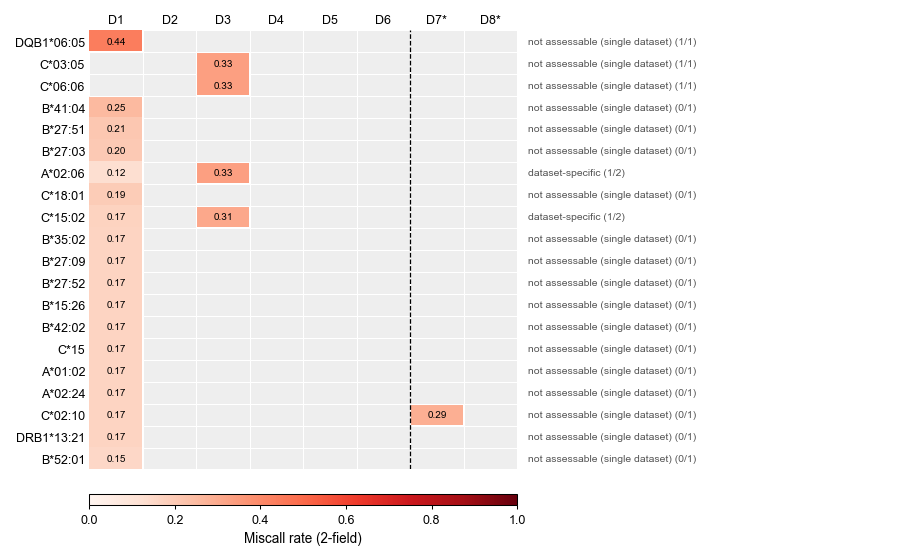

In [36]:
fig = plt.figure(figsize=(150 * MM, 92 * MM), layout="constrained")
gs = fig.add_gridspec(2, 2, height_ratios=[1, 0.025], width_ratios=[1, 0.42])
ax, cax = fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[1, 0])
fig.add_subplot(gs[:, 1]).set_axis_off()
draw_dataset_heatmap(ax, cax, order_desc, datasets)
save_fig(fig, "fig7_supp_a_heatmap")
plt.show()


## Supplementary Figure 7b: each dataset's own top-N ranking


In [37]:
TALLY_CSV = os.path.join(OUT_DIR, "allele_miscall_by_dataset.csv")
N_MAX = 20   # the original Figure 7's N


def load_tally(path: str = TALLY_CSV) -> pd.DataFrame:
    df = pd.read_csv(path)
    need = {"Dataset", "Locus", "Allele", "Total", "Mis", "MisclassificationRate%"}
    missing = need - set(df.columns)
    if missing:
        raise ValueError(f"{path} is missing required columns: {sorted(missing)}")
    recomputed = 100.0 * df["Mis"] / df["Total"]
    if not np.allclose(recomputed, df["MisclassificationRate%"], atol=1e-6):
        raise AssertionError(f"{path} is internally inconsistent: rate != 100*Mis/Total.")
    if (df["Mis"] > df["Total"]).any():
        raise AssertionError(f"{path}: Mis > Total for some rows.")
    return df


def top_n_for_dataset(df: pd.DataFrame, ds: int,
                      n_max: int = N_MAX, min_total: int = MIN_TOTAL) -> pd.DataFrame:
    """That dataset's OWN ranking: rank only its own rows, by its own rate.
    Deterministic tie-break (rate desc, Total desc, Allele asc)."""
    sub = df[(df["Dataset"] == ds) & (df["Total"] >= min_total)].copy()
    sub = sub.sort_values(["MisclassificationRate%", "Total", "Allele"],
                          ascending=[False, False, True])
    n = min(n_max, len(sub))
    out = sub.head(n).reset_index(drop=True)
    out["RankInDataset"] = np.arange(1, len(out) + 1)
    return out


In [38]:
df_c = load_tally()
tops = {ds: top_n_for_dataset(df_c, ds, N_MAX, MIN_TOTAL) for ds in DISPLAY_SCOPE}


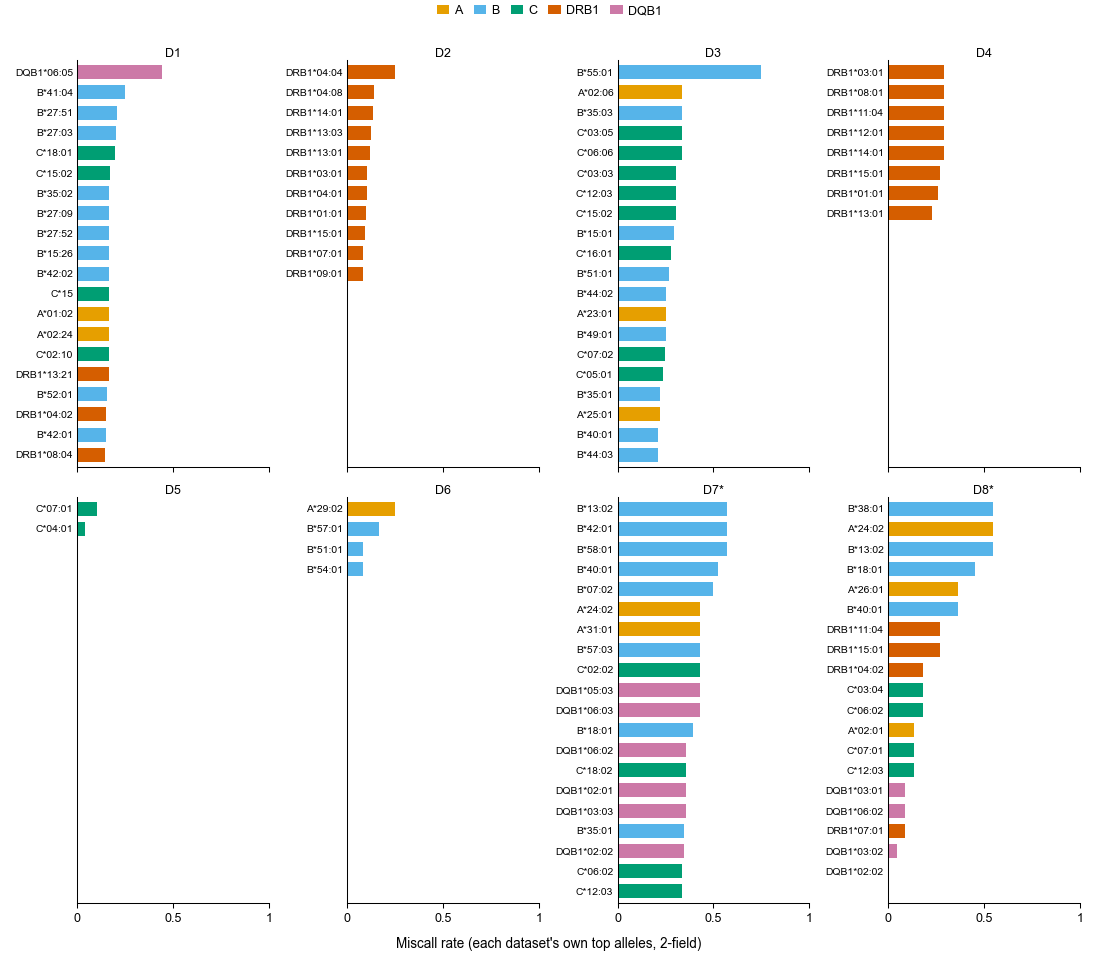

In [39]:
fig, axes = plt.subplots(2, 4, figsize=(COL2, 160 * MM), sharex=True, layout="constrained")
max_n = max(len(t) for t in tops.values())
for ax, ds in zip(axes.flat, DISPLAY_SCOPE):
    d = tops[ds].iloc[::-1].reset_index(drop=True)
    if len(d) == 0:
        ax.set_visible(False)
        continue
    y = np.arange(len(d))
    ax.barh(y, d["MisclassificationRate%"] / 100, height=0.7, color=[palette[L] for L in d["Locus"]])
    ax.set_yticks(y, d["Allele"], fontsize=5)
    ax.tick_params(axis="y", length=0)
    ax.set_ylim(len(d) - max_n - 0.6, len(d) - 0.4)
    ax.set_xlim(0, 1)
    ax.set_xticks([0, 0.5, 1], ["0", "0.5", "1"])
    ax.set_title(f"D{ds}" + ("*" if ds not in MAIN_SCOPE else ""), fontsize=6, pad=1.5)
fig.supxlabel("Miscall rate (each dataset's own top alleles, 2-field)", fontsize=6.5)
fig.legend(*locus_handles(), loc="outside upper center", ncol=5)
save_fig(fig, "fig7_supp_b_own_topN")
plt.show()


In [40]:
# ---- panel c side tables (recurrence across datasets' own top-N lists) ----
plotted = pd.concat(
    [t.assign(InMainScope=(ds in MAIN_SCOPE),
              ToolCoverage=REDUCED_COVERAGE.get(ds, "12/12 tools"))
     for ds, t in tops.items() if len(t)],
    ignore_index=True)
cols = ["Dataset", "InMainScope", "ToolCoverage", "RankInDataset", "Locus",
        "Allele", "Total", "Mis", "MisclassificationRate%", "GSSlots", "GSSamples"]
plotted = plotted[[c for c in cols if c in plotted.columns]]
p_plotted = os.path.join(OUT_DIR, "allele_miscall_top_per_dataset_own_ranking.csv")
plotted.to_csv(p_plotted, index=False)

main_tops = {ds: tops[ds] for ds in MAIN_SCOPE if len(tops[ds])}
in_top = {}
for ds, t in main_tops.items():
    for r in t.itertuples():
        in_top.setdefault(r.Allele, []).append(ds)

rankable_in = {}
for ds in MAIN_SCOPE:
    sub = df_c[(df_c["Dataset"] == ds) & (df_c["Total"] >= MIN_TOTAL)]
    for a in sub["Allele"]:
        rankable_in.setdefault(a, []).append(ds)

rec_rows = []
for a, dss in sorted(in_top.items()):
    rec_rows.append({
        "Allele": a,
        "Locus": plotted.loc[plotted["Allele"] == a, "Locus"].iloc[0],
        "NDatasetsInOwnTopN_D1toD6": len(dss),
        "DatasetsInOwnTopN": "+".join(f"D{d}" for d in sorted(dss)),
        "NDatasetsRankable_D1toD6": len(rankable_in.get(a, [])),
        "DatasetsRankable": "+".join(f"D{d}" for d in sorted(rankable_in.get(a, []))),
        "Recurring": len(dss) >= 2,
        "HadTheOpportunity": len(rankable_in.get(a, [])) >= 2,
    })
rec = pd.DataFrame(rec_rows).sort_values(
    ["NDatasetsInOwnTopN_D1toD6", "Allele"], ascending=[False, True])
p_rec = os.path.join(OUT_DIR, "allele_miscall_recurring_across_own_topN.csv")
rec.to_csv(p_rec, index=False)

print(f"wrote {os.path.relpath(p_plotted, REPO)}\nwrote {os.path.relpath(p_rec, REPO)}")
print(f"Union of D1-D6 own-top-N lists: {len(rec)} distinct alleles; "
     f"{int(rec['Recurring'].sum())} recurring in >=2 datasets.")


wrote data/final/allele_miscall_top_per_dataset_own_ranking.csv
wrote data/final/allele_miscall_recurring_across_own_topN.csv
Union of D1-D6 own-top-N lists: 58 distinct alleles; 7 recurring in >=2 datasets.


## Cross-dataset scorability of the top-20 alleles

Which of the pooled top-20 alleles can be scored in more than one dataset (inputs for the alluvial prototype at the end).


In [41]:
def load_de():
    brk = pd.read_csv(os.path.join(OUT_DIR, "allele_miscall_top20_by_dataset.csv"))
    cls = pd.read_csv(os.path.join(OUT_DIR, "allele_miscall_top20_classification.csv"))
    order = list(cls["Allele"])
    locus_of = dict(zip(cls["Allele"], cls["Locus"]))
    pooled = dict(zip(cls["Allele"], cls["PooledMisclassificationRate%"]))
    return brk, order, locus_of, pooled


In [42]:
brk_de, order_de, locus_of_de, pooled_de = load_de()
_scored = brk_de[brk_de["State"] == "scored"].sort_values("Dataset")
_pts = {a: [(int(r.Dataset), float(r["MisclassificationRate%"]), int(r.Total)) for _, r in g.iterrows()]
        for a, g in _scored.groupby("Allele")}
multi = [(a, _pts[a]) for a in order_de if len(_pts.get(a, [])) >= 2]
single = [(a, _pts[a]) for a in order_de if len(_pts.get(a, [])) == 1]
print(f"alleles scorable in >=2 datasets: {len(multi)} ({', '.join(a for a, _ in multi)})")
print(f"alleles scorable in exactly 1 dataset: {len(single)}")


alleles scorable in >=2 datasets: 3 (A*02:06, C*15:02, C*02:10)
alleles scorable in exactly 1 dataset: 17


## Supplementary Figure 7a-d with the allele-level miss rate

The same four views as above, recomputed with Figure 7's metric (an allele counts as missed when a caller reports the locus but not that allele) and with Figure 7a's alleles in place of the pooled top-20. Within a dataset, each allele's rate is the median over callers. Files carry an `_allele_level` suffix; the pooled versions above are kept for comparison.

In [ ]:
# Supplementary Figure 7a-d redrawn with Figure 7's allele-level miss rate. Within a dataset an
# allele's rate is the median over callers of the share of its carriers the caller missed; the
# pooled-metric versions above are kept for comparison.
MIN_CARRIERS_DS = 3

allele_calls_all = allele_miss_by_tool(tools, DISPLAY_SCOPE)
allele_calls_all = allele_calls_all[~((allele_calls_all.Tool == "optitype")
                                      & ~allele_calls_all.Allele.str.startswith(CLASS_I_PREFIX))]
_by_tool = (allele_calls_all.groupby(["Dataset", "Tool", "Allele"])
            .agg(Locus=("Locus", "first"), Carriers=("Sample", "nunique"), Missed=("Missed", "sum"))
            .reset_index())
_by_tool["MissRate"] = _by_tool.Missed / _by_tool.Carriers
al_ds = (_by_tool.groupby(["Dataset", "Allele"])
         .agg(Locus=("Locus", "first"), MedianRate=("MissRate", "median"), Callers=("Tool", "nunique"),
              Misses=("Missed", "sum"))
         .reset_index())
al_ds = al_ds.merge(allele_calls_all.groupby(["Dataset", "Allele"]).Sample.nunique().rename("Carriers").reset_index(),
                    on=["Dataset", "Allele"])
al_ds = al_ds.sort_values(["Dataset", "Locus", "MedianRate", "Allele"], ascending=[True, True, False, True])
al_ds.to_csv("../../data/final/fig7_allele_level_by_dataset.csv", index=False, float_format="%.6f")
al_scored = al_ds[al_ds.Carriers >= MIN_CARRIERS_DS]
hard_order7 = hard7.Allele.tolist()  # Figure 7a order, hardest first


def draw_allele_level_heatmap(ax, cax):
    present = set(zip(al_ds.Dataset, al_ds.Allele))
    rate = al_scored.set_index(["Allele", "Dataset"]).MedianRate
    mat = np.array([[rate.get((a, d), np.nan) for d in DISPLAY_SCOPE] for a in hard_order7])
    im = ax.imshow(mat, cmap=RATE_CMAP, vmin=0, vmax=1, aspect="auto")
    for i, a in enumerate(hard_order7):
        scored = [d for d in DISPLAY_SCOPE if d in MAIN_SCOPE and not np.isnan(mat[i, DISPLAY_SCOPE.index(d)])]
        high = [d for d in scored if mat[i, DISPLAY_SCOPE.index(d)] >= ELEVATED_THRESHOLD / 100]
        for j, d in enumerate(DISPLAY_SCOPE):
            if (d, a) not in present:
                ax.add_patch(plt.Rectangle((j - 0.5, i - 0.5), 1, 1, facecolor=NOT_PRESENT_COLOR, edgecolor="white", lw=0.5))
            elif np.isnan(mat[i, j]):
                ax.text(j, i, "·", ha="center", va="center", fontsize=6, color="#999999")
            else:
                ax.text(j, i, f"{mat[i, j]:.2f}", ha="center", va="center", fontsize=4.8,
                        color="white" if mat[i, j] > 0.55 else "black")
        ax.text(len(DISPLAY_SCOPE) - 0.3, i, f"{len(high)}/{len(scored)}", ha="left", va="center", fontsize=5,
                color="#555555", clip_on=False)
    ax.axvline(len(MAIN_SCOPE) - 0.5, color="black", lw=0.6, ls="--")
    ax.set_xticks(range(len(DISPLAY_SCOPE)), [ds_title(d) for d in DISPLAY_SCOPE])
    ax.set_yticks(range(len(hard_order7)), hard_order7)
    ax.xaxis.tick_top()
    ax.tick_params(length=0)
    for sp in ax.spines.values():
        sp.set_visible(False)
    cb = ax.figure.colorbar(im, cax=cax, orientation="horizontal")
    cb.set_label("Median miss rate across callers (2-field)")
    cb.outline.set_linewidth(0.5)
    cb.ax.tick_params(width=0.5, length=2)


fig = plt.figure(figsize=(120 * MM, 80 * MM), layout="constrained")
gs7 = fig.add_gridspec(2, 2, height_ratios=[1, 0.03], width_ratios=[1, 0.12])
ax, cax = fig.add_subplot(gs7[0, 0]), fig.add_subplot(gs7[1, 0])
fig.add_subplot(gs7[:, 1]).set_axis_off()
draw_allele_level_heatmap(ax, cax)
save_fig(fig, "fig7_supp_a_heatmap_allele_level")
plt.show()

# b: each dataset's own hardest alleles
own_top7 = {d: (al_scored[(al_scored.Dataset == d) & (al_scored.MedianRate > 0)]
                .sort_values(["MedianRate", "Carriers", "Allele"], ascending=[False, False, True]).head(N_MAX))
            for d in DISPLAY_SCOPE}
fig, axes = plt.subplots(2, 4, figsize=(COL2, 160 * MM), sharex=True, layout="constrained")
max_n = max(len(t) for t in own_top7.values())
for ax, ds in zip(axes.flat, DISPLAY_SCOPE):
    d = own_top7[ds].iloc[::-1].reset_index(drop=True)
    ax.set_title(ds_title(ds), fontsize=6, pad=1.5)
    ax.tick_params(axis="x", labelbottom=True)
    if len(d) == 0:
        n_sc = int((al_scored.Dataset == ds).sum())
        ax.text(0.5, 0.5, f"no allele with >= {MIN_CARRIERS_DS} carriers\nand a miss rate above 0\n({n_sc} scored)",
                transform=ax.transAxes, ha="center", va="center", fontsize=5, color="#888888")
        ax.set_yticks([])
        ax.set_xlim(0, 1)
        ax.set_xticks([0, 0.5, 1], ["0", "0.5", "1"])
        continue
    y = np.arange(len(d))
    ax.barh(y, d.MedianRate, height=0.7, color=[palette[L] for L in d.Locus])
    ax.set_yticks(y, d.Allele, fontsize=5)
    ax.tick_params(axis="y", length=0)
    ax.set_ylim(len(d) - max_n - 0.6, len(d) - 0.4)
    ax.set_xlim(0, 1)
    ax.set_xticks([0, 0.5, 1], ["0", "0.5", "1"])
fig.supxlabel(f"Median miss rate across callers (each dataset's own alleles, >= {MIN_CARRIERS_DS} carriers)", fontsize=6.5)
fig.legend(*locus_handles(), loc="outside upper center", ncol=5)
save_fig(fig, "fig7_supp_b_own_topN_allele_level")
plt.show()

# c: which datasets the misses of the Figure 7a alleles come from (D1-D6)
miss_ds7 = (allele_calls_all[allele_calls_all.Allele.isin(hard_order7) & allele_calls_all.Dataset.isin(CORE_DS)]
            .groupby(["Allele", "Dataset"]).Missed.sum().unstack(fill_value=0)
            .reindex(index=hard_order7, columns=CORE_DS, fill_value=0))
share_ds7 = miss_ds7.div(miss_ds7.sum(axis=1), axis=0).fillna(0)
fig, ax = plt.subplots(figsize=(COL1, 70 * MM), layout="constrained")
yy = np.arange(len(hard_order7))[::-1]
left = np.zeros(len(hard_order7))
for d in CORE_DS:
    ax.barh(yy, share_ds7[d].values, left=left, height=0.7, color=DATASET_COLORS[d], label=f"D{d}")
    left += share_ds7[d].values
for yi, m in zip(yy, miss_ds7.sum(axis=1).values):
    ax.text(1.01, yi, str(int(m)), va="center", ha="left", fontsize=5, color="#666666")
ax.set_yticks(yy, hard_order7)
ax.tick_params(axis="y", length=0)
ax.set_ylim(-0.6, len(yy) - 0.4)
ax.set_xlim(0, 1)
ax.set_xlabel("Share of the allele's misses (D1-D6)")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=6, columnspacing=0.6)
save_fig(fig, "fig7_supp_c_dataset_share_allele_level")
plt.show()

# d: spread of allele miss rates by locus within each dataset
fig, axes = plt.subplots(2, 4, figsize=(COL2, 82 * MM), sharex=True, sharey=True, layout="constrained")
for ax, d in zip(axes.flat, DISPLAY_SCOPE):
    sub = al_scored[al_scored.Dataset == d].rename(columns={"MedianRate": "MisclassificationRate"})
    draw_allele_spread(ax, sub, seed=d, show_n=False, xmax=1)
    ax.set_title(f"{ds_title(d)} ({len(sub)} alleles)", fontsize=6, pad=1.5)
    ax.set_xticks([0, 0.5, 1], ["0", "0.5", "1"])
    ax.label_outer()
fig.supxlabel(f"Median miss rate per allele across callers (2-field, >= {MIN_CARRIERS_DS} carriers)", fontsize=6.5)
save_fig(fig, "fig7_supp_d_per_dataset_rates_allele_level")
plt.show()

print("alleles scored per dataset (>= %d carriers):" % MIN_CARRIERS_DS,
      al_scored.groupby("Dataset").size().to_dict())
print("Figure 7a alleles with median miss rate >= 30% (datasets):")
print(al_scored[al_scored.Allele.isin(hard_order7) & (al_scored.MedianRate >= 0.3)]
      .groupby("Allele").Dataset.apply(lambda x: ", ".join(f"D{d}" for d in x)).reindex(hard_order7).dropna().to_string())

# Figure 8: read length accuracy

In [43]:
import re
import os
import pandas as pd

def compute_readlength_accuracy(
    tools:       list,
    read_lengths:list,
    gs_file:     str  = "../../data/gold_standard/readlength_gs.csv",
    results_dir: str  = "../../data/interim/read_length/standard"
) -> pd.DataFrame:
    """
    For each tool in `tools` and each read length in `read_lengths`:
      - load predictions from results_dir/{tool}_{rl}.csv
      - merge with gs_file on `Run` vs `ERR`
      - for each sample×locus, split GS ambiguities on '/', split predictions on '/',
        reformat to two‐field, and then count:
          total_calls   += 1 per predicted allele
          correct_calls += 1 if that allele is in the GS set
      - finally compute accuracy = correct_calls / total_calls
    Returns a DataFrame with columns:
      Tool | ReadLength | CorrectCalls | TotalCalls | Accuracy
    """
    # load the single GS file
    gs_df = pd.read_csv(gs_file)
    id_col = "Run"

    # dynamically find your loci
    loci = sorted({c.split(".")[0] for c in gs_df.columns if c != id_col})

    rows = []
    for tool in tools:
        for rl in read_lengths:
            pred_path = os.path.join(results_dir, f"{tool}_{rl}.csv")
            if not os.path.exists(pred_path):
                print(f"[!] Missing predictions: {pred_path}")
                continue

            pre_df = pd.read_csv(pred_path)
            id_pre = pre_df.columns[0]
            # Skip files where the first column is a sample ID (non-standard format)
            if re.match(r'^(ERR|SRR|DRR)\d+$', id_pre):
                print(f"[!] Skipping {pred_path}: non-standard format (samples as columns)")
                continue
            merged = pd.merge(
                gs_df, pre_df,
                left_on=id_col, right_on=id_pre,
                suffixes=("_gs","_pre"),
                how="inner"
            )

            correct_calls = 0
            total_calls   = 0

            for _, row in merged.iterrows():
                for locus in loci:
                    # build the GS set (allowing "/")
                    gvals = []
                    for col in (f"{locus}_gs", f"{locus}.1_gs"):
                        v = row.get(col)
                        if isinstance(v, str) and v.strip():
                            gvals += v.split("/")
                    if not gvals:
                        continue
                    gs_set = {reformat_allele(x) for x in gvals}
                    gs_set.discard(None)
                    if not gs_set:
                        continue

                    # build the predicted list (allowing "/")
                    pvals = []
                    for col in (f"{locus}_pre", f"{locus}.1_pre"):
                        v = row.get(col)
                        if isinstance(v, str) and v.strip():
                            pvals += v.split("/")
                    # if no call, skip this locus
                    if not pvals:
                        continue
                    # enforce exactly two tries
                    if len(pvals) == 1:
                        pvals = pvals * 2
                    else:
                        pvals = pvals[:2]

                    # reformat and tally
                    for allele in pvals:
                        # Some tools use a literal no-call token ("NA"/"na"/"no") instead of
                        # blank; skipped rather than counted as a wrong call.
                        if isinstance(allele, str) and allele.strip().lower() in ("na", "no"):
                            continue
                        reform = reformat_allele(allele)
                        total_calls += 1
                        if reform in gs_set:
                            correct_calls += 1

            accuracy = correct_calls / total_calls if total_calls else 0.0
            rows.append({
                "Tool":         tool,
                "ReadLength":   rl,
                "CorrectCalls": correct_calls,
                "TotalCalls":   total_calls,
                "Accuracy":     accuracy
            })

    return pd.DataFrame(rows)

# -------------------------------------------------------
# 3) Example invocation & quick plot
# -------------------------------------------------------
if __name__ == "__main__":
    tools        = ["arcas", "optitype", "seq2hla",
                    "phlat", "hlavbseq", "hlahd", "hlaforest",
                    "hlapers", "hlaminer", "rna2hla"]
    read_lengths = [36, 51, 76, 101, 126]

    df_rl_acc = compute_readlength_accuracy(
        tools, read_lengths,
        gs_file="../../data/gold_standard/readlength_gs.csv",
        results_dir="../../data/interim/read_length/standard"
    )
df_rl_acc

,Tool,ReadLength,CorrectCalls,TotalCalls,Accuracy
0,arcas,36,32,48,0.666667
1,arcas,51,42,50,0.840000
2,arcas,76,49,50,0.980000
3,arcas,101,9,10,0.900000
4,arcas,126,9,10,0.900000
5,optitype,36,24,24,1.000000
6,optitype,51,24,24,1.000000
7,optitype,76,24,24,1.000000
8,optitype,101,0,0,0.000000
9,optitype,126,0,0,0.000000


## Read-length cohort confound

`readlength_gs.csv` mixes two cohorts: 4 samples with all five loci but reads only at 36-76 bp, and 8 DRB1-only samples at all five lengths. All-loci accuracy is therefore only comparable up to 76 bp; DRB1 on the same 8 samples is the clean read-length comparison.


In [44]:
import os
import re
import pandas as pd

def compute_readlength_accuracy_by_locus(tools, read_lengths,
                                          gs_file="../../data/gold_standard/readlength_gs.csv",
                                          results_dir="../../data/interim/read_length/standard"):
    gs_df = pd.read_csv(gs_file)
    id_col = "Run"
    loci = sorted({c.split(".")[0] for c in gs_df.columns if c != id_col})
    rows = []
    for tool in tools:
        for rl in read_lengths:
            pred_path = os.path.join(results_dir, f"{tool}_{rl}.csv")
            if not os.path.exists(pred_path):
                continue
            pre_df = pd.read_csv(pred_path)
            id_pre = pre_df.columns[0]
            if re.match(r"^(ERR|SRR|DRR)\d+$", id_pre):
                continue
            merged = pd.merge(gs_df, pre_df, left_on=id_col, right_on=id_pre,
                              suffixes=("_gs", "_pre"), how="inner")
            n_err_samples = merged[id_col].astype(str).str.startswith("ERR").sum()
            for locus in loci:
                correct = total = 0
                for _, row in merged.iterrows():
                    gvals = []
                    for col in (f"{locus}_gs", f"{locus}.1_gs"):
                        v = row.get(col)
                        if isinstance(v, str) and v.strip():
                            gvals += v.split("/")
                    if not gvals:
                        continue
                    gs_set = {reformat_allele(x) for x in gvals}
                    gs_set.discard(None)
                    if not gs_set:
                        continue
                    pvals = []
                    for col in (f"{locus}_pre", f"{locus}.1_pre"):
                        v = row.get(col)
                        if isinstance(v, str) and v.strip():
                            pvals += v.split("/")
                    if not pvals:
                        continue
                    pvals = pvals * 2 if len(pvals) == 1 else pvals[:2]
                    for allele in pvals:
                        if isinstance(allele, str) and allele.strip().lower() in ("na", "no"):
                            continue
                        reform = reformat_allele(allele)
                        total += 1
                        if reform in gs_set:
                            correct += 1
                if total:
                    rows.append({"Tool": tool, "ReadLength": rl, "Locus": locus,
                                "Correct": correct, "Total": total,
                                "Accuracy": correct / total, "ERRSamplesPresent": n_err_samples})
    return pd.DataFrame(rows)


rl_tools = ["arcas", "optitype", "seq2hla", "phlat", "hlavbseq", "hlahd",
            "hlaforest", "hlapers", "hlaminer", "rna2hla"]
rl_lengths = [36, 51, 76, 101, 126]

df_rl_locus = compute_readlength_accuracy_by_locus(rl_tools, rl_lengths)

pooled_check = df_rl_locus.groupby(["Tool", "ReadLength"])[["Correct", "Total"]].sum().reset_index()
pooled_check["Accuracy"] = pooled_check.Correct / pooled_check.Total
print("Confirms the confound directly -- ERR (non-DRB1-capable) samples present per read length:")
print(df_rl_locus.groupby("ReadLength")["ERRSamplesPresent"].first().to_string())

df_drb1 = df_rl_locus[df_rl_locus.Locus == "DRB1"]
print("\nPooled (current Fig 8, all loci -- confounded past 76bp) vs. DRB1-only (clean, all 5 lengths):")
cmp = pooled_check.pivot(index="Tool", columns="ReadLength", values="Accuracy").add_suffix("_pooled")
cmp_drb1 = df_drb1.pivot(index="Tool", columns="ReadLength", values="Accuracy").add_suffix("_DRB1only")
print(pd.concat([cmp, cmp_drb1], axis=1).round(3).to_string())


Confirms the confound directly -- ERR (non-DRB1-capable) samples present per read length:
ReadLength
36     4
51     4
76     4
101    0
126    0

Pooled (current Fig 8, all loci -- confounded past 76bp) vs. DRB1-only (clean, all 5 lengths):
ReadLength  36_pooled  51_pooled  76_pooled  101_pooled  126_pooled  36_DRB1only  51_DRB1only  76_DRB1only  101_DRB1only  126_DRB1only
Tool                                                                                                                                  
arcas           0.667      0.840      0.980       0.900       0.900        0.938        0.944        0.944         0.900         0.900
hlaforest       0.611      0.615      0.712       0.643       0.643        0.636        0.650        0.850         0.643         0.643
hlahd           0.580      0.885      0.904       0.750       0.750        0.556        0.800        0.750         0.750         0.750
hlaminer        0.300      0.083      0.286       0.250       0.200        0.300   

## Figure 8: Accuracy Against Read Length

DRB1 on the same 8 samples at every length (black); all loci only where the cohort is constant, 36-76 bp (grey).


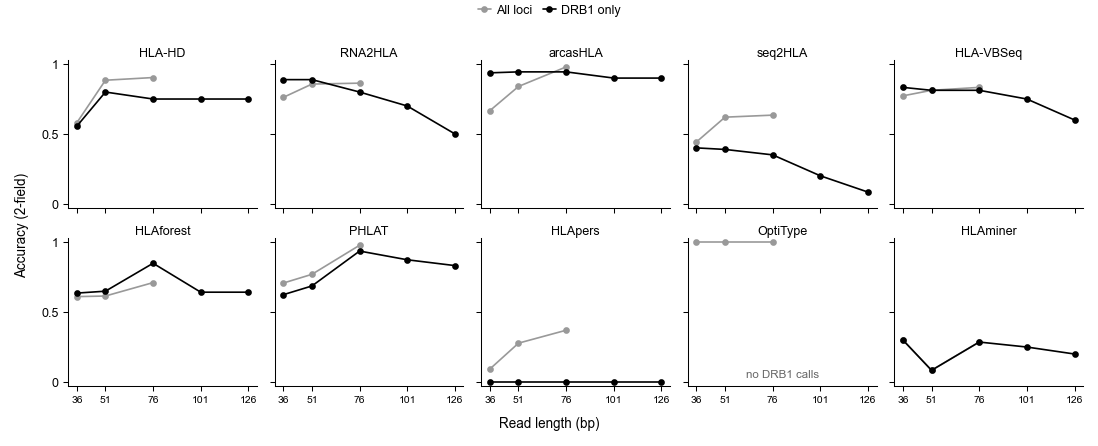

In [45]:
RL_COHORT_MAX = 76   # last read length at which the full-locus (ERR) cohort is still present
rl_order = [t for t in TOOL_ORDER[::-1] if t in set(pooled_check["Tool"])]


def draw_readlength_grid(fig, pooled_full=False):
    axes = fig.subplots(2, 5, sharex=True, sharey=True)
    for ax, t in zip(axes.flat, rl_order):
        pc = pooled_check[pooled_check.Tool == t].sort_values("ReadLength")
        if not pooled_full:
            pc = pc[pc.ReadLength <= RL_COHORT_MAX]
        ax.plot(pc.ReadLength, pc.Accuracy, color="#999999", lw=0.8, marker="o", ms=2.2,
                ls="--" if pooled_full else "-", label="All loci")
        d = df_drb1[df_drb1.Tool == t].sort_values("ReadLength")
        if len(d):
            ax.plot(d.ReadLength, d.Accuracy, color="black", lw=0.8, marker="o", ms=2.2, label="DRB1 only")
        else:
            ax.text(0.5, 0.06, "no DRB1 calls", transform=ax.transAxes, ha="center", fontsize=5.5, color="#666666")
        if pooled_full:
            ax.axvline(RL_COHORT_MAX + 12.5, color="#BBBBBB", lw=0.5, ls=":")
        ax.set_title(TOOL_NAME[t], fontsize=6, pad=1.5)
        ax.set_xticks(rl_lengths, [str(r) for r in rl_lengths], fontsize=5)
        ax.set_ylim(-0.03, 1.03)
        ax.set_yticks([0, 0.5, 1], ["0", "0.5", "1"])
    fig.supxlabel("Read length (bp)", fontsize=6.5)
    fig.supylabel("Accuracy (2-field)", fontsize=6.5)
    h, l = axes.flat[0].get_legend_handles_labels()
    fig.legend(h, l, loc="outside upper center", ncol=2)
    return axes


fig = plt.figure(figsize=(COL2, 72 * MM), layout="constrained")
draw_readlength_grid(fig)
save_fig(fig, "fig8_readlength_accuracy")
plt.show()


### Supplementary Figure 8: the cohort switch

The all-loci curve extended past 76 bp (dashed), where the sample set and the loci change at once.


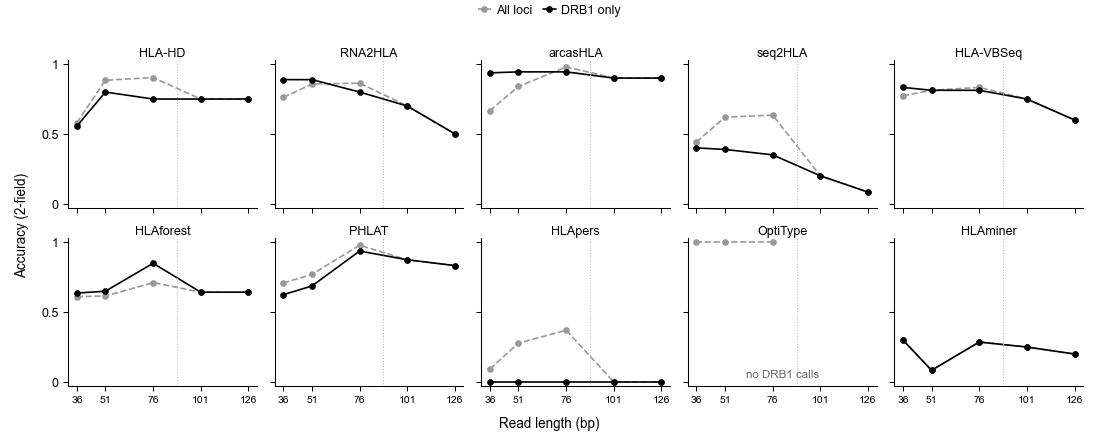

In [46]:
fig = plt.figure(figsize=(COL2, 72 * MM), layout="constrained")
draw_readlength_grid(fig, pooled_full=True)
save_fig(fig, "fig8_supp_cohort_confound_drb1_only")
plt.show()


# Figure 9: Accuracy between Europeans and Yoruban Samples


## Ancestry Bulk Accuracy

In [47]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.patches as mpatches
from statsmodels.stats.proportion import proportions_ztest
# -----------------------------------------------------------------------------
# 1) Europe / Yorùba gold-standard subsets (kept in memory)
# -----------------------------------------------------------------------------
runs = pd.read_csv("../../data/input/archive/SraRunTableD1.txt")
gs   = pd.read_csv("../../data/gold_standard/1_gs.csv", dtype=str)
euro = runs.loc[runs.Population.isin(["CEU","FIN","GBR","TSI"]), "Run"]
yri  = runs.loc[runs.Population=="YRI", "Run"]
gs_euro, gs_yri = gs[gs.Run.isin(euro)], gs[gs.Run.isin(yri)]

# -----------------------------------------------------------------------------
# 2) Compute accuracy + raw counts for 1-field and 2-field
# -----------------------------------------------------------------------------
tools   = ["arcas","optitype","seq2hla","hlaminer","phlat","hlavbseq","hlahd","hisat","hlaforest","hlapers","T1K","rna2hla"]
records = {1: [], 2: []}
counts  = {1: {}, 2: {}}

for res in (1,2):
    for t in tools:
        pred = f"../../data/interim/standard/{t}_d1.csv"
        try:
            ae, ce, te, nce, mi = calculate_accuracy(gs_euro, pred, resolution=res)
            ay, cy, ty, ncy, miy = calculate_accuracy(gs_yri,  pred, resolution=res)
        except FileNotFoundError:
            continue

        records[res].append({
            "Tool":   t,
            "Europe": ae,
            "Yorùba": ay
        })
        counts[res][t] = (ce, te, cy, ty)

df1 = pd.DataFrame(records[1]).set_index("Tool")
df2 = pd.DataFrame(records[2]).set_index("Tool")

# -----------------------------------------------------------------------------
# 3) Europe vs Yoruba: permutation test over individuals, BH-adjusted across tools
# -----------------------------------------------------------------------------
from statsmodels.stats.multitest import multipletests

_eur_ids = {_run2bio[r] for r in euro.astype(str) if r in _run2bio}
_yri_ids = {_run2bio[r] for r in yri.astype(str) if r in _run2bio}


def perm_bh(ps, loci, tools_, n_perm=10000, seed=20260925):
    d = ps[(ps.Dataset == 1) & ps.Locus.isin(loci)]
    g = d.groupby(["Tool", "Individual"])[["correct", "total"]].sum().reset_index()
    g = g[g.Individual.astype(str).isin(_eur_ids | _yri_ids)].copy()
    g["yri"] = g.Individual.astype(str).isin(_yri_ids)
    rng = np.random.default_rng(seed)
    raw = {}
    for t in tools_:
        s = g[g.Tool == t]
        C, T, Y = s.correct.values.astype(float), s.total.values.astype(float), s.yri.values
        if len(s) == 0 or T[Y].sum() == 0 or T[~Y].sum() == 0 or C.sum() in (0.0, T.sum()):
            raw[t] = np.nan
            continue
        obs = C[~Y].sum() / T[~Y].sum() - C[Y].sum() / T[Y].sum()
        n, nY = len(s), int(Y.sum())
        idx = np.argsort(rng.random((n_perm, n)), axis=1)[:, :nY]
        cY, tY = C[idx].sum(1), T[idx].sum(1)
        perm = (C.sum() - cY) / (T.sum() - tY) - cY / tY
        raw[t] = (1 + np.sum(np.abs(perm) >= abs(obs) - 1e-12)) / (n_perm + 1)
    ok = [t for t in tools_ if not np.isnan(raw[t])]
    adj = dict(zip(ok, multipletests([raw[t] for t in ok], method="fdr_bh")[1]))
    return {t: adj.get(t, np.nan) for t in tools_}, raw


ALL5 = ["A", "B", "C", "DRB1", "DQB1"]
pvals1, _raw1 = perm_bh(ps1, ALL5, list(df1.index))
pvals2, _raw2 = perm_bh(ps2, ALL5, list(df2.index))

# previous call-level z-test, kept only to show what changed
_old1 = {t: proportions_ztest([counts[1][t][0], counts[1][t][2]], [counts[1][t][1], counts[1][t][3]])[1] for t in df1.index}
_old2 = {t: proportions_ztest([counts[2][t][0], counts[2][t][2]], [counts[2][t][1], counts[2][t][3]])[1] for t in df2.index}
print("tools with a significant Europe-Yoruba difference (of %d):" % len(df1))
print("  1-field: old call-level z-test p<0.05 = %d | permutation over individuals, BH q<0.05 = %d"
      % (sum(v < 0.05 for v in _old1.values()), sum(v < 0.05 for v in pvals1.values() if v == v)))
print("  2-field: old call-level z-test p<0.05 = %d | permutation over individuals, BH q<0.05 = %d"
      % (sum(v < 0.05 for v in _old2.values()), sum(v < 0.05 for v in pvals2.values() if v == v)))

def p_to_stars(p):
    if   p<1e-4: return "****"
    elif p<1e-3: return "***"
    elif p<1e-2: return "**"
    elif p<0.05: return "*"
    return "ns"

tools with a significant Europe-Yoruba difference (of 12):
  1-field: old call-level z-test p<0.05 = 5 | permutation over individuals, BH q<0.05 = 1
  2-field: old call-level z-test p<0.05 = 9 | permutation over individuals, BH q<0.05 = 7


In [48]:
anc_acc = {1: df1.rename(columns={"Yorùba": "Yoruba"}), 2: df2.rename(columns={"Yorùba": "Yoruba"})}
anc_q = {1: pvals1, 2: pvals2}


def draw_ancestry(ax, eur, yri, q, labels=True, legend=False, not_called=None):
    order = [t for t in TOOL_ORDER if t in eur.index]
    for k, t in enumerate(order):
        e, r = eur[t], yri[t]
        nc = (t in not_called) if not_called is not None else (e == 0 and r == 0)
        if np.isnan(e) or np.isnan(r) or nc:
            ax.text(0.02, k, "not called", va="center", ha="left", fontsize=5.5, color="#666666")
            continue
        ax.plot([e, r], [k, k], color="#BBBBBB", lw=0.8, zorder=1)
        ax.scatter([e], [k], s=10, color=palette["Europe"], linewidths=0, zorder=3, label="Europe" if k == 0 else None)
        ax.scatter([r], [k], s=10, color=palette["Yoruba"], linewidths=0, zorder=3, label="Yoruba" if k == 0 else None)
        qv = q.get(t, np.nan)
        if qv == qv and qv < 0.05:
            ax.text(1.02, k, p_to_stars(qv), transform=ax.get_yaxis_transform(), va="center", ha="left",
                    fontsize=6, clip_on=False)
    ax.set_yticks(range(len(order)), tool_labels(order))
    if not labels:
        ax.tick_params(axis="y", labelleft=False)
    ax.tick_params(axis="y", length=0)
    ax.set_ylim(-0.6, len(order) - 0.4)
    ax.set_xlim(0, 1)
    if legend:
        ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2, handletextpad=0.2)


## Ancestry Bulk Accuracy by Class

In [49]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns



CLASS_I  = {"A", "B", "C"}
CLASS_II = {"DRB1", "DQB1"}

def calculate_class_counts(gs, pre_file, resolution=2):
    """
    Returns: (ci, ti, cii, tii)
      ci   = # correct Class I alleles
      ti   = total Class I calls
      cii  = # correct Class II alleles
      tii  = total Class II calls
    """
    gs_df = gs.copy() if isinstance(gs, pd.DataFrame) else pd.read_csv(gs, dtype=str)
    pr_df = pd.read_csv(pre_file, dtype=str)
    id_gs, id_pr = gs_df.columns[0], pr_df.columns[0]
    gs_df[id_gs] = gs_df[id_gs].str.strip()
    pr_df[id_pr] = pr_df[id_pr].str.strip()
    pr_df = pr_df.rename(columns={c:f"{c}_pre" for c in pr_df.columns if c!=id_pr})

    loci  = get_dynamic_loci(gs_df)
    merged = pd.merge(gs_df, pr_df, left_on=id_gs, right_on=id_pr, how="inner")

    ci=ti=cii=tii=0
    for _, row in merged.iterrows():
        for L in loci:
            # gather GS
            gs_raw = []
            for suf in ("",".1"):
                col = f"{L}{suf}"
                if col in row and pd.notna(row[col]):
                    gs_raw += [x.strip() for x in str(row[col]).split("/")]
            if not gs_raw:
                continue

            # gather PR
            pr_raw = []
            for suf in ("_pre",".1_pre"):
                col = f"{L}{suf}"
                if col in row and pd.notna(row[col]):
                    pr_raw += [x.strip() for x in str(row[col]).split("/")]
            result = score_pair(gs_raw, pr_raw, resolution)
            if result is None:
                continue
            c, m, nc = result
            correct = c
            # we only care about correct vs total
            if L in CLASS_I:
                ti   += 2
                ci   += correct
            elif L in CLASS_II:
                tii  += 2
                cii  += correct

    return ci, ti, cii, tii

# ——————————————————————————————————————————————————————————————————————
# 3) Compute Europe vs Yorùba for Class I & Class II at 1-field and 2-field
# ——————————————————————————————————————————————————————————————————————
runs = pd.read_csv("../../data/input/archive/SraRunTableD1.txt")
gs   = pd.read_csv("../../data/gold_standard/1_gs.csv", dtype=str)
euro = runs.loc[runs.Population.isin(["CEU","FIN","GBR","TSI"]), "Run"]
yri  = runs.loc[runs.Population=="YRI",            "Run"]
gs_euro, gs_yri = gs[gs.Run.isin(euro)], gs[gs.Run.isin(yri)]

tools   = ["arcas","optitype","seq2hla","hlaminer","phlat","hlavbseq","hlahd","hisat","hlaforest","hlapers","T1K","rna2hla"]
records = {1:[], 2:[]}
counts  = {1:{}, 2:{}}

for res in (1,2):
    for t in tools:
        pred = f"../../data/interim/standard/{t}_d1.csv"
        try:
            ci_e, ti_e, cii_e, tii_e = calculate_class_counts(gs_euro, pred, resolution=res)
            ci_y, ti_y, cii_y, tii_y = calculate_class_counts(gs_yri,  pred, resolution=res)
        except FileNotFoundError:
            continue

        # store for z-tests
        counts[res][t] = (ci_e, ti_e, ci_y, ti_y, cii_e, tii_e, cii_y, tii_y)

        # build the DataFrame rows
        records[res].append({
            "Tool":        t,
            "ClassI_Eur":  ci_e/ti_e  if ti_e else np.nan,
            "ClassI_Yri":  ci_y/ti_y  if ti_y else np.nan,
            "ClassII_Eur": cii_e/tii_e if tii_e else np.nan,
            "ClassII_Yri": cii_y/tii_y if tii_y else np.nan,
        })

df1 = pd.DataFrame(records[1]).set_index("Tool")
df2 = pd.DataFrame(records[2]).set_index("Tool")



## Figure 9: Europe vs Yoruba accuracy (D1)

Permutation test over individuals, Benjamini-Hochberg across tools: * q < 0.05, ** q < 0.01, *** q < 0.001, **** q < 1e-4.


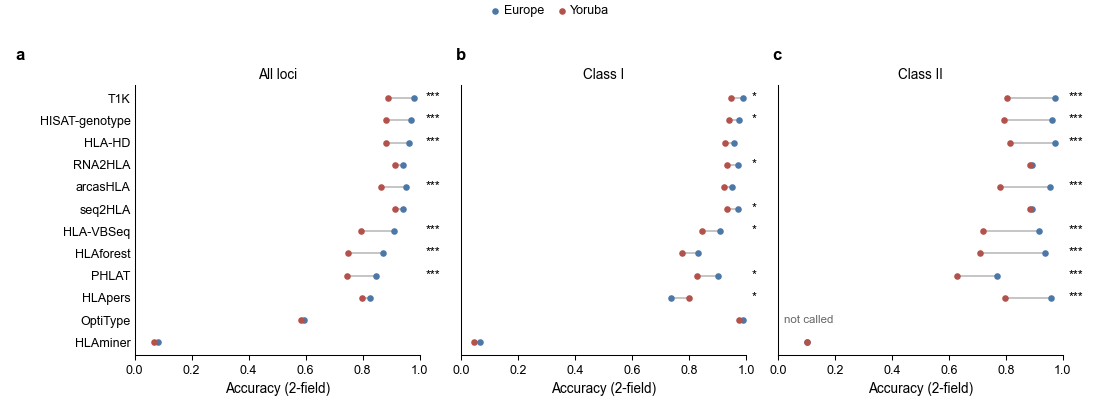

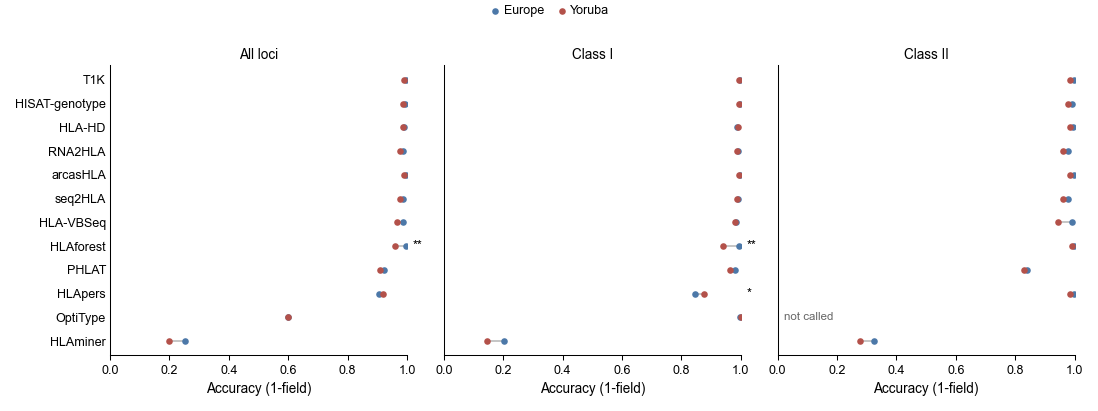

In [50]:
def do_perm(res):
    ps = ps1 if res == 1 else ps2
    q_i, _ = perm_bh(ps, CLASS_I_LOCI, list(df1.index))
    q_ii, _ = perm_bh(ps, CLASS_II_LOCI, list(df1.index))
    return q_i, q_ii


anc_q_class = {res: do_perm(res) for res in (1, 2)}


def draw_ancestry_row(axes, res):
    a = anc_acc[res]
    q_i, q_ii = anc_q_class[res]
    panels = (("All loci", a["Europe"], a["Yoruba"], anc_q[res]),
              ("Class I", df_class[res]["ClassI_Eur"], df_class[res]["ClassI_Yri"], q_i),
              ("Class II", df_class[res]["ClassII_Eur"], df_class[res]["ClassII_Yri"], q_ii))
    for k, (ax, (name, e, r, q)) in enumerate(zip(axes, panels)):
        draw_ancestry(ax, e, r, q, labels=(k == 0))
        ax.set_title(name)
        ax.set_xlabel(f"Accuracy ({res}-field)")
    h, l = axes[0].get_legend_handles_labels()
    return h, l


df_class = {1: df1, 2: df2}
for res, stem in ((2, "fig9_ancestry_accuracy"), (1, "fig9_supp_ancestry_accuracy_1field")):
    fig, axes = plt.subplots(1, 3, figsize=(COL2, 66 * MM), sharey=True, layout="constrained")
    h, l = draw_ancestry_row(axes, res)
    fig.legend(h, l, loc="outside upper center", ncol=2, handletextpad=0.2)
    if res == 2:
        for ax, letter in zip(axes, "abc"):
            ax.text(-0.02 if letter != "a" else -0.42, 1.08, letter, transform=ax.transAxes,
                    fontsize=8, fontweight="bold", ha="left", va="bottom")
        save_fig(fig, "Figure9")
    save_fig(fig, stem)
    plt.show()


# Figure 10: Ancestral Accuracy by Locus

In [51]:
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

def compute_locus_accuracy_by_ancestry(
    gs_df: pd.DataFrame,
    tools: list,
    resolution: int = 2,
    pred_dir: str = "../../data/interim/standard",
    ancestry: str = None
) -> pd.DataFrame:
    # 3-outcome contract, no filter_option.
    loci = get_dynamic_loci(gs_df)

    # make sure GS ID column is stripped
    gs_df = gs_df.copy()
    gs_df.iloc[:,0] = gs_df.iloc[:,0].astype(str).str.strip()

    rows = []
    for t in tools:
        pred_f = os.path.join(pred_dir, f"{t}_d1.csv")
        if not os.path.exists(pred_f):
            continue

        pr_df = pd.read_csv(pred_f, dtype=str)
        pr_df.iloc[:,0] = pr_df.iloc[:,0].astype(str).str.strip()
        pr_df = pr_df.rename(columns={c:f"{c}_pre" for c in pr_df.columns if c!=pr_df.columns[0]})

        merged = pd.merge(
            gs_df, pr_df,
            left_on=gs_df.columns[0],
            right_on=pr_df.columns[0],
            how="inner"
        )

        # initialize counters
        cnt = {L:{"correct":0,"miscalled":0,"no_call":0,"total":0}
               for L in loci}

        for _, row in merged.iterrows():
            for L in loci:
                # GS alleles
                gs_raw = []
                for suf in ("", ".1"):
                    col = f"{L}{suf}"
                    if col in row and pd.notna(row[col]):
                        gs_raw += [x.strip() for x in str(row[col]).split("/")]
                if not gs_raw:
                    continue

                # PR alleles
                pr_raw = []
                for suf in ("_pre", ".1_pre"):
                    col = f"{L}{suf}"
                    if col in row and pd.notna(row[col]):
                        pr_raw += [x.strip() for x in str(row[col]).split("/")]
                result = score_pair(gs_raw, pr_raw, resolution)
                if result is None:
                    continue
                cnt[L]["total"] += 2
                c,m,z = result

                cnt[L]["correct"]   += c
                cnt[L]["miscalled"] += m
                cnt[L]["no_call"]   += z

        # flatten
        for L in loci:
            c   = cnt[L]["correct"]
            mis = cnt[L]["miscalled"]
            nc  = cnt[L]["no_call"]
            tot = cnt[L]["total"]
            acc = c/tot if tot else np.nan
            rows.append({
                "Ancestry":        ancestry,
                "Tool":             t,
                "Locus":            L,
                "CorrectAlleles":   c,
                "MiscalledAlleles": mis,
                "NoCallAlleles":    nc,
                "TotalAlleles":     tot,
                "Accuracy":         acc
            })

    return pd.DataFrame(rows)

# =============================================================================
# 3) Build Europe / Yorùba GS and compute
# =============================================================================
runs    = pd.read_csv("../../data/input/archive/SraRunTableD1.txt")
gs_all  = pd.read_csv("../../data/gold_standard/1_gs.csv")

eur_ids = runs.loc[runs.Population.isin(["CEU","FIN","GBR","TSI"]),"Run"]
yor_ids = runs.loc[runs.Population=="YRI",                   "Run"]

europe_gs = gs_all[gs_all.Run.isin(eur_ids)].reset_index(drop=True)
yoruba_gs = gs_all[gs_all.Run.isin(yor_ids)].reset_index(drop=True)

tools = ["arcas","optitype","seq2hla","hlaminer","phlat",
         "hlavbseq","hlahd","hisat","hlaforest","hlapers","T1K","rna2hla"]

df_eur = compute_locus_accuracy_by_ancestry(
    europe_gs, tools,
    resolution=2,
    pred_dir="../../data/interim/standard",
    ancestry="Europe"
)
df_yor = compute_locus_accuracy_by_ancestry(
    yoruba_gs, tools,
    resolution=2,
    pred_dir="../../data/interim/standard",
    ancestry="Yoruba"
)

df_locus_all = pd.concat([df_eur, df_yor], ignore_index=True)

# =============================================================================
# 4) Pivot to wide for plotting
# =============================================================================
loci = ["A","B","C","DRB1","DQB1"]

# per‐ancestry accuracy
df_eur_acc = (
    df_locus_all[df_locus_all.Ancestry=="Europe"]
    .pivot(index="Tool",   columns="Locus", values="Accuracy")
    .reindex(index=tools, columns=loci)
)
df_yor_acc = (
    df_locus_all[df_locus_all.Ancestry=="Yoruba"]
    .pivot(index="Tool",   columns="Locus", values="Accuracy")
    .reindex(index=tools, columns=loci)
)

# build SE of differences
df_wide = (
    df_locus_all
    .pivot_table(
      index=["Tool","Locus"],
      columns="Ancestry",
      values=["Accuracy","TotalAlleles"],
      aggfunc="first"
    )
    .reset_index()
)
df_wide.columns = [
    f"{outer}_{inner}" if inner else outer
    for outer,inner in df_wide.columns
]
pE = df_wide["Accuracy_Europe"]; nE = df_wide["TotalAlleles_Europe"]
pY = df_wide["Accuracy_Yoruba"]; nY = df_wide["TotalAlleles_Yoruba"]
df_wide["Accuracy_Diff"] = pE - pY
df_wide["SE_Diff"]       = np.sqrt((pE*(1-pE)/nE).fillna(0)
                                  + (pY*(1-pY)/nY).fillna(0))

df_se = (
    df_wide
    .pivot(index="Tool", columns="Locus", values="SE_Diff")
    .reindex(index=tools, columns=loci)
)

## Figure 10: locus accuracy by ancestry (D1)

Europe and Yoruba on the accuracy scale of Figure 5, and their difference on a diverging scale (blue: Europe more accurate).


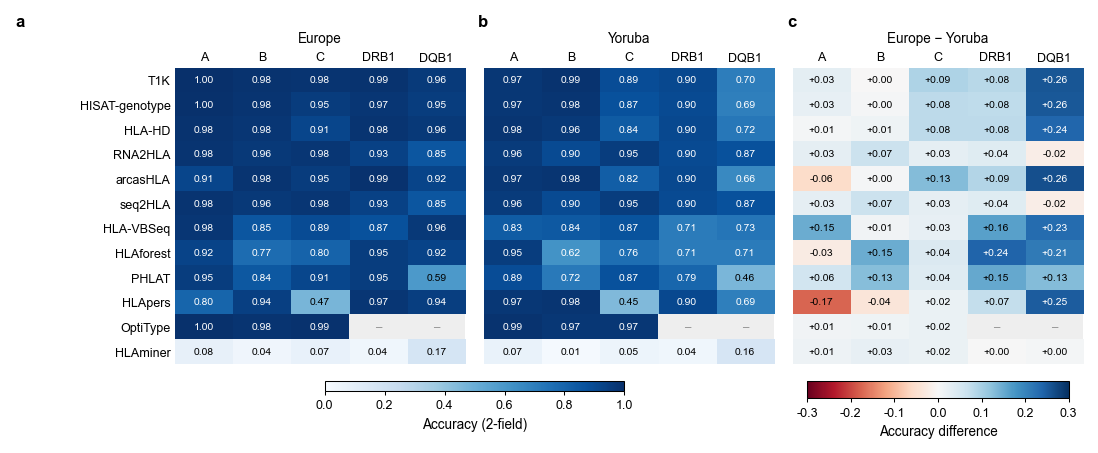

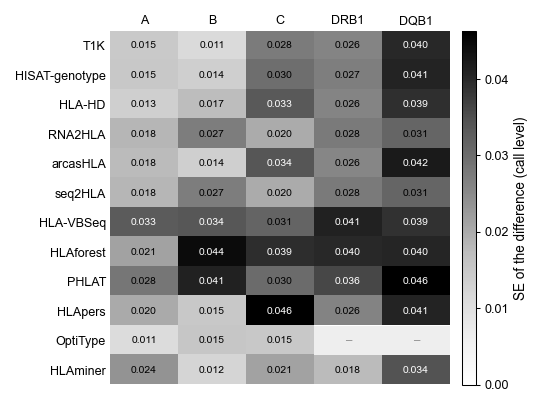

In [52]:
anc_rows = TOOL_ORDER[::-1]
anc_called = (df_locus_all.assign(called=(df_locus_all.CorrectAlleles + df_locus_all.MiscalledAlleles) > 0)
              .groupby(["Tool", "Locus"])["called"].any().unstack("Locus")
              .reindex(index=anc_rows, columns=LOCI_ORDER).fillna(False))
anc_nc = ~anc_called
eur10, yor10 = df_eur_acc.reindex(anc_rows), df_yor_acc.reindex(anc_rows)
diff10 = eur10 - yor10
se10 = df_se.reindex(anc_rows)
DIFF_LIM = float(np.ceil(np.nanmax(np.abs(diff10.mask(anc_nc).values)) * 10) / 10)


def draw_matrix(ax, data, not_called, cmap, vmin, vmax, fmt=".2f", white_if=lambda v: v > 0.6, labels=True):
    shown = data.mask(not_called)
    im = ax.imshow(shown.values.astype(float), cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto")
    for (r, c), v in np.ndenumerate(shown.values.astype(float)):
        if not_called.values[r, c] or np.isnan(v):
            ax.add_patch(plt.Rectangle((c - 0.5, r - 0.5), 1, 1, facecolor="#EEEEEE", edgecolor="none"))
            ax.text(c, r, "\u2013", ha="center", va="center", fontsize=5.5, color="#888888")
        else:
            ax.text(c, r, format(0.0 if abs(v) < 0.005 else v, fmt), ha="center", va="center", fontsize=5,
                    color="white" if white_if(v) else "black")
    ax.set_xticks(range(data.shape[1]), data.columns)
    ax.set_yticks(range(data.shape[0]), tool_labels(data.index))
    if not labels:
        ax.tick_params(axis="y", labelleft=False)
    ax.xaxis.tick_top()
    ax.tick_params(length=0)
    for sp in ax.spines.values():
        sp.set_visible(False)
    return im


def style_cbar(cb, label):
    cb.set_label(label)
    cb.outline.set_linewidth(0.5)
    cb.ax.tick_params(width=0.5, length=2)


fig, axes = plt.subplots(1, 3, figsize=(COL2, 74 * MM), layout="constrained")
im_a = draw_matrix(axes[0], eur10, anc_nc, ACC_CMAP, 0, 1)
draw_matrix(axes[1], yor10, anc_nc, ACC_CMAP, 0, 1, labels=False)
im_c = draw_matrix(axes[2], diff10, anc_nc, "RdBu", -DIFF_LIM, DIFF_LIM, fmt="+.2f",
                   white_if=lambda v: abs(v) > 0.6 * DIFF_LIM, labels=False)
for ax, name in zip(axes, ("Europe", "Yoruba", "Europe \u2212 Yoruba")):
    ax.set_title(name, pad=12)
style_cbar(fig.colorbar(im_a, ax=axes[:2], location="bottom", shrink=0.5, aspect=30), "Accuracy (2-field)")
style_cbar(fig.colorbar(im_c, ax=axes[2], location="bottom", shrink=0.9, aspect=15), "Accuracy difference")
for ax, letter in zip(axes, "abc"):
    ax.text(-0.02 if letter != "a" else -0.55, 1.13, letter, transform=ax.transAxes,
            fontsize=8, fontweight="bold", ha="left", va="bottom")
save_fig(fig, "Figure10")
save_fig(fig, "fig10_ancestry_locus")
plt.show()

fig, (ax, cax) = plt.subplots(1, 2, figsize=(COL1, 66 * MM), width_ratios=[1, 0.04], layout="constrained")
im = draw_matrix(ax, se10, anc_nc, "Greys", 0, float(np.nanmax(se10.values)), fmt=".3f",
                 white_if=lambda v: v > 0.7 * float(np.nanmax(se10.values)))
style_cbar(ax.figure.colorbar(im, cax=cax), "SE of the difference (call level)")
save_fig(fig, "fig10_supp_se_diff")
plt.show()


# Figure 11: Ancestral Misclassification Rate

## Figure 11: misclassification rate chart, setup + plot

### Figure 11: miscalls per sample by locus and ancestry (D1)

Mean share of a sample's two alleles that are miscalled (no-calls excluded), Europe vs Yoruba; each locus is one panel.


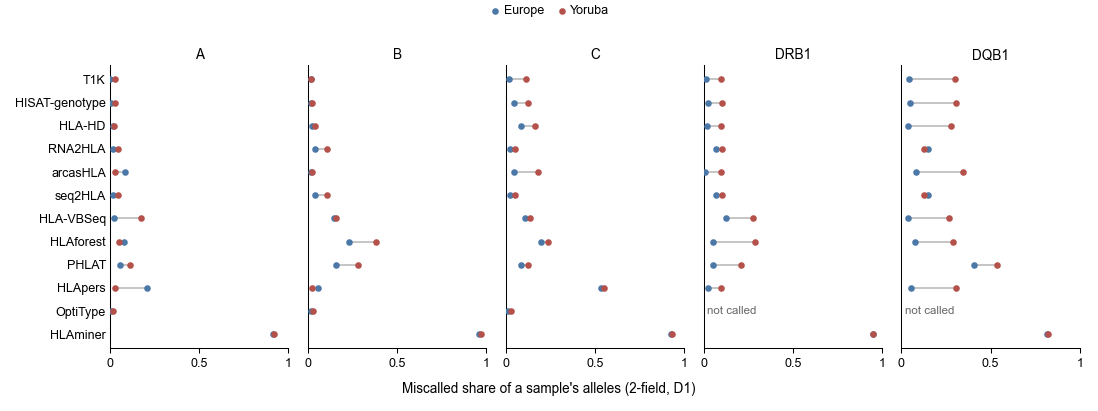

In [53]:
import os
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

def mis_count_for_pair(gs_raw, pr_raw, resolution=2):
    # No "filtered" check -- a wrong call is miscalled regardless
    # of whether it's a real allele seen elsewhere.
    """Same contract as score_pair, but returns just the miscalled count (0-2) for one
    sample x locus -- no-calls are not counted as miscalls (matches the rest of the
    notebook's headline figures)."""
    gs_set = {reformat_allele(a, resolution) for a in gs_raw}
    gs_set.discard(None)
    if not gs_set:
        return None
    if len(pr_raw) == 0:
        pair = [None, None]
    elif len(pr_raw) == 1:
        pair = [pr_raw[0], pr_raw[0]]
    else:
        pair = pr_raw[:2]
    miscalled = 0
    for allele in pair:
        if allele is None:
            continue
        fmt = reformat_allele(allele, resolution)
        if fmt is not None and fmt not in gs_set:
            miscalled += 1
    return miscalled


def compute_per_sample_miscall_counts(
    tools, dataset_num=1,
    run_table="../../data/input/archive/SraRunTableD1.txt",
    euro_pops=("CEU", "FIN", "GBR", "TSI"), yri_pop="YRI",
    gs_dir="../../data/gold_standard", pr_dir="../../data/interim/standard", resolution=2,
) -> pd.DataFrame:
    runs = pd.read_csv(run_table, dtype=str)
    pop_of = dict(zip(runs["Run"], runs["Population"]))

    gs_df = pd.read_csv(os.path.join(gs_dir, f"{dataset_num}_gs.csv"), dtype=str)
    gs_df.iloc[:, 0] = gs_df.iloc[:, 0].str.strip()
    run_col = gs_df.columns[0]
    loci = get_dynamic_loci(gs_df)

    rows = []
    for tool in tools:
        pred_file = os.path.join(pr_dir, f"{tool}_d{dataset_num}.csv")
        if not os.path.exists(pred_file):
            continue
        pr_df = pd.read_csv(pred_file, dtype=str)
        pr_df = pr_df.apply(lambda col: col.str.strip() if col.dtype == "object" else col)
        id_pr = pr_df.columns[0]
        pr_df = pr_df.rename(columns={c: f"{c}_pre" for c in pr_df.columns if c != id_pr})
        merged = pd.merge(gs_df, pr_df, left_on=run_col, right_on=id_pr, how="inner")

        for _, row in merged.iterrows():
            run = row[run_col]
            pop = pop_of.get(run)
            if pop in euro_pops:
                ancestry = "Europe"
            elif pop == yri_pop:
                ancestry = "Yoruba"
            else:
                continue
            for L in loci:
                gs_raw = []
                for suf in ("", ".1"):
                    v = row.get(f"{L}{suf}")
                    if isinstance(v, str) and v:
                        gs_raw += v.split("/")
                if not gs_raw:
                    continue
                pr_raw = []
                for suf in ("_pre", ".1_pre"):
                    v = row.get(f"{L}{suf}")
                    if isinstance(v, str) and v:
                        pr_raw += v.split("/")
                mc = mis_count_for_pair(gs_raw, pr_raw, resolution)
                if mc is None:
                    continue
                rows.append({"Tool": tool, "Ancestry": ancestry, "Locus": L,
                            "Sample": run, "MiscalledAlleles": mc})
    return pd.DataFrame(rows)


TOOLS_F11 = ["arcas", "optitype", "seq2hla", "hlaminer", "phlat", "hlavbseq",
             "hlahd", "hisat", "hlaforest", "hlapers", "T1K", "rna2hla"]
LOCI_F11 = ["A", "B", "C", "DQB1", "DRB1"]

df_f11 = compute_per_sample_miscall_counts(TOOLS_F11)

f11 = (df_f11.groupby(["Tool", "Locus", "Ancestry"])["MiscalledAlleles"].mean().div(2)
       .unstack("Ancestry"))

fig, axes = plt.subplots(1, 5, figsize=(COL2, 66 * MM), sharey=True, layout="constrained")
for k, (ax, L) in enumerate(zip(axes, LOCI_ORDER)):
    d = f11.xs(L, level="Locus")
    nc = set(anc_nc.index[anc_nc[L]])
    draw_ancestry(ax, d["Europe"], d["Yoruba"], {}, labels=(k == 0), not_called=nc)
    ax.set_title(L)
    ax.set_xticks([0, 0.5, 1], ["0", "0.5", "1"])
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc="outside upper center", ncol=2, handletextpad=0.2)
fig.supxlabel("Miscalled share of a sample's alleles (2-field, D1)", fontsize=6.5)
save_fig(fig, "fig11_ancestral_misclassification_rate")
plt.show()


# Supplementary Figure 9: Europe split by source population
Figures 9/10 pool four European populations (CEU/FIN/GBR/TSI) into one "Europe" group compared against Yoruba (YRI). This section scores each population separately, plus CEU alone vs YRI, to check whether pooling changes the result.

In [54]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# -----------------------------------------------------------------------------
# 1) Gold-standard subset per source population (CEU/FIN/GBR/TSI/YRI),
#    D1 only -- the only dataset with per-sample Population metadata.
# -----------------------------------------------------------------------------
runs = pd.read_csv("../../data/input/archive/SraRunTableD1.txt")
gs_d1 = pd.read_csv("../../data/gold_standard/1_gs.csv", dtype=str)

POPS = ["CEU", "FIN", "GBR", "TSI", "YRI"]
pop_counts, pop_gs = {}, {}
for pop in POPS:
    ids = runs.loc[runs.Population == pop, "Run"]
    pop_gs[pop] = gs_d1[gs_d1.Run.isin(ids)]
    pop_counts[pop] = int(gs_d1.Run.isin(ids).sum())

print("D1 samples with gold-standard data, per source population:", pop_counts)

# -----------------------------------------------------------------------------
# 2) Per-tool, per-population bulk accuracy, 1-field and 2-field
# -----------------------------------------------------------------------------
tools = ["arcas", "optitype", "seq2hla", "hlaminer", "phlat",
         "hlavbseq", "hlahd", "hisat", "hlaforest", "hlapers", "T1K", "rna2hla"]

pop_acc = {1: {}, 2: {}}
for res in (1, 2):
    for t in tools:
        pred = f"../../data/interim/standard/{t}_d1.csv"
        if not os.path.exists(pred):
            continue
        row = {}
        for pop in POPS:
            acc, c, tot, nc, mis = calculate_accuracy(pop_gs[pop], pred, resolution=res)
            row[pop] = acc
        pop_acc[res][t] = row

df_pop_1 = pd.DataFrame(pop_acc[1]).T.reindex(columns=POPS)
df_pop_2 = pd.DataFrame(pop_acc[2]).T.reindex(columns=POPS)

print("\n2-field bulk accuracy by source population (D1, per tool):")
print(df_pop_2.round(3).to_string())

# -----------------------------------------------------------------------------
# 3) How far is pooled "Europe" (CEU+FIN+GBR+TSI, Figure 9's own grouping)
#    from CEU alone? Rebuild the pooled number the same way Figure 9 does.
# -----------------------------------------------------------------------------
euro_ids = runs.loc[runs.Population.isin(["CEU", "FIN", "GBR", "TSI"]), "Run"]
gs_pooled_europe = gs_d1[gs_d1.Run.isin(euro_ids)]

compare_rows = []
for t in tools:
    pred = f"../../data/interim/standard/{t}_d1.csv"
    if not os.path.exists(pred):
        continue
    pooled_acc, *_ = calculate_accuracy(gs_pooled_europe, pred, resolution=2)
    ceu_acc = df_pop_2.at[t, "CEU"] if t in df_pop_2.index else np.nan
    yri_acc = df_pop_2.at[t, "YRI"] if t in df_pop_2.index else np.nan
    compare_rows.append({
        "Tool": t,
        "Europe_pooled_4pop": pooled_acc,
        "CEU_only": ceu_acc,
        "Pooled_minus_CEU": pooled_acc - ceu_acc if pd.notna(pooled_acc) and pd.notna(ceu_acc) else np.nan,
        "YRI": yri_acc,
        "CEU_minus_YRI": ceu_acc - yri_acc if pd.notna(ceu_acc) and pd.notna(yri_acc) else np.nan,
        "Europe_minus_YRI": pooled_acc - yri_acc if pd.notna(pooled_acc) and pd.notna(yri_acc) else np.nan,
    })
df_compare = pd.DataFrame(compare_rows).set_index("Tool")
print("\nPooled Europe (CEU+FIN+GBR+TSI) vs CEU-only, 2-field:")
print(df_compare.round(3).to_string())
print(f"\nmean |pooled Europe - CEU-only| = {df_compare['Pooled_minus_CEU'].abs().mean():.4f}")
print(f"max  |pooled Europe - CEU-only| = {df_compare['Pooled_minus_CEU'].abs().max():.4f}")
print(f"mean CEU-YRI gap = {df_compare['CEU_minus_YRI'].mean():.4f} "
      f"(vs mean pooled-Europe-YRI gap = {df_compare['Europe_minus_YRI'].mean():.4f})")


D1 samples with gold-standard data, per source population: {'CEU': 95, 'FIN': 114, 'GBR': 111, 'TSI': 103, 'YRI': 67}



2-field bulk accuracy by source population (D1, per tool):
             CEU    FIN    GBR    TSI    YRI
arcas      0.904  0.972  0.956  0.971  0.866
optitype   0.574  0.600  0.597  0.600  0.585
seq2hla    0.908  0.943  0.945  0.963  0.913
hlaminer   0.093  0.077  0.076  0.078  0.067
phlat      0.837  0.848  0.859  0.848  0.746
hlavbseq   0.873  0.912  0.925  0.931  0.796
hlahd      0.921  0.976  0.981  0.971  0.881
hisat      0.918  0.989  0.987  0.979  0.882
hlaforest  0.849  0.903  0.888  0.845  0.749
hlapers    0.780  0.839  0.830  0.844  0.799
T1K        0.933  0.996  0.997  0.995  0.890
rna2hla    0.908  0.943  0.945  0.963  0.913



Pooled Europe (CEU+FIN+GBR+TSI) vs CEU-only, 2-field:
           Europe_pooled_4pop  CEU_only  Pooled_minus_CEU    YRI  CEU_minus_YRI  Europe_minus_YRI
Tool                                                                                             
arcas                   0.952     0.904             0.048  0.866          0.039             0.087
optitype                0.593     0.574             0.020  0.585         -0.011             0.008
seq2hla                 0.941     0.908             0.032  0.913         -0.005             0.027
hlaminer                0.080     0.093            -0.012  0.067          0.025             0.013
phlat                   0.848     0.837             0.011  0.746          0.091             0.102
hlavbseq                0.911     0.873             0.039  0.796          0.077             0.116
hlahd                   0.964     0.921             0.043  0.881          0.040             0.083
hisat                   0.970     0.918             0.052  0.88

## Supplementary Figure 9: European sub-populations

Accuracy by 1000 Genomes source population (a) and pooled Europe vs CEU only vs YRI (b), 2-field, D1.


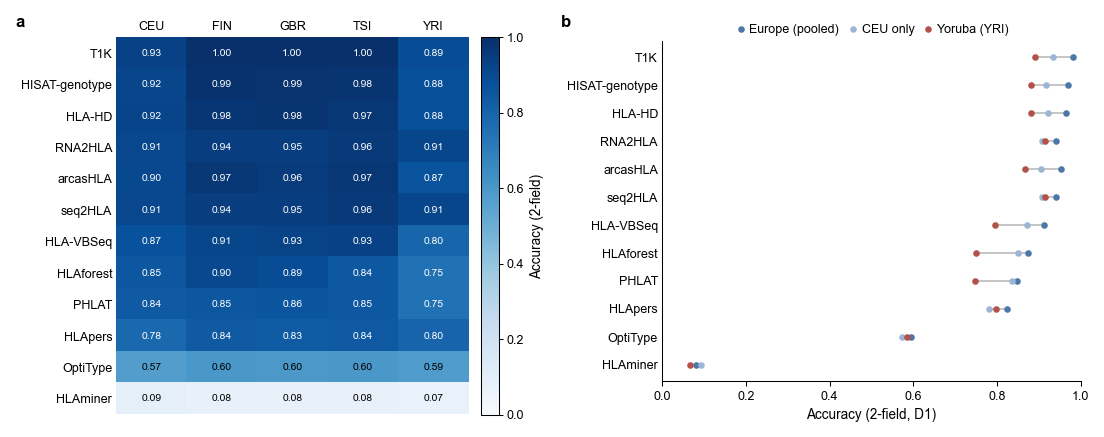

mean CEU-YRI gap = 0.034; mean pooled-Europe-YRI gap = 0.066


In [55]:
pop_rows = TOOL_ORDER[::-1]
pop_mat = df_pop_2.reindex(index=pop_rows, columns=["CEU", "FIN", "GBR", "TSI", "YRI"])
cmp9 = df_compare.reindex(TOOL_ORDER)
POP_SERIES = (("Europe_pooled_4pop", "Europe (pooled)", palette["Europe"]),
              ("CEU_only", "CEU only", "#9DB6D3"),
              ("YRI", "Yoruba (YRI)", palette["Yoruba"]))


def draw_pop_compare(ax):
    for k, t in enumerate(cmp9.index):
        vals = [cmp9.at[t, c] for c, _, _ in POP_SERIES]
        ax.plot([np.nanmin(vals), np.nanmax(vals)], [k, k], color="#BBBBBB", lw=0.8, zorder=1)
        for (c, lab, col), v in zip(POP_SERIES, vals):
            ax.scatter([v], [k], s=10, color=col, linewidths=0, zorder=3, label=lab if k == 0 else None)
    ax.set_yticks(range(len(cmp9)), tool_labels(cmp9.index))
    ax.tick_params(axis="y", length=0)
    ax.set_ylim(-0.6, len(cmp9) - 0.4)
    ax.set_xlim(0, 1)
    ax.set_xlabel("Accuracy (2-field, D1)")
    ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=3, handletextpad=0.2, columnspacing=0.6)


fig = plt.figure(figsize=(COL2, 70 * MM), layout="constrained")
sf_a, sf_b = fig.subfigures(1, 2, width_ratios=[1, 1])
ax_a, cax = sf_a.subplots(1, 2, width_ratios=[1, 0.05])
im = draw_matrix(ax_a, pop_mat, pop_mat.isna(), ACC_CMAP, 0, 1)
style_cbar(sf_a.colorbar(im, cax=cax), "Accuracy (2-field)")
draw_pop_compare(sf_b.subplots())
label_panel(sf_a, "a")
label_panel(sf_b, "b")
save_fig(fig, "fig9_supp_populations")
plt.show()
print(f"mean CEU-YRI gap = {df_compare['CEU_minus_YRI'].mean():.3f}; "
      f"mean pooled-Europe-YRI gap = {df_compare['Europe_minus_YRI'].mean():.3f}")


# Figure 12: Memory and CPU

In [57]:
def parse_segmented_csv(path):
    """
    Reads a CSV where each sample is a segment:
      - Header row: sample ID + tool names
      - Following rows: iteration number, values for each tool
      - 'avg' row per segment (dropped) and blank rows (dropped)
    Returns a long-form DataFrame: sample, iteration, tool, value.
    """
    df = pd.read_csv(path, header=None, dtype=str, keep_default_na=False)
    # Drop fully blank rows
    df = df[~df.apply(lambda row: all(cell.strip()=='' for cell in row), axis=1)]
    # Identify header rows: first col not a digit and not 'avg'
    header_mask = ~df[0].str.isdigit() & (df[0].str.lower() != 'avg')
    header_idxs = df.index[header_mask].tolist()
    
    records = []
    for idx_i, hdr in enumerate(header_idxs):
        row = df.loc[hdr].tolist()
        sample = row[0].strip()
        tools = [t.strip() for t in row[1:]]
        start = hdr + 1
        end = header_idxs[idx_i+1] if idx_i+1 < len(header_idxs) else df.index.max() + 1
        segment = df.loc[start:end-1]
        # Drop 'avg' rows
        segment = segment[segment[0].str.lower() != 'avg']
        for _, segrow in segment.iterrows():
            iteration = segrow[0].strip()
            for c, tool in enumerate(tools, start=1):
                val = segrow[c].strip()
                records.append({
                    'sample': sample,
                    'iteration': iteration,
                    'tool': tool,
                    'value': val
                })
    return pd.DataFrame(records)

# Parse CPU and RAM
cpu_long = parse_segmented_csv('../../data/interim/cpu_ram/runtime_data - ALL CPU DATA.csv')
ram_long = parse_segmented_csv('../../data/interim/cpu_ram/runtime_data - ALL_RAM_DATA.csv')

# Safe CPU conversion with logging
bad_cpu = []
def safe_hms_to_seconds(t):
    try:
        h, m, s = t.split(':')
        return int(h)*3600 + int(m)*60 + float(s)
    except Exception:
        bad_cpu.append(t)
        return np.nan

cpu_long['cpu_seconds'] = cpu_long['value'].apply(safe_hms_to_seconds)

print("Malformed CPU time strings:", set(bad_cpu))
print("Rows with parsing failures:")
print(cpu_long[cpu_long['cpu_seconds'].isna()])

# Drop failures
cpu_long = cpu_long.dropna(subset=['cpu_seconds'])

# Safe RAM conversion with logging
bad_ram = []
def safe_mem_to_gb(x):
    try:
        m = re.match(r'([\d\.]+)\s*([MG]B)', x.strip(), re.I)
        v, unit = m.groups()
        v = float(v)
        return v if unit.upper()=='GB' else v/1024
    except Exception:
        bad_ram.append(x)
        return np.nan

ram_long['ram_gb'] = ram_long['value'].apply(safe_mem_to_gb)

print("Malformed RAM strings:", set(bad_ram))
print("Rows with parsing failures:")
print(ram_long[ram_long['ram_gb'].isna()])

# Drop failures
ram_long = ram_long.dropna(subset=['ram_gb'])



cpu_long
ram_long



Malformed CPU time strings: set()
Rows with parsing failures:
Empty DataFrame
Columns: [sample, iteration, tool, value, cpu_seconds]
Index: []
Malformed RAM strings: set()
Rows with parsing failures:
Empty DataFrame
Columns: [sample, iteration, tool, value, ram_gb]
Index: []


,sample,iteration,tool,value,ram_gb
0,ERR009159,1,seq2HLA,73.48 MB,0.071758
1,ERR009159,1,rna2hla,96.89 MB,0.094619
2,ERR009159,1,arcasHLA,2.39 GB,2.390000
3,ERR009159,1,HLAforest,4.60 GB,4.600000
4,ERR009159,1,Optitype,13.47 GB,13.470000
...,...,...,...,...,...
1435,GSM3768245,10,HLA-HD,1.45 GB,1.450000
1436,GSM3768245,10,HLAvbseq,1.85 GB,1.850000
1437,GSM3768245,10,T1K,1.88 GB,1.880000
1438,GSM3768245,10,HISAT-genotype,7.37 GB,7.370000


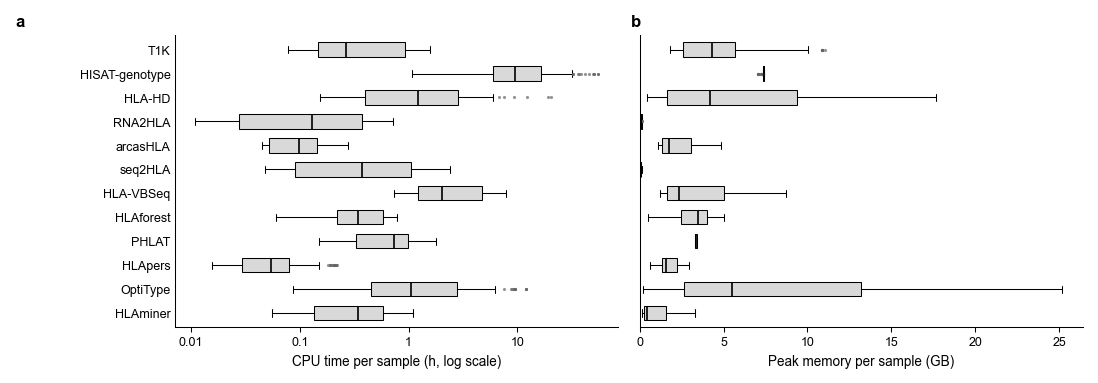

In [58]:
RES_KEY = {"arcasHLA": "arcas", "Optitype": "optitype", "seq2HLA": "seq2hla", "HLAMiner": "hlaminer",
           "PHLAT": "phlat", "HLAvbseq": "hlavbseq", "HLA-HD": "hlahd", "HISAT-genotype": "hisat",
           "T1K": "T1K", "rna2hla": "rna2hla", "HLApers": "hlapers", "HLAforest": "hlaforest"}
cpu_long["key"] = cpu_long["tool"].map(RES_KEY)
ram_long["key"] = ram_long["tool"].map(RES_KEY)
assert cpu_long["key"].notna().all() and ram_long["key"].notna().all()
cpu_long["cpu_hours"] = cpu_long["cpu_seconds"] / 3600
BOX_KW = dict(vert=False, widths=0.6, patch_artist=True, showfliers=True,
              boxprops=dict(facecolor="#D9D9D9", edgecolor="black", linewidth=0.5),
              medianprops=dict(color="black", linewidth=0.8),
              whiskerprops=dict(linewidth=0.5), capprops=dict(linewidth=0.5),
              flierprops=dict(marker="o", markersize=1.5, markerfacecolor="#666666",
                              markeredgewidth=0, alpha=0.7))


def draw_resource(ax, frame, col, xlabel, log=False, labels=True):
    order = [t for t in TOOL_ORDER if t in set(frame["key"])]
    ax.boxplot([frame.loc[frame["key"] == t, col].values for t in order], positions=range(len(order)), **BOX_KW)
    ax.set_yticks(range(len(order)), tool_labels(order))
    if not labels:
        ax.tick_params(axis="y", labelleft=False)
    ax.tick_params(axis="y", length=0)
    ax.set_ylim(-0.6, len(order) - 0.4)
    if log:
        ax.set_xscale("log")
        ax.set_xticks([0.01, 0.1, 1, 10], ["0.01", "0.1", "1", "10"])
        ax.xaxis.set_minor_locator(matplotlib.ticker.NullLocator())
    ax.set_xlabel(xlabel)


fig, (ax_c, ax_r) = plt.subplots(1, 2, figsize=(COL2, 62 * MM), sharey=True, layout="constrained")
draw_resource(ax_c, cpu_long, "cpu_hours", "CPU time per sample (h, log scale)", log=True)
draw_resource(ax_r, ram_long, "ram_gb", "Peak memory per sample (GB)", labels=False)
ax_r.set_xlim(0, None)
for ax, letter in zip((ax_c, ax_r), "ab"):
    ax.text(-0.02 if letter == "b" else -0.36, 1.02, letter, transform=ax.transAxes,
            fontsize=8, fontweight="bold", ha="left", va="bottom")
save_fig(fig, "Figure12")
save_fig(fig, "fig12_cpu_ram")
plt.show()


Figure 12 shows CPU time and peak memory together (above); per-sample values from `data/interim/cpu_ram/`.


# Supplementary: per-dataset results, D1-D8

The pooled Figures 3, 5 and 6 recomputed on each dataset alone, as 2 x 4 small multiples. Tools with nothing scorable on a dataset are omitted; * marks predictions for only part of the samples.


In [60]:
# ── Per-dataset engine (self-contained; pd_ prefix = immune to the redefinitions above) ──
import os
import numpy as np
import pandas as pd

PD_TOOLS    = ["arcas", "optitype", "seq2hla", "hlaminer", "phlat", "hlavbseq",
               "hlahd", "hisat", "hlaforest", "hlapers", "T1K", "rna2hla"]
PD_DATASETS = list(range(1, 9))
PD_LOCI     = ["A", "B", "C", "DRB1", "DQB1"]
PD_CLASS_I, PD_CLASS_II = ["A", "B", "C"], ["DRB1", "DQB1"]
PD_GS_DIR, PD_PR_DIR = "../../data/gold_standard", "../../data/interim/standard"
PD_OUT_FIG, PD_OUT_RES = "../../figures/per_dataset", "../../data/final"
os.makedirs(PD_OUT_FIG, exist_ok=True)


def pd_reformat(allele, resolution=2):
    # Keep only the first comma-separated entry (some tools list several tied variants).
    allele = allele.split(",")[0]
    """Verbatim contract of the "Helper Functions" section's reformat_allele."""
    a = allele.strip()
    if "*" not in a:
        return a
    gene, rest = a.split("*", 1)
    parts = rest.split(":")
    if resolution == 1:
        return f"{gene}*{parts[0]}"
    if len(parts) < 2:
        return f"{gene}*{parts[0]}"
    if parts[1].lower() == "xx":
        return None
    return f"{gene}*{parts[0]}:{parts[1]}"


def pd_gs_loci(gs_df):
    return sorted({c.split(".")[0] for c in gs_df.columns[1:]})


def pd_valid(gs_df, resolution):
    loci = pd_gs_loci(gs_df)
    valid = {L: set() for L in loci}
    for _, row in gs_df.iterrows():
        for L in loci:
            for suf in ("", ".1"):
                col = f"{L}{suf}"
                if col in row and pd.notna(row[col]):
                    for a in str(row[col]).split("/"):
                        fa = pd_reformat(a, resolution)
                        if fa is not None:
                            valid[L].add(fa)
    return valid


def pd_score_pair(gs_raw, pr_raw, resolution):
    # 3-outcome contract, matching score_pair() above. Some tools use a literal
    # no-call token ("NA"/"na"/"no") instead of blank; converted to None in place.
    pr_raw = [None if isinstance(a, str) and a.strip().lower() in ("na", "no") else a
              for a in pr_raw]
    gs_set = {pd_reformat(a, resolution) for a in gs_raw}
    gs_set.discard(None)
    if not gs_set:
        return None                     # ':xx'-only slot: unscorable, not in denominator
    pair = [None, None] if len(pr_raw) == 0 else ([pr_raw[0]] * 2 if len(pr_raw) == 1 else pr_raw[:2])
    correct = miscalled = no_call = 0
    for allele in pair:
        if allele is None:
            no_call += 1
        else:
            fmt = pd_reformat(allele, resolution)
            if fmt is not None and fmt in gs_set:
                correct += 1
            else:
                miscalled += 1
    return correct, miscalled, no_call


def pd_counts(tool, ds, resolution):
    """{locus: dict(correct, miscalled, no_call, total)} for ONE tool on ONE
    dataset. Mirrors aggregate_counts_per_tool_locus (the "Helper Functions" section),
    including its penalty: a classical locus the gold standard covers but the tool's
    file has no column for is charged as 2 no-calls per sample. Returns (counts, n_samples)
    or (None, 0) when the tool has no prediction file for this dataset."""
    gs_path, pr_path = f"{PD_GS_DIR}/{ds}_gs.csv", f"{PD_PR_DIR}/{tool}_d{ds}.csv"
    if not (os.path.exists(gs_path) and os.path.exists(pr_path)):
        return None, 0
    gs_df = pd.read_csv(gs_path, dtype=str)
    pr_df = pd.read_csv(pr_path, dtype=str)
    gs_df.iloc[:, 0] = gs_df.iloc[:, 0].str.strip()
    pr_df.iloc[:, 0] = pr_df.iloc[:, 0].str.strip()
    pr_df = pr_df.rename(columns={c: f"{c}_pre" for c in pr_df.columns if c != pr_df.columns[0]})
    supported = {L for L in PD_LOCI if f"{L}_pre" in pr_df.columns or f"{L}.1_pre" in pr_df.columns}
    gs_loci = pd_gs_loci(gs_df)
    valid = pd_valid(gs_df, resolution)
    merged = pd.merge(gs_df, pr_df, left_on=gs_df.columns[0], right_on=pr_df.columns[0], how="inner")
    out = {L: dict(correct=0, miscalled=0, no_call=0, total=0) for L in PD_LOCI}
    for _, row in merged.iterrows():
        for L in PD_LOCI:
            if L in gs_loci and L not in supported:
                out[L]["total"] += 2
                out[L]["no_call"] += 2
        for L in sorted(supported):
            if L not in gs_loci:
                continue
            gs_raw, pr_raw = [], []
            for suf in ("", ".1"):
                col = f"{L}{suf}"
                if col in row and pd.notna(row[col]):
                    gs_raw += [x.strip() for x in str(row[col]).split("/")]
            for suf in ("_pre", ".1_pre"):
                col = f"{L}{suf}"
                if col in row and pd.notna(row[col]):
                    pr_raw += [x.strip() for x in str(row[col]).split("/")]
            if not gs_raw:
                continue
            res = pd_score_pair(gs_raw, pr_raw, resolution)
            if res is None:
                continue
            c, m, nc = res
            out[L]["total"] += 2
            out[L]["correct"] += c
            out[L]["miscalled"] += m
            out[L]["no_call"] += nc
    return out, len(merged)


# ---- tidy table: one row per (dataset, resolution, tool, locus) ----
_rows, PD_N_SAMPLES = [], {}
for _ds in PD_DATASETS:
    _gs = pd.read_csv(f"{PD_GS_DIR}/{_ds}_gs.csv", dtype=str)
    PD_N_SAMPLES[_ds] = int(_gs.iloc[:, 1:].notna().any(axis=1).sum())   # rows with real genotypes
    for _res in (1, 2):
        for _t in PD_TOOLS:
            _c, _n = pd_counts(_t, _ds, _res)
            for _L in PD_LOCI:
                _v = _c[_L] if _c is not None else dict(correct=0, miscalled=0, no_call=0, total=0)
                _rows.append(dict(Dataset=_ds, Resolution=_res, Tool=_t, Locus=_L,
                                  FilePresent=_c is not None, NMatched=_n, **_v))
df_pd = pd.DataFrame(_rows)
df_pd["Class"] = np.where(df_pd["Locus"].isin(PD_CLASS_I), "I", "II")
df_pd.to_csv(f"{PD_OUT_RES}/per_dataset_counts_by_tool_locus.csv", index=False)
print(f"df_pd: {len(df_pd):,} rows | samples per dataset with real genotypes: {PD_N_SAMPLES}")

# ---- reconciliation: per-dataset counts summed over D1-D6 must equal the pooled numbers ----
# (the pooled df_1/df_2 come from the Fig 3-4 cells via compute_all_metrics (the "Helper
#  Functions" section); both are already 3-outcome, so this is a direct sum match.)
_chk = 0
for _res, _pooled in ((1, df_1), (2, df_2)):
    _sub = df_pd[(df_pd.Resolution == _res) & (df_pd.Dataset.between(1, 6))]
    _agg = _sub.groupby("Tool")[["correct", "miscalled", "no_call", "total"]].sum()
    for _, _r in _pooled.iterrows():
        _a = _agg.loc[_r["Tool"]]
        assert int(_a["correct"]) == int(_r["TotalCorrect"]), (_res, _r["Tool"], "correct")
        assert int(_a["miscalled"]) == int(_r["TotalMiscalled"]), (_res, _r["Tool"], "miscalled")
        assert int(_a["no_call"]) == int(_r["TotalNoCall"]), (_res, _r["Tool"], "no_call")
        assert int(_a["total"]) == int(_r["TotalCalls"]), (_res, _r["Tool"], "total")
        _chk += 1
print(f"RECONCILED: per-dataset counts summed over D1-D6 == pooled Figure 3-6 counts "
      f"({_chk} tool x resolution checks, exact on correct/miscalled/no-call/total).")


df_pd: 960 rows | samples per dataset with real genotypes: {1: 490, 2: 86, 3: 50, 4: 14, 5: 8, 6: 4, 7: 20, 8: 3}
RECONCILED: per-dataset counts summed over D1-D6 == pooled Figure 3-6 counts (24 tool x resolution checks, exact on correct/miscalled/no-call/total).


In [61]:
# ── status / label helpers + data builders for the per-dataset figures ──
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.colors as mcolors

PD_MARK = {"scored": "", "partial": "*", "unusable": "†", "not run": ""}
PD_MIN_TOTAL = 6            # same floor as the Fig 7 supplementary per-dataset panels
PD_FIG_DPI = 200


def pd_status(ds, t):
    """not run = no prediction file | unusable = file present but no sample ID matches the gold
    standard | partial = predictions cover fewer samples than the dataset has | scored = full."""
    r = df_pd[(df_pd.Dataset == ds) & (df_pd.Tool == t) & (df_pd.Resolution == 2)].iloc[0]
    if not r.FilePresent:
        return "not run"
    if r.NMatched == 0:
        return "unusable"
    return "partial" if r.NMatched < PD_N_SAMPLES[ds] else "scored"


def pd_matched(ds, t):
    return int(df_pd[(df_pd.Dataset == ds) & (df_pd.Tool == t) & (df_pd.Resolution == 2)].iloc[0].NMatched)


def pd_tools_run(ds):
    """tools contributing scorable calls on this dataset (scored + partial)."""
    return [t for t in PD_TOOLS if pd_status(ds, t) in ("scored", "partial")]


def pd_lbl(ds, t):
    return t + PD_MARK[pd_status(ds, t)]


def pd_tag(ds):
    return f"D{ds} (n={PD_N_SAMPLES[ds]}; {len(pd_tools_run(ds))}/12 tools)"


def pd_note(ds, extra=None):
    parts = []
    omitted = [f"{t} ({'unusable file' if pd_status(ds, t) == 'unusable' else 'no predictions'})"
               for t in PD_TOOLS if pd_status(ds, t) in ("not run", "unusable")]
    if omitted:
        parts.append("Not shown (nothing scorable): " + ", ".join(omitted))
    part = [f"{t} {pd_matched(ds, t)}/{PD_N_SAMPLES[ds]}" for t in PD_TOOLS if pd_status(ds, t) == "partial"]
    if part:
        parts.append("* predictions cover only part of the samples: " + ", ".join(part))
    if extra:
        parts.append(extra)
    return "\n".join(parts)


def pd_footnote(fig, text, y=-0.012):
    """footnote BELOW the figure (outside the axes area; savefig(bbox_inches='tight') keeps it)."""
    if text:
        fig.text(0.01, y, text, fontsize=10, ha="left", va="top", color="#333333")


def pd_save(fig, ds, name):
    os.makedirs(f"{PD_OUT_FIG}/D{ds}", exist_ok=True)
    base = f"{PD_OUT_FIG}/D{ds}/{name}_D{ds}"
    fig.savefig(base + ".png", dpi=PD_FIG_DPI, bbox_inches="tight")
    fig.savefig(base + ".svg", bbox_inches="tight")
    plt.close(fig)
    return base


# ---- data builders (same quantities the pooled figures use, restricted to one dataset) ----
def pd_locus_stats(ds):
    """df_locus_stats analogue (2-field): Tool | Locus | CorrectAlleles |
    MiscalledAlleles | NoCallAlleles | TotalAlleles | Accuracy (= correct / all calls)."""
    ok = pd_tools_run(ds)
    d = df_pd[(df_pd.Dataset == ds) & (df_pd.Resolution == 2) & df_pd.Tool.isin(ok) & (df_pd.total > 0)].copy()
    d = d.rename(columns={"correct": "CorrectAlleles", "miscalled": "MiscalledAlleles",
                          "no_call": "NoCallAlleles", "total": "TotalAlleles"})
    d["Accuracy"] = d["CorrectAlleles"] / d["TotalAlleles"]
    d["Tool"] = [pd_lbl(ds, t) for t in d["Tool"]]
    return d.sort_values(["Tool", "Locus"]).reset_index(drop=True)


def pd_class_acc(ds, resolution):
    """Tool x [ClassI_acc, ClassII_acc, Overall]; NaN = no scorable calls in that class (never 0%)."""
    sub = df_pd[(df_pd.Dataset == ds) & (df_pd.Resolution == resolution) & df_pd.Tool.isin(pd_tools_run(ds))]
    rows = {}
    for t, g in sub.groupby("Tool"):
        def acc(h):
            den = h.total.sum()
            return h.correct.sum() / den if den > 0 else np.nan
        rows[t] = {"ClassI_acc": acc(g[g.Locus.isin(PD_CLASS_I)]),
                   "ClassII_acc": acc(g[g.Locus.isin(PD_CLASS_II)]),
                   "Overall": acc(g)}
    return pd.DataFrame(rows).T


def pd_allele_tally(ds):
    """Per-allele misclassification tally for one dataset -- same logic as the Fig 7 per-dataset
    aggregator (2-field; a gold-standard allele is 'missed' when no prediction hits the sample's
    gold set)."""
    tally = {}
    for tool in pd_tools_run(ds):
        gs_df = pd.read_csv(f"{PD_GS_DIR}/{ds}_gs.csv", dtype=str)
        pr_df = pd.read_csv(f"{PD_PR_DIR}/{tool}_d{ds}.csv", dtype=str)
        gs_df.iloc[:, 0] = gs_df.iloc[:, 0].str.strip()
        pr_df.iloc[:, 0] = pr_df.iloc[:, 0].str.strip()
        pr_df = pr_df.rename(columns={c: f"{c}_pre" for c in pr_df.columns if c != pr_df.columns[0]})
        loci = pd_gs_loci(gs_df)
        merged = pd.merge(gs_df, pr_df, left_on=gs_df.columns[0], right_on=pr_df.columns[0], how="inner")
        for _, row in merged.iterrows():
            for L in loci:
                gs_raw, pr_raw = [], []
                for suf in ("", ".1"):
                    col = f"{L}{suf}"
                    if col in row and pd.notna(row[col]):
                        gs_raw += [x.strip() for x in str(row[col]).split("/")]
                if not gs_raw:
                    continue
                gs_set = {pd_reformat(a, 2) for a in gs_raw}
                gs_set.discard(None)
                if not gs_set:
                    continue
                for suf in ("_pre", ".1_pre"):
                    col = f"{L}{suf}"
                    if col in row and pd.notna(row[col]):
                        pr_raw += [x.strip() for x in str(row[col]).split("/")]
                pred = [] if len(pr_raw) == 0 else (pr_raw * 2 if len(pr_raw) == 1 else pr_raw[:2])
                # No "drop predictions outside the valid set" step -- such a prediction
                # can never be in gs_set either, so it scores as a miss either way.
                pred_fmt = [a for a in (pd_reformat(x, 2) for x in pred) if a is not None]
                hit = bool(set(pred_fmt) & gs_set)
                # Same no-call/miscall split as this aggregator's other copies.
                is_no_call = len(pr_raw) == 0 or all(
                    isinstance(a, str) and a.strip().lower() in ("na", "no") for a in pr_raw
                )  # some tools use a literal no-call token ("NA"/"na"/"no") instead of blank
                for allele in gs_set:
                    c = tally.setdefault((L, allele), {"Total": 0, "Mis": 0, "NoCall": 0})
                    c["Total"] += 1
                    if not hit:
                        if is_no_call:
                            c["NoCall"] += 1
                        else:
                            c["Mis"] += 1
    df = pd.DataFrame([{"Locus": L, "Allele": a, **c} for (L, a), c in tally.items()])
    if len(df):
        df["MisclassificationRate%"] = 100.0 * df["Mis"] / df["Total"]
        df["NoCallRate%"] = 100.0 * df["NoCall"] / df["Total"]
    return df


# ---- validation: this section's allele tally must equal the Fig 7 supplementary per-dataset tally ----
if "per_ds" in globals():
    _ok = 0
    for _ds in PD_DATASETS:
        _mine = pd_allele_tally(_ds).set_index(["Locus", "Allele"])[["Total", "Mis"]].sort_index()
        _ref = (per_ds[per_ds.Dataset == _ds].set_index(["Locus", "Allele"])[["Total", "Mis"]]
                .astype(int).sort_index())
        assert _mine.equals(_ref), f"allele tally mismatch on D{_ds}"
        _ok += 1
    print(f"RECONCILED: per-dataset allele tally == Fig 7 supplementary tally (per_ds) on all {_ok} datasets.")
else:
    print("SKIPPED allele-tally reconciliation: per_ds (Fig 7 supplementary cell) is not in this kernel.")


RECONCILED: per-dataset allele tally == Fig 7 supplementary tally (per_ds) on all 8 datasets.


In [62]:
def pd_label(ds, t):
    return TOOL_NAME[t] + PD_MARK[pd_status(ds, t)]


def pd_grid(height_mm):
    return plt.subplots(2, 4, figsize=(COL2, height_mm * MM), layout="constrained")


def pd_title(ax, ds):
    ax.set_title(pd_tag(ds), fontsize=5.5, pad=1.5)


def pd_locus_frame(ds, col):
    d = pd_locus_stats(ds)
    d["Key"] = d["Tool"].str.rstrip("*\u2020")
    m = d.pivot(index="Key", columns="Locus", values=col)
    order = [t for t in TOOL_ORDER if t in m.index]
    return d, m.reindex(index=order, columns=[L for L in LOCI_ORDER if L in m.columns])


def pd_called(ds):
    d = pd_locus_stats(ds)
    d["Key"] = d["Tool"].str.rstrip("*\u2020")
    return (d.groupby("Key")[["CorrectAlleles", "MiscalledAlleles"]].sum().sum(axis=1) > 0).to_dict()


PD_ROWS = 12


def pd_empty_reason(ds, t):
    has_class_I = any(L in PD_CLASS_I for L in pd_gs_loci(pd.read_csv(f"{PD_GS_DIR}/{ds}_gs.csv", dtype=str)))
    return "Class I only, no Class I gold standard" if (t in CLASS_I_ONLY and not has_class_I) else "no calls"


def pd_rows(ax, n):
    ax.set_ylim(n - PD_ROWS - 0.4, n - 0.4)


def pd_draw_bulk(ax, ds):
    a1, a2 = pd_class_acc(ds, 1)["Overall"], pd_class_acc(ds, 2)["Overall"]
    order = [t for t in TOOL_ORDER if t in a2.index and pd.notna(a2.get(t))]
    y, h = np.arange(len(order)), 0.4
    ax.barh(y + h / 2, a1.reindex(order).fillna(0).values, height=h, color=palette["1st field"], label="1-field")
    ax.barh(y - h / 2, a2.reindex(order).fillna(0).values, height=h, color=palette["2nd field"], label="2-field")
    called = pd_called(ds)
    for yi, t in zip(y, order):
        if not called.get(t, False):
            ax.text(0.02, yi, pd_empty_reason(ds, t), va="center", ha="left", fontsize=4.5, color="#666666")
    ax.set_yticks(y, [pd_label(ds, t) for t in order], fontsize=5)
    ax.tick_params(axis="y", length=0)
    pd_rows(ax, len(order))
    ax.set_xlim(0, 1)
    ax.set_xticks([0, 0.5, 1], ["0", "0.5", "1"])
    pd_title(ax, ds)


def pd_draw_locus(ax, ds):
    d, acc = pd_locus_frame(ds, "Accuracy")
    _, nc_ = pd_locus_frame(ds, "NoCallAlleles")
    _, tot = pd_locus_frame(ds, "TotalAlleles")
    acc, not_called = acc.iloc[::-1], (nc_ == tot).iloc[::-1]
    im = ax.imshow(acc.mask(not_called).values.astype(float), cmap=ACC_CMAP, vmin=0, vmax=1, aspect="auto")
    for (r, c), v in np.ndenumerate(acc.values.astype(float)):
        if not_called.values[r, c]:
            ax.add_patch(plt.Rectangle((c - 0.5, r - 0.5), 1, 1, facecolor="#EEEEEE", edgecolor="none"))
        elif not np.isnan(v):
            ax.text(c, r, f"{v:.2f}", ha="center", va="center", fontsize=4.2, color="white" if v > 0.6 else "black")
    ax.set_xticks(range(acc.shape[1]), acc.columns, fontsize=5)
    ax.set_yticks(range(acc.shape[0]), [pd_label(ds, t) for t in acc.index], fontsize=5)
    ax.xaxis.tick_top()
    ax.tick_params(length=0)
    for sp in ax.spines.values():
        sp.set_visible(False)
    ax.set_xlabel(pd_tag(ds), fontsize=5.5, labelpad=2)
    return im


def pd_draw_miscall_share(ax, ds):
    _, mis = pd_locus_frame(ds, "MiscalledAlleles")
    mis = mis.fillna(0)
    share = mis.div(mis.sum(axis=1).where(mis.sum(axis=1) > 0), axis=0)
    y, left = np.arange(len(share)), np.zeros(len(share))
    for L in share.columns:
        v = share[L].fillna(0).values
        ax.barh(y, v, left=left, height=0.7, color=palette[L])
        left += v
    called = pd_called(ds)
    for yi, t, tot_mis in zip(y, share.index, mis.sum(axis=1).values):
        if tot_mis == 0:
            ax.text(0.02, yi, "no miscalls" if called.get(t, False) else pd_empty_reason(ds, t),
                    va="center", ha="left", fontsize=4.5, color="#666666")
    ax.set_yticks(y, [pd_label(ds, t) for t in share.index], fontsize=5)
    ax.tick_params(axis="y", length=0)
    pd_rows(ax, len(share))
    ax.set_xlim(0, 1)
    ax.set_xticks([0, 0.5, 1], ["0", "0.5", "1"])
    pd_title(ax, ds)


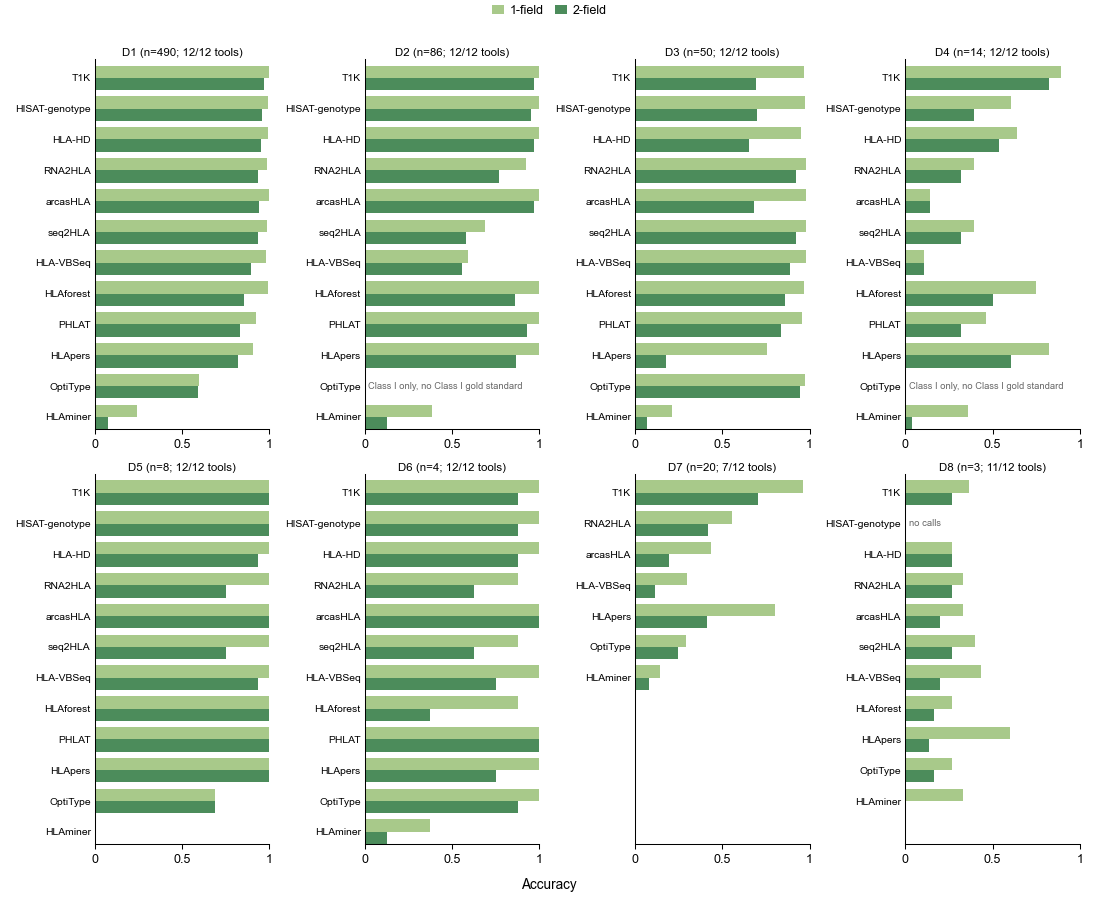

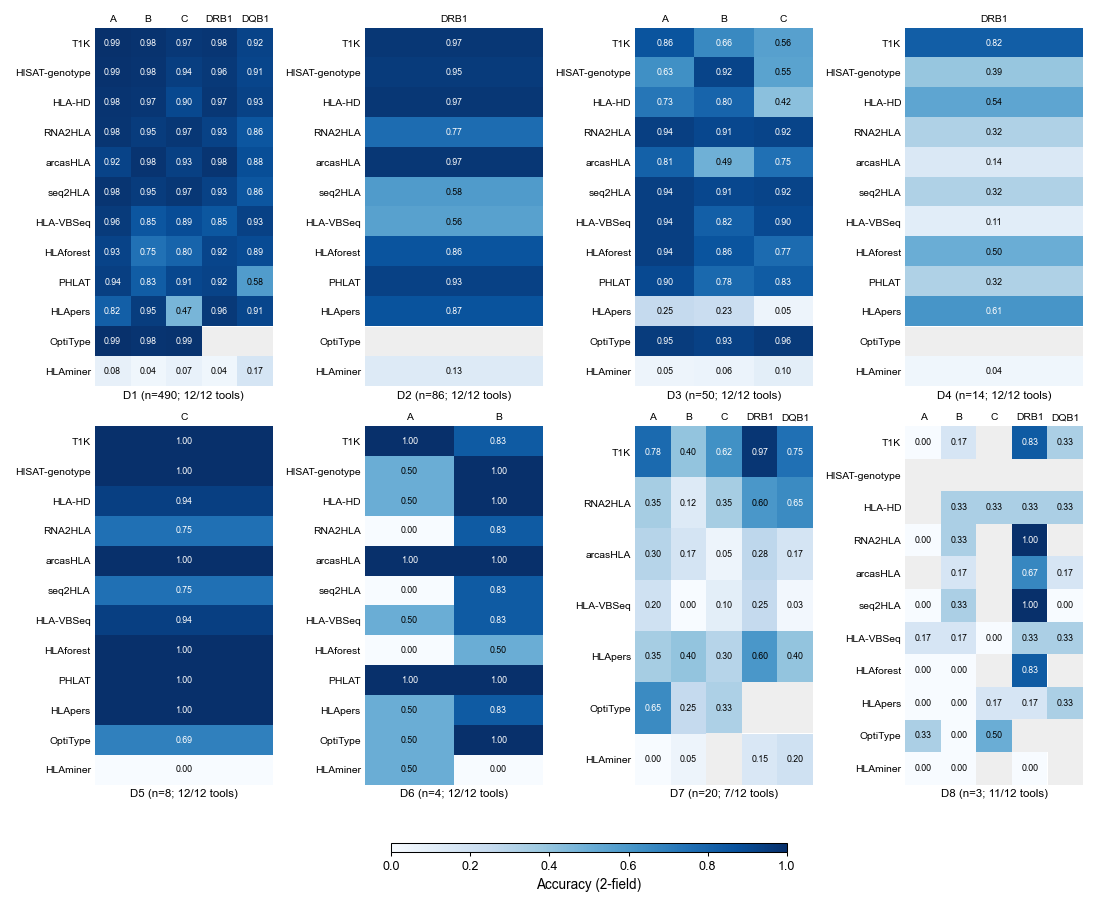

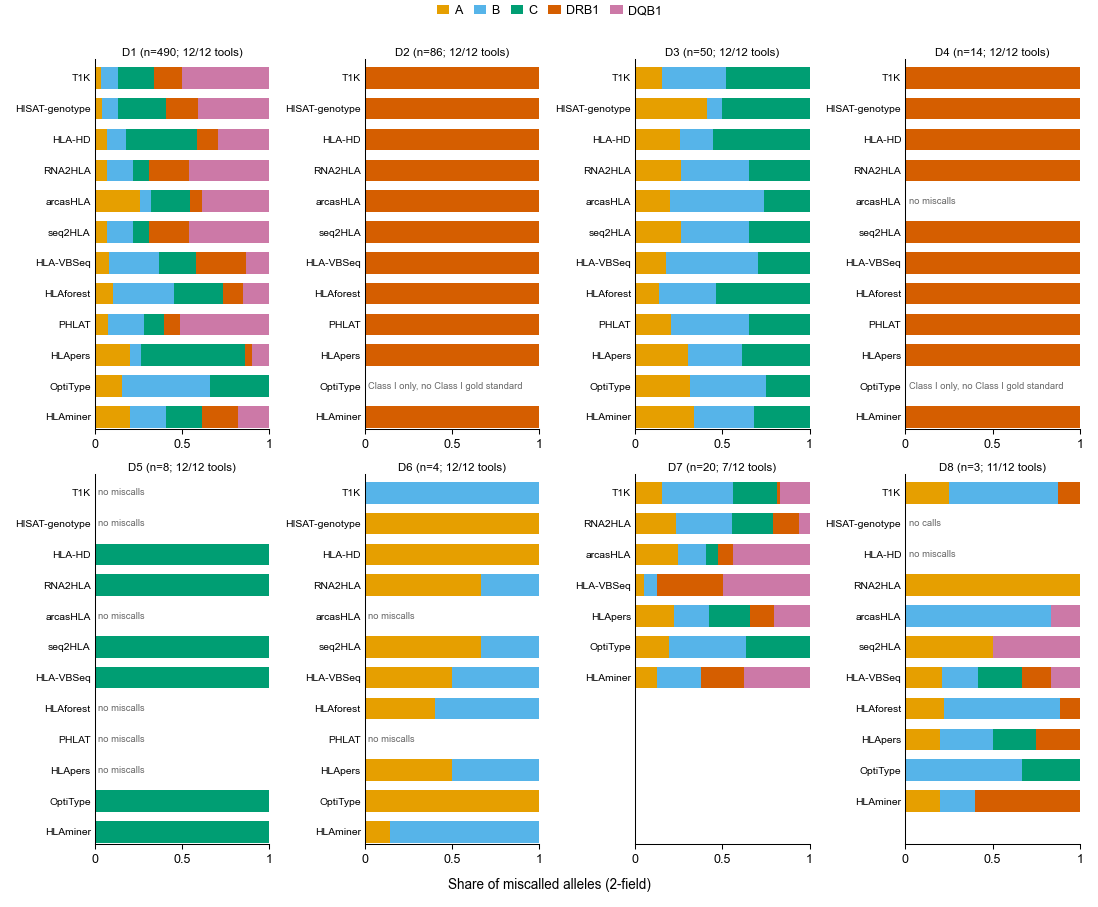

D7: Not shown (nothing scorable): seq2hla (no predictions), phlat (no predictions), hlahd (no predictions), hisat (no predictions), hlaforest (no predictions)
D8: Not shown (nothing scorable): phlat (no predictions)


wrote ../data/final/per_dataset_accuracy.csv 192 rows


In [63]:
fig, axes = pd_grid(150)
for ax, ds in zip(axes.flat, PD_DATASETS):
    pd_draw_bulk(ax, ds)
fig.supxlabel("Accuracy", fontsize=6.5)
fig.legend(*axes.flat[0].get_legend_handles_labels(), loc="outside upper center", ncol=2)
save_fig(fig, "figS_per_dataset_accuracy")
plt.show()

fig, axes = pd_grid(150)
for ax, ds in zip(axes.flat, PD_DATASETS):
    im = pd_draw_locus(ax, ds)
style_cbar(fig.colorbar(im, ax=axes, location="bottom", shrink=0.4, aspect=40), "Accuracy (2-field)")
save_fig(fig, "figS_per_dataset_locus_accuracy")
plt.show()

fig, axes = pd_grid(150)
for ax, ds in zip(axes.flat, PD_DATASETS):
    pd_draw_miscall_share(ax, ds)
fig.supxlabel("Share of miscalled alleles (2-field)", fontsize=6.5)
fig.legend(*locus_handles(), loc="outside upper center", ncol=5)
save_fig(fig, "figS_per_dataset_miscall_share")
plt.show()

for _ds in PD_DATASETS:
    _note = pd_note(_ds)
    if _note:
        print(f"D{_ds}: " + _note.replace("\n", " | "))

_acc_rows = []
for _ds in PD_DATASETS:
    for _res in (1, 2):
        _ca = pd_class_acc(_ds, _res)
        for _t in PD_TOOLS:
            _r = _ca.loc[_t] if _t in _ca.index else None
            _acc_rows.append(dict(Dataset=_ds, N=PD_N_SAMPLES[_ds], Resolution=f"{_res}-field",
                                  Tool=_t, ToolStatus=pd_status(_ds, _t), NMatched=pd_matched(_ds, _t),
                                  Overall=(np.nan if _r is None else _r["Overall"]),
                                  ClassI=(np.nan if _r is None else _r["ClassI_acc"]),
                                  ClassII=(np.nan if _r is None else _r["ClassII_acc"])))
pd.DataFrame(_acc_rows).to_csv(f"{PD_OUT_RES}/per_dataset_accuracy.csv", index=False, float_format="%.6f")
print("wrote", f"{PD_OUT_RES}/per_dataset_accuracy.csv", len(_acc_rows), "rows")


## D7 scRNA-seq performance summary

Computes D7 (3' scRNA-seq, n=20) summary accuracy using the same `compute_locus_metrics()` as the main results tables, restricted to dataset 7.


In [64]:
# D7 overall + per-locus accuracy, 1-field and 2-field, via compute_locus_metrics().
d7_tools = ["arcas", "optitype", "seq2hla", "hlaminer", "phlat", "hlavbseq",
            "hlahd", "hisat", "hlaforest", "hlapers", "T1K", "rna2hla"]

d7_locus_1f = compute_locus_metrics(d7_tools, [7], resolution=1)
d7_locus_2f = compute_locus_metrics(d7_tools, [7], resolution=2)

def _overall_from_locus(df):
    g = df.groupby("Tool")[["CorrectAlleles", "TotalAlleles"]].sum()
    g = g[g["TotalAlleles"] > 0].copy()
    g["Accuracy"] = g["CorrectAlleles"] / g["TotalAlleles"]
    return g.sort_values("Accuracy", ascending=False)

d7_overall_1f = _overall_from_locus(d7_locus_1f)
d7_overall_2f = _overall_from_locus(d7_locus_2f)

print("D7 (n=20) overall accuracy, 1-field, by tool (tools with no data/interim/standard/{tool}_d7.csv are silently absent):")
print(d7_overall_1f.round(3))
print()
print("D7 (n=20) overall accuracy, 2-field, by tool:")
print(d7_overall_2f.round(3))
print()
print("D7 (n=20) per-locus accuracy, 2-field:")
d7_locus_2f_acc = d7_locus_2f.pivot(index="Tool", columns="Locus", values="Accuracy")
print(d7_locus_2f_acc.round(3))

d7_locus_1f.to_csv("../../data/final/d7_locus_accuracy_1field.csv", index=False)
d7_locus_2f.to_csv("../../data/final/d7_locus_accuracy_2field.csv", index=False)
d7_overall_1f.to_csv("../../data/final/d7_overall_accuracy_1field.csv")
d7_overall_2f.to_csv("../../data/final/d7_overall_accuracy_2field.csv")


D7 (n=20) overall accuracy, 1-field, by tool (tools with no data/interim/standard/{tool}_d7.csv are silently absent):
          CorrectAlleles  TotalAlleles  Accuracy
Tool                                            
T1K                  192           200     0.960
hlapers              160           200     0.800
rna2hla              111           200     0.555
arcas                 87           200     0.435
hlavbseq              60           200     0.300
optitype              58           200     0.290
hlaminer              28           200     0.140

D7 (n=20) overall accuracy, 2-field, by tool:
          CorrectAlleles  TotalAlleles  Accuracy
Tool                                            
T1K                  141           200     0.705
rna2hla               83           200     0.415
hlapers               82           200     0.410
optitype              49           200     0.245
arcas                 39           200     0.195
hlavbseq              23           200     0.115
hl

## D1-subset unmapped-reads-augmented performance

Scores the D1 unmapped-reads-augmented subset (`data/interim/unmapped/*.csv`), which needed per-tool format fixes first (T1K's `HLA-` prefix, HLAforest's `:` instead of `*`, HLApers' `IMGT_` prefix, HLAminer's missing header) since these files were never run through the standard pipeline. HLA-HD is excluded -- its raw output has a different, un-trimmed column layout that isn't safe to guess-map.


In [65]:
# Baseline (mapped-only) vs unmapped-augmented accuracy, D1 subset (n=20).

def score_df_against_gs(gs_df, pr_df, resolution=2):
    """Like score_against_gs, but takes an already-loaded/cleaned pr_df (not a path)."""
    id_gs, id_pr = gs_df.columns[0], pr_df.columns[0]
    gs_df = gs_df.copy()
    gs_df[id_gs] = gs_df[id_gs].str.strip()
    pr_df = pr_df.copy()
    pr_df[id_pr] = pr_df[id_pr].astype(str).str.strip()
    pr_df = pr_df.rename(columns={c: f"{c}_pre" for c in pr_df.columns if c != id_pr})
    loci = get_dynamic_loci(gs_df)
    merged = pd.merge(gs_df, pr_df, left_on=id_gs, right_on=id_pr, how="inner")
    correct = total = 0
    for _, row in merged.iterrows():
        for L in loci:
            gs_raw = []
            for suf in ("", ".1"):
                col = f"{L}{suf}"
                if col in row and pd.notna(row[col]):
                    gs_raw += [x.strip() for x in str(row[col]).split("/")]
            if not gs_raw:
                continue
            pr_raw = []
            for suf in ("_pre", ".1_pre"):
                col = f"{L}{suf}"
                if col in row and pd.notna(row[col]):
                    pr_raw += [x.strip() for x in str(row[col]).split("/")]
            result = score_pair(gs_raw, pr_raw, resolution)
            if result is None:
                continue
            c, m, nc = result
            total += 2
            correct += c
    return correct, total, merged.shape[0]

# ---- per-tool raw-unmapped-file loaders -----------------------------------
# These 20-sample "unmapped" prediction files were never run through this
# project's data/interim/standard/ pipeline (scripts/standardization/), so
# several keep each tool's own native allele-string convention. Verified by
# direct comparison against each tool's data/interim/standard/{tool}_d1.csv:
UNMAPPED_DIR = "../../data/interim/unmapped"

def _load_plain(path):
    return pd.read_csv(path, dtype=str)

def _load_t1k_unmapped(path):
    # Native T1K output prefixes every allele with "HLA-" (confirmed against
    # scripts/standardization/t1k_standardize.py's own documented
    # parsing step 1: "Strip an optional leading HLA- from each allele token").
    # The file also contains, for every sample, one all-"." placeholder row in
    # addition to the real-calls row (verified: all 20 samples have exactly
    # one of each, no ambiguous cases) -- the placeholder rows are dropped.
    df = pd.read_csv(path, dtype=str)
    id_col = df.columns[0]
    allele_cols = df.columns[1:]
    is_placeholder = (df[allele_cols] == ".").all(axis=1)
    df = df[~is_placeholder].copy()
    for c in allele_cols:
        df[c] = df[c].str.replace(r"^HLA-", "", regex=True)
    return df

def _load_hlaforest_unmapped(path):
    # Native HLAforest output uses "A:24:02" (colon) instead of "A*24:02"
    # (verified: zero "*" characters anywhere in the raw file). Replace only
    # the first colon (the gene/field-1 separator) with "*", keeping the
    # remaining colon(s) between subsequent fields untouched.
    df = pd.read_csv(path, dtype=str)
    id_col = df.columns[0]
    allele_cols = df.columns[1:]
    for c in allele_cols:
        df[c] = df[c].str.replace(r"^([A-Za-z0-9]+):", r"\1*", regex=True)
    return df

def _load_hlapers_unmapped(path):
    # Native HLApers output prefixes every allele with "IMGT_" (verified:
    # exactly 200/200 = 20 samples x 10 slots have the prefix).
    df = pd.read_csv(path, dtype=str)
    allele_cols = df.columns[1:]
    for c in allele_cols:
        df[c] = df[c].str.replace(r"^IMGT_", "", regex=True)
    return df

def _load_hlaminer_unmapped(path):
    # File has NO header row at all -- row 1 is a garbage "0,0,...,0" line,
    # row 2 onward is already real per-sample data in the same column order
    # as data/interim/standard/hlaminer_d1.csv (ID,A,A.1,B,B.1,C,C.1,DQB1,DQB1.1,
    # DRB1,DRB1.1). Skip the garbage line and supply that header explicitly.
    cols = ["ERR", "A", "A.1", "B", "B.1", "C", "C.1", "DQB1", "DQB1.1", "DRB1", "DRB1.1"]
    return pd.read_csv(path, dtype=str, skiprows=1, names=cols)

UNMAPPED_LOADERS = {
    "arcas":     ("arcas_umapped.csv",      _load_plain),
    "optitype":  ("optitype_unmapped.csv",  _load_plain),
    "seq2hla":   ("seq2hla_umapped.csv",    _load_plain),
    "hlaminer":  ("hlaminer_unmapped.csv",  _load_hlaminer_unmapped),
    "phlat":     ("phlat_unmapped.csv",     _load_plain),
    "hlavbseq":  ("hlavbseq_unmapped.csv",  _load_plain),
    # hlahd_unmapped.csv excluded: its column layout is shifted/untrimmed, not
    # safe to guess-map.
    "hlaforest": ("hlaforest_umapped.csv",  _load_hlaforest_unmapped),
    "hlapers":   ("hlapers_unmapped.csv",   _load_hlapers_unmapped),
    "rna2hla":   ("rna2hla_umapped.csv",    _load_plain),
    "T1K":       ("t1k_unmapped.csv",       _load_t1k_unmapped),
}

UNMAPPED_SAMPLES = [l.strip() for l in open("../../data/input/accessions/unmapped_accessions.txt") if l.strip()]

gs_full = pd.read_csv("../../data/gold_standard/1_gs.csv", dtype=str)
gs_full[gs_full.columns[0]] = gs_full[gs_full.columns[0]].str.strip()
gs_sub = gs_full[gs_full[gs_full.columns[0]].isin(UNMAPPED_SAMPLES)].reset_index(drop=True)
print(f"Unmapped-experiment D1 subset: {len(UNMAPPED_SAMPLES)} accessions requested, "
      f"{len(gs_sub)} found in the D1 gold standard.")
print()

import os
rows = []
for tool, (fname, loader) in UNMAPPED_LOADERS.items():
    baseline_path = f"../../data/interim/standard/{tool}_d1.csv"
    unmapped_path = os.path.join(UNMAPPED_DIR, fname)
    if not (os.path.exists(baseline_path) and os.path.exists(unmapped_path)):
        continue
    pr_unmapped = loader(unmapped_path)
    for res in (1, 2):
        bc, bt, bn = score_df_against_gs(gs_sub, pd.read_csv(baseline_path, dtype=str), resolution=res)
        uc, ut, un = score_df_against_gs(gs_sub, pr_unmapped, resolution=res)
        rows.append({
            "Tool": tool, "Resolution": f"{res}-field",
            "BaselineAcc": bc / bt if bt else None, "BaselineN": bn,
            "UnmappedAcc": uc / ut if ut else None, "UnmappedN": un,
            "DeltaPP": (uc / ut - bc / bt) * 100 if bt and ut else None,
        })

df_unmapped_cmp = pd.DataFrame(rows)
print(df_unmapped_cmp.round(3).to_string(index=False))

df_unmapped_cmp.to_csv("../../data/final/d1_unmapped_vs_baseline.csv", index=False)


Unmapped-experiment D1 subset: 20 accessions requested, 20 found in the D1 gold standard.



     Tool Resolution  BaselineAcc  BaselineN  UnmappedAcc  UnmappedN  DeltaPP
    arcas    1-field        1.000         20        1.000         20    0.000
    arcas    2-field        0.960         20        0.970         20    1.000
 optitype    1-field        0.600         20        0.550         20   -5.000
 optitype    2-field        0.600         20        0.510         20   -9.000
  seq2hla    1-field        0.970         20        0.962         16   -0.750
  seq2hla    2-field        0.950         20        0.706         16  -24.375
 hlaminer    1-field        0.240         20        0.361         18   12.111
 hlaminer    2-field        0.035         20        0.150         18   11.500
    phlat    1-field        0.935         20        0.990         20    5.500
    phlat    2-field        0.860         20        0.930         20    7.000
 hlavbseq    1-field        0.985         20        0.985         20    0.000
 hlavbseq    2-field        0.865         20        0.860       

# Figure 14: No-Call Rate Analysis

No-call rate measures the share of alleles a tool couldn't predict at all, shown by tool (14a) and by tool x locus (14b).


In [66]:
# Figure 14: Data Preparation (no-call rate, panels a/b)

# Define Class I-only tools (should not be penalized for Class II no-calls)
CLASS_I_ONLY_TOOLS = ['optitype']

# Get per-locus data for proper no-call calculation
by_tool = aggregate_counts_per_tool_locus(
    tools=tools,
    ds_nums=ds_nums,
    gs_dir=gs_dir,
    pr_dir=pr_dir,
    resolution=2,
)

# Prepare adjusted no-call summary (excluding Class II for Class I-only tools)
loci = ["A", "B", "C", "DRB1", "DQB1"]
class_I_loci = ["A", "B", "C"]
class_II_loci = ["DRB1", "DQB1"]

no_call_data = []
for tool in tools:
    total_no_calls = 0
    total_calls = 0

    for locus in loci:
        # Skip Class II loci for Class I-only tools
        if tool in CLASS_I_ONLY_TOOLS and locus in class_II_loci:
            continue

        total_calls += by_tool[tool][locus]['total_calls']
        total_no_calls += by_tool[tool][locus]['no_call']

    no_call_data.append({
        'Tool': tool,
        'TotalNoCall': total_no_calls,
        'TotalCalls': total_calls,
        'NoCallRate': (total_no_calls / total_calls * 100) if total_calls > 0 else 0
    })

no_call_summary = pd.DataFrame(no_call_data)
no_call_summary = no_call_summary.sort_values('NoCallRate', ascending=True)

# Prepare heatmap data (all tools, all loci - shows design by default)
heatmap_data = []
for tool in tools:
    row = {'Tool': tool}
    for locus in loci:
        total = by_tool[tool][locus]['total_calls']
        no_call = by_tool[tool][locus]['no_call']
        row[locus] = (no_call / total * 100) if total > 0 else 0
    heatmap_data.append(row)

heatmap_df = pd.DataFrame(heatmap_data)
heatmap_df = heatmap_df.set_index('Tool')
# Order by overall no-call rate (adjusted)
heatmap_df = heatmap_df.loc[no_call_summary['Tool']]

print("Data preparation complete for Figure 14")
print(f"No-call rates range: {no_call_summary['NoCallRate'].min():.1f}% - {no_call_summary['NoCallRate'].max():.1f}%")
print(f"\nNote: Class I-only tools ({', '.join(CLASS_I_ONLY_TOOLS)}) exclude Class II no-calls from overall rate")


Data preparation complete for Figure 14
No-call rates range: 0.0% - 1.5%

Note: Class I-only tools (optitype) exclude Class II no-calls from overall rate


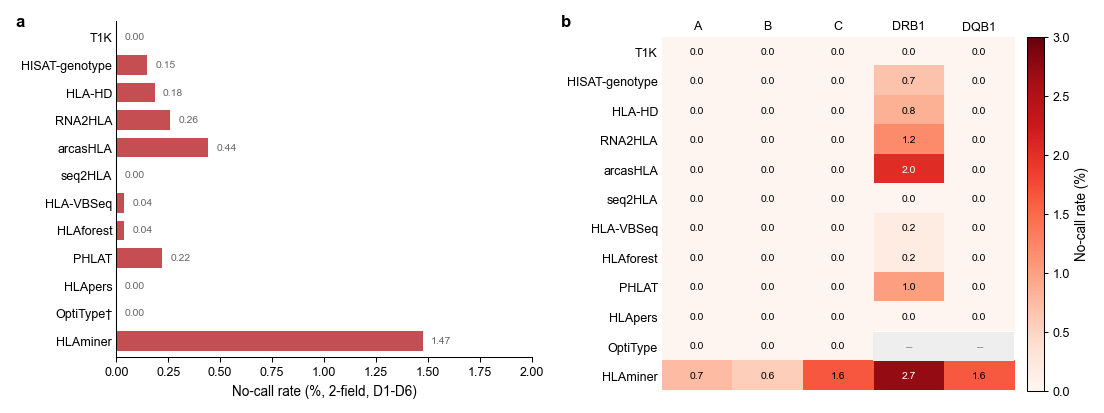

In [67]:
nc14 = no_call_summary.set_index("Tool")["NoCallRate"].reindex(TOOL_ORDER)
nc_loc14 = heatmap_df.reindex(index=TOOL_ORDER[::-1], columns=LOCI_ORDER)
nc_not_called14 = pd.DataFrame(False, index=nc_loc14.index, columns=nc_loc14.columns)
for t in CLASS_I_ONLY_TOOLS:
    nc_not_called14.loc[t, ["DRB1", "DQB1"]] = True


def draw_nocall_bars(ax):
    y = np.arange(len(nc14))
    ax.barh(y, nc14.values, height=0.7, color=palette["Miscalled"])
    for yi, v in zip(y, nc14.values):
        ax.text(v + 0.04, yi, f"{v:.2f}", va="center", ha="left", fontsize=5, color="#666666")
    ax.set_yticks(y, [TOOL_NAME[t] + ("\u2020" if t in CLASS_I_ONLY_TOOLS else "") for t in nc14.index])
    ax.tick_params(axis="y", length=0)
    ax.set_ylim(-0.6, len(nc14) - 0.4)
    ax.set_xlim(0, float(np.ceil(nc14.max() + 0.5)))
    ax.set_xlabel("No-call rate (%, 2-field, D1-D6)")


fig = plt.figure(figsize=(COL2, 66 * MM), layout="constrained")
sf_a, sf_b = fig.subfigures(1, 2, width_ratios=[1, 1])
draw_nocall_bars(sf_a.subplots())
ax_b, cax = sf_b.subplots(1, 2, width_ratios=[1, 0.05])
nc_max = float(np.ceil(np.nanmax(nc_loc14.mask(nc_not_called14).values)))
im = draw_matrix(ax_b, nc_loc14, nc_not_called14, "Reds", 0, nc_max, fmt=".1f",
                 white_if=lambda v: v > 0.6 * nc_max)
style_cbar(sf_b.colorbar(im, cax=cax), "No-call rate (%)")
label_panel(sf_a, "a")
label_panel(sf_b, "b")
save_fig(fig, "Figure14")
save_fig(fig, "fig14_nocall_rate")
plt.show()


Panel a excludes Class II for Class I-only callers (\u2020); panel b shows those cells as not called rather than 100% no-call.


## Figure 14 Interpretation

No-calls are rare (< 3% for every caller) and concentrated in DRB1; errors are dominated by miscalls, not abstentions (compare Figure 4).


# Main figures

The paper's main figures, assembled from the panels above (same drawing functions, so a panel looks the same here and in its single-figure file). Main Figure 1 (study design and scoring) is a schematic and is not drawn here. 2: how accurate the callers are; 3: where the errors are; 4: what accuracy depends on.

In [ ]:
# Main Figure 2: how accurate the callers are (D1-D6)
fig = plt.figure(figsize=(COL2, 150 * MM), layout="constrained")
row1, row2 = fig.subfigures(2, 1, height_ratios=[1, 1])
sf_a, sf_b = row1.subfigures(1, 2, width_ratios=[1, 1.1])
sf_c, sf_d = row2.subfigures(1, 2, width_ratios=[1, 1.1])
draw_bulk_accuracy(sf_a.subplots())
ax_I, ax_II = sf_b.subplots(1, 2, sharey=True)
draw_class_accuracy(ax_I, ax_II, legend=False)
draw_call_fractions(sf_c.subplots())
ax_d, cax_d = sf_d.subplots(1, 2, width_ratios=[1, 0.04])
draw_locus_heatmap(ax_d, cax_d)
for sf, letter in ((sf_a, "a"), (sf_b, "b"), (sf_c, "c"), (sf_d, "d")):
    label_panel(sf, letter)
save_fig(fig, "MainFigure2")
plt.show()

# Main Figure 3: where the errors are
fig = plt.figure(figsize=(COL2, 170 * MM), layout="constrained")
row1, row2, row3 = fig.subfigures(3, 1, height_ratios=[0.9, 1.15, 0.75])
sf_a, sf_b = row1.subfigures(1, 2, width_ratios=[1.15, 1])
draw_miscall_counts(sf_a.subplots())
draw_nocall_bars(sf_b.subplots())
ax_c, ax_d, cax_d = row2.subplots(1, 3, width_ratios=[0.75, 1.3, 0.035])
draw_hard_alleles(ax_c)
draw_allele_tool_heatmap(ax_d, cax_d)
ax_e1, ax_e2 = row3.subplots(1, 2, width_ratios=[0.8, 1.6])
draw_focus_calls(ax_e1)
draw_reference_map(ax_e2)
label_panel(sf_a, "a")
label_panel(sf_b, "b")
label_panel(row2, "c")
ax_d.annotate("d", xy=(0, 1), xycoords="axes fraction", xytext=(-6, 10), textcoords="offset points",
              fontsize=8, fontweight="bold", ha="right", va="bottom")
label_panel(row3, "e")
save_fig(fig, "MainFigure3")
plt.show()

# Main Figure 4: what accuracy depends on
fig = plt.figure(figsize=(COL2, 150 * MM), layout="constrained")
row1, row2 = fig.subfigures(2, 1, height_ratios=[1, 1.05])
draw_readlength_grid(row1)
sf_b, sf_c = row2.subfigures(1, 2, width_ratios=[1.75, 1])
axes_b = sf_b.subplots(1, 3, sharey=True)
h, l = draw_ancestry_row(axes_b, 2)
sf_b.legend(h, l, loc="outside upper center", ncol=2, handletextpad=0.2)
draw_celltype(sf_c.subplots(), "2-field")
for sf, letter in ((row1, "a"), (sf_b, "b"), (sf_c, "c")):
    label_panel(sf, letter)
save_fig(fig, "MainFigure4")
plt.show()